In [1]:
import numpy as np
from PIL import Image
import pandas as pd
import cv2
import os 
import matplotlib.pyplot as plt
import pydicom

# Read the CSV file from specifix path in external CD
breast_level_annotations = pd.read_csv('E:/PhD/V_M_Dataset/breast-level_annotations.csv')
# Read the CSV file
finding_annotations = pd.read_csv('E:/PhD/V_M_Dataset/finding_annotations.csv')
metadata = pd.read_csv('E:/PhD/V_M_Dataset/metadata.csv')
#for our interes we create the new DB with important columns in owr interes.
selected_columns_BLA = breast_level_annotations[[ 'study_id' , 'series_id', 'image_id', 'breast_birads', 'split','laterality' , 'view_position', 'breast_density']]

metadata.head()

,SOP Instance UID,Series Instance UID,SOP Instance UID.1,Patient's Age,View Position,Image Laterality,Photometric Interpretation,Rows,Columns,Imager Pixel Spacing,...,Pixel Padding Value,Pixel Padding Range Limit,Window Center,Window Width,Rescale Intercept,Rescale Slope,Rescale Type,Window Center & Width Explanation,Manufacturer,Manufacturer's Model Name
0,d8125545210c08e1b1793a5af6458ee2,b36517b9cbbcfd286a7ae04f643af97a,d8125545210c08e1b1793a5af6458ee2,053Y,CC,L,MONOCHROME2,3518,2800,"[0.085, 0.085]",...,0,NaN,1662,1500,0,1,US,linear LUT,SIEMENS,Mammomat Inspiration
1,290c658f4e75a3f83ec78a847414297c,b36517b9cbbcfd286a7ae04f643af97a,290c658f4e75a3f83ec78a847414297c,053Y,MLO,L,MONOCHROME2,3518,2800,"[0.085, 0.085]",...,0,NaN,1664,1500,0,1,US,linear LUT,SIEMENS,Mammomat Inspiration
2,cd0fc7bc53ac632a11643ac4cc91002a,b36517b9cbbcfd286a7ae04f643af97a,cd0fc7bc53ac632a11643ac4cc91002a,053Y,CC,R,MONOCHROME2,3518,2800,"[0.085, 0.085]",...,0,NaN,1600,1500,0,1,US,linear LUT,SIEMENS,Mammomat Inspiration
3,71638b1e853799f227492bfb08a01491,b36517b9cbbcfd286a7ae04f643af97a,71638b1e853799f227492bfb08a01491,053Y,MLO,R,MONOCHROME2,3518,2800,"[0.085, 0.085]",...,0,NaN,1654,1500,0,1,US,linear LUT,SIEMENS,Mammomat Inspiration
4,dd9ce3288c0773e006a294188aadba8e,d931832a0815df082c085b6e09d20aac,dd9ce3288c0773e006a294188aadba8e,042Y,CC,L,MONOCHROME2,3518,2800,"[0.085, 0.085]",...,0,NaN,1580,1500,0,1,US,linear LUT,SIEMENS,Mammomat Inspiration


### Function which delete text (Labels) posible writen in images

In [2]:

def delete_text_writen_in_image(image, window_size=(500, 500)):
    # check for images -> grayscale
    if len(image.shape) == 3:
        gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    else:
        gray_image = image.copy()

    h, w = gray_image.shape

    # Dritaret
    top_left = gray_image[:window_size[0], :window_size[1]]
    top_right = gray_image[:window_size[0], w-window_size[1]:]

    # Gjej vlerat maksimale në secilën dritare
    max_left = np.max(top_left)
    max_right = np.max(top_right)

    # Kontrollo nëse të gjithë pikselat janë të barabartë me max
    if np.all(top_left == max_left):
        gray_image[:window_size[0], :window_size[1]] = 0

    if np.all(top_right == max_right):
        gray_image[:window_size[0], w-window_size[1]:] = 0

    return gray_image


### Function which delete big begraund, -> crop to ROI_1

In [3]:

def crop_to_roi(original_image, return_mask=False):
    """
    Bën crop një imazh mammografik bazuar në zonën ROI më të madhe (pikselat >0).

    Parameters:
        original_image (ndarray): Imazhi grayscale (jo RGB).
        return_mask (bool): Nëse është True, kthen edhe maskën e crop-uar.

    return :
        cropped_image (ndarray): Imazhi i crop-uar.
        cropped_mask (ndarray, opsionale): Maskë e crop-uar nëse return_mask=True.
    """
    # Krijo maskën binare nga imazhi
    _, binary_mask = cv2.threshold(original_image, 1, 255, cv2.THRESH_BINARY)

    # Sigurohu që maska është binare
    mask = (binary_mask > 0).astype(np.uint8)

    # Identifiko komponentët e lidhur
    num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(mask, connectivity=8)

    if num_labels <= 1:
        # Vetëm background = 0
        raise ValueError("Maska nuk ka zona aktive (ROI).")

    # Gjej komponentin me sipërfaqen më të madhe (përveç background)
    largest_idx = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])

    x, y, w, h, area = stats[largest_idx]

    # Crop imazhin origjinal
    cropped_image = original_image[y:y+h, x:x+w]

    if return_mask:
        cropped_mask = binary_mask[y:y+h, x:x+w]
        return cropped_image, cropped_mask

    return cropped_image


### Function which create histograme for images

In [4]:
def histogram(image):
    """
    Llogarit histogramin e një imazhi grayscale nga 1 deri në 255.
    Kthen listë tuplesh (intensitet, frekuencë).
    """
    # Sigurohemi që është grayscale
    if len(image.shape) != 2:
        raise ValueError("Input duhet të jetë imazh bardh e zi (grayscale)")

    # Llogarit histogramin me bins fikse nga 1 në 255
    counts, bins = np.histogram(image, bins=np.arange(1, 257))  # 1–255 (256 është kufiri i sipërm)
    
    # Kombino në tuple (intensitet, numërim)
    H = list(zip(bins[:-1].astype(int), counts.tolist()))
    
    return H


### Function used to calculate Shanon Entropy


In [5]:
def shannon_entropy(arr, bins=256):
    """
    Compute Shannon entropy of a NumPy array.
    Parameters:
        arr : np.ndarray
            Input array (e.g., image or feature values).
        bins : int
            Number of bins for histogram (default 256).
    Returns:
        entropy : float
    """
    # Flatten the array
    arr = arr.ravel()
    arr = arr[(arr >= 1)]


    # Compute histogram (probability distribution)
    hist, _ = np.histogram(arr, bins=bins, density=True)
    
    # Avoid log(0) by filtering zeros
    hist = hist[hist > 0]

    # Shannon entropy
    entropy = -np.sum(hist * np.log2(hist))
    return entropy

### Function used to create poliogon in image and to extract region inside this poligon -> ROI_2

In [24]:
from skimage import data
from matplotlib.path import Path

def vizato_poligon_dhe_mask(image):
    """
    Merr një imazh bardh e zi (numpy array),
    llogarit pikat k, p, q, l, s, vizaton poligonin,
    dhe kthen imazhin e maskuar vetëm brenda poligonit.
    """
    N, M = image.shape
    mea = N // 2   # rreshti i mesit
    
    # --------------------
    # Gjetja e k, p, q
    # --------------------
    threshold = 0
    # k: pika e parë ≠ 0 kur ecim në rreshtin N/2 nga e djathta
    k = None
    row_mid = image[mea, :]
    for j in range(M-1, -1, -1):
        if row_mid[j] > threshold:
            k = j+1 if j < M-1 else M
            break
    if k is None:
        k = M // 2   # default fallback
    
    # p: pozicioni i parë ≠ 0 në kolonën M/2 nga lart
    p = None
    col_mid = image[:, M//2]
    for i in range(N):
        if col_mid[i] > threshold:
            p = i
            break
    if p is None:
        p = N // 4   # fallback
    
    # q: pozicioni i parë ≠ 0 në kolonën M/2 nga fundi
    q = None
    for i in range(mea, N-3):
        if col_mid[i] == threshold:
            q = i
            break
    if q is None:
        q = 3 * N // 4   # fallback
    
    # l: pika e parë ≠ 0 kur ecim në rreshtin f = (N/2+p)//2 nga e djathta
    f = (mea + p) // 2
    l = None
    row_f = image[f, :]
    for j in range(M-1, -1, -1):
        if row_f[j] > threshold:
            l = j+1 if j < M-1 else M
            break
    if l is None:
        l = M // 2   # fallback
    
    # s: pika e parë ≠ 0 kur ecim në rreshtin g = (q+N/2)//2 nga e djathta
    g = (q + mea) // 2
    s = None
    row_g = image[g, :]
    for j in range(M-1, -1, -1):
        if row_g[j] > threshold:
            s = j+1 if j < M-1 else M
            break
    if s is None:
        s = M // 2   # fallback

    #print(f"k = {k}, p = {p}, q = {q}, l = {l}, s = {s}")

    # --------------------
    #  poligon creation
    # --------------------
    polygon = np.array([
        [mea, 0],
        [p, M//4],
        [p, M//2],
        [(mea+p)//2, l],
        [mea, k],
        [(q+mea)//2, s],
        [q, M//2],
        [q, M//4],
        [mea, 0]
    ])

    # --------------------
    # Krijimi i maskës
    # --------------------
    Y, X = np.mgrid[:N, :M]
    points = np.vstack((Y.flatten(), X.flatten())).T
    path = Path(polygon[:, [0, 1]])  # kujdes renditja (row, col) -> (y, x)
    mask = path.contains_points(points).reshape(N, M)

    # aplikojmë maskën mbi imazh
    masked_image = np.zeros_like(image)
    masked_image[mask] = image[mask]

    # --------------------
    # Vizualization
    # --------------------
    #plt.figure(figsize=(10,5))

    # image original + poligon
    #plt.subplot(1,2,1)
    #plt.imshow(image, cmap="gray")
    #plt.plot(polygon[:,1], polygon[:,0], 'r-', linewidth=2)
    #plt.title("Poligoni mbi imazh")

    # image i maskuar
    #plt.subplot(1,2,2)
    #plt.imshow(masked_image, cmap="gray")
    #plt.title("Imazhi i filtruar brenda poligonit")

    #plt.show()

    return masked_image


### Function created to check for negative images:

In [7]:
from collections import Counter

def Check_for_negativ_image(image):
    image = np.array(image)
    v = image[:, image.shape[1]-5]
    # Vlera më e shpeshtë
    mode_val, count = Counter(v).most_common(1)[0]
    perc = count / len(v) * 100
    #print(perc, mode_val)
    #print(v)
    if mode_val > 250:
        return  255 - image
    else:
        return image


In [8]:
# function used to plot histogram with quantizers thresholds
def plot_histogram_with_thresholds(H, q1, q, q2):

    values = np.array([v for (v, _) in H], dtype=float)
    counts = np.array([nv for (_, nv) in H], dtype=float)
    plt.figure(figsize=(10, 6))
    plt.bar(values, counts, color='gray', alpha=0.6, label='Histogram')

    #Threshold lines
    plt.axvline(q1, color='red', linestyle='--', linewidth=2, label=f'$Q_2$ = {q1}')
    plt.axvline(q, color='orange', linestyle='--', linewidth=2, label=f'$Q_1$ = {q}')
    plt.axvline(q2, color='green', linestyle='--', linewidth=2, label=rf'$Q^\prime_2$ = {q2}')

    plt.xlabel("Intensity")
    plt.ylabel("Frequency")
    plt.legend(fontsize=10)
    plt.grid(alpha=0.3)
    plt.show()


### Function Createt to calvulate Bimodality and extracted other features from images

small : bimodality(H)=

C:\Users\Perdorues\.conda\envs\pytorchenv\lib\site-packages\numba\core\ir_utils.py:2172: NumbaPendingDeprecationWarning: 
Encountered the use of a type that is scheduled for deprecation: type 'reflected list' found for argument 'H' of function 'bruteForceScalarQuantisation1'.

For more information visit https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-reflection-for-list-and-set-types

File "..\..\..\..\Users\Perdorues\AppData\Local\Temp\ipykernel_17184\2572265595.py", line 134:
<source missing, REPL/exec in use?>

  warnings.warn(NumbaPendingDeprecationWarning(msg, loc=loc))
C:\Users\Perdorues\.conda\envs\pytorchenv\lib\site-packages\numba\core\ir_utils.py:2172: NumbaPendingDeprecationWarning: 
Encountered the use of a type that is scheduled for deprecation: type 'reflected list' found for argument 'H' of function 'bruteForceScalarQuantisation2'.

For more information visit https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of

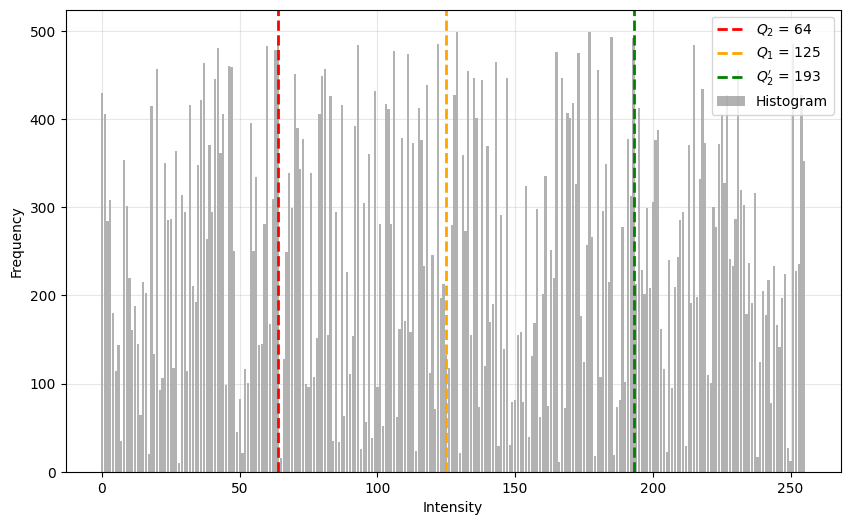

(0.5070645546783351, 0.3211458183388513, 0.18893211193374326, 6.710277865179449, 6.762482930433712, 6.762482930433712, 5.75982559860418, 5.783526422232214, 5.633189693390401, 5.7680320762354595, 5.75982559860418, 0.9740060444326994, 0.9985772482672053, 193)
medium : bimodality(H)=

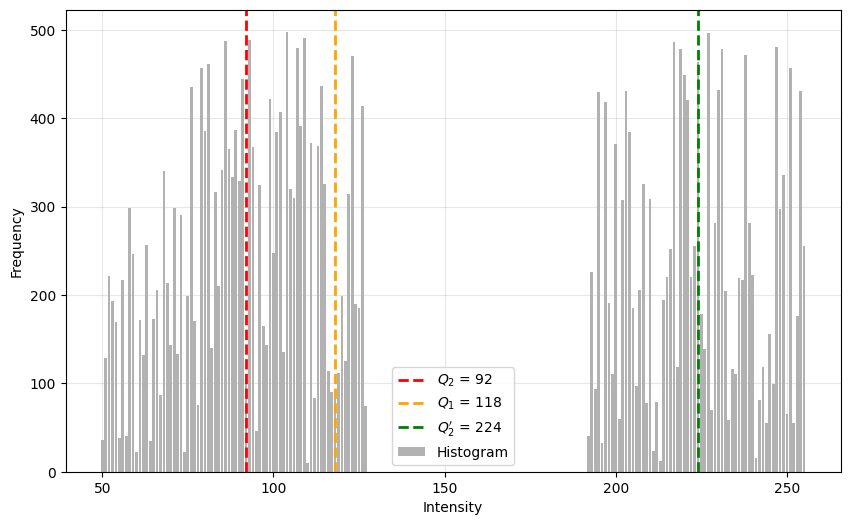

(0.7389339666204895, 0.04092087208415917, 0.0, 5.838999377237968, 5.881681922280049, 5.881681922280049, 4.633501420000193, 5.156688147909913, 4.454219396920622, 5.093741290904687, 4.633501420000193, 0.8637752117560158, 0.9096460058294888, 224)
high : bimodality(H)=

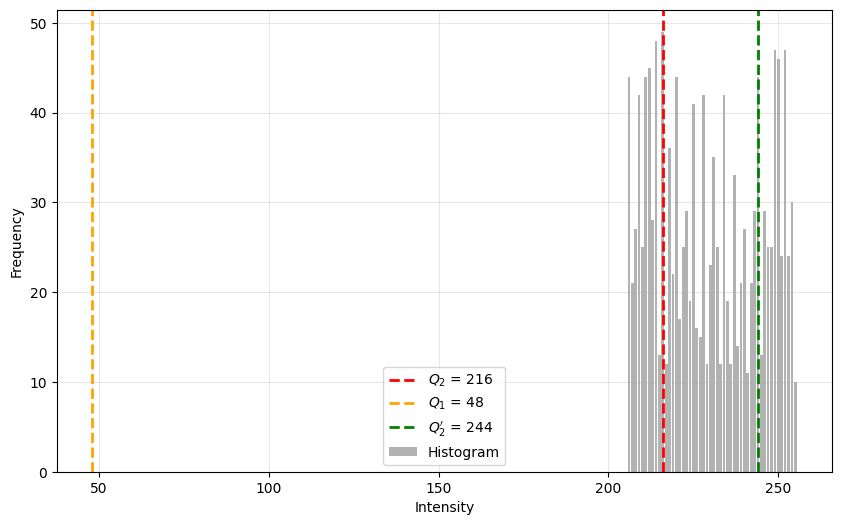

(0.9662368636804055, 0.0, 0.0, 0.0, 5.508297270036946, 5.508297270036946, 3.32849254622694, 3.3679275728575386, 0.0, 5.148818160722511, 3.32849254622694, 0.0, 0.6464575835321144, 244)


In [14]:
'''''Quantitative assessment of histogram's "bimodality" property.
One defines bimodality as the relative decrease of quantisation error between 
the 1-level and the 2-level quantisation of the histogram. 
Let E1star(H) be the 1-level quantisation error of histogram H and E2star(H) the 2-level one.
  
              Bimodality(H) = ( E1star(H) - E2star(H) ) / E1star


'''''

import random
from random import randrange
from scipy.stats import entropy  
from numba import jit

def bimodality(H):
    (E1, Q) = bruteForceScalarQuantisation1(H)
    (E2, Q1, Q2) = bruteForceScalarQuantisation2(H)
    DOL1, e1, e2 = DoL_1(Q, H)
    DOL2, e3, e4 = DoL_2(Q1, Q2, H)
    e__1, e__2, e__3, e__4, r_21, r_43 = entropy_split_4parts(H, Q, Q1, Q2)
    plot_histogram_with_thresholds(H, Q1, Q, Q2)
    return ((E1 - E2) / E1, DOL1, DOL2, e1, e2, e2, e4, e__1, e__2, e__3, e__4, r_21, r_43, Q2)


def DoL_1(q, H):  # DoL = "number of dark pixels" / "number of light pixels"
    #mean = (q1 + q2) // 2
    D = sum([nv for (v, nv) in H if v < q//2])  # amount of dark pixels
    L = sum([nv for (v, nv) in H if v > q//2])  # amount of light pixels
    e1, e2 = entropy_split_1q(H, q)
    return (D / L, e1, e2)


def DoL_2(q1, q2, H):  # DoL = "number of dark pixels" / "number of light pixels"
    #mean = (q1 + q2) // 2
    D = sum([nv for (v, nv) in H if v <= q1//2])  # amount of dark pixels
    L = sum([nv for (v, nv) in H if v >= q2//2])  # amount of light pixels
    e3, e4 = entropy_split_2q(H, q1, q2)
    return (D / L, e3, e4)


def entropy_split_2q(H, q1, q2):
    """
    Compute Shannon entropy of histogram in two parts:
    - 1 to k
    - k+1 to 255
    """
    # Convert histogram (list of tuples) to probabilities
    values = np.array([v for (v, _) in H], dtype=float)
    counts = np.array([nv for (_, nv) in H], dtype=float)

    # Normalize to probabilities
    p = counts / np.sum(counts)

    # Split histogram
    part1 = p[values <= q1]
    part2 = p[values > q2]
    
    # Avoid log(0)
    part1 = part1[part1 > 0]
    part2 = part2[part2 > 0]

    # Shannon entropy
    entropy_1 = entropy(part1, base=2)
    entropy_2 = entropy(part2, base=2)
    return entropy_1, entropy_2

def entropy_split_4parts(H, q, q1, q2):
        
    # Convert histogram (list of tuples) to probabilities
    values = np.array([v for (v, _) in H], dtype=float)
    counts = np.array([nv for (_, nv) in H], dtype=float)

    # Normalize to probabilities
    p = counts / np.sum(counts)

    # Split histogram from 0 to q
    part1 = p[values <= q1]
    part1 = part1[part1 > 0]
    entropy_1 = entropy(part1, base=2)
    if q1 == q:
        entropy_2 = 0
    else:
        part2 = p[(values > q1) & (values <= q)]
        part2 = part2[part2 > 0]
        entropy_2 = entropy(part2, base=2)
    
    # Split histogram from q to 255
    part4 = p[values > q2]
    part4 = part4[part4 > 0]
    entropy_4 = entropy(part4, base=2)
    if q2 == q:
        entropy_3 = 0
    else:
        part3 = p[(values > q) & (values <= q2)]
        part3 = part3[part3 > 0]
        entropy_3 = entropy(part3, base=2)
        
    if  entropy_3 == 0:
        R_4over3 = 6
    else:
        R_4over3 = entropy_4/entropy_3
        
    return entropy_1, entropy_2, entropy_3, entropy_4, entropy_2/entropy_1, R_4over3


def entropy_split_1q(H, q):
    """
    Compute Shannon entropy of histogram in two parts:
    - 1 to k
    - k+1 to 255
    """
    # Convert histogram (list of tuples) to probabilities
    values = np.array([v for (v, _) in H], dtype=float)
    counts = np.array([nv for (_, nv) in H], dtype=float)

    # Normalize to probabilities
    p = counts / np.sum(counts)

    # Split histogram
    part1 = p[values <= q]
    part2 = p[values > q]

    # Avoid log(0)
    part1 = part1[part1 > 0]
    part2 = part2[part2 > 0]

    # Shannon entropy
    entropy_1 = entropy(part1, base=2)
    entropy_2 = entropy(part2, base=2)

    return entropy_1, entropy_2

@jit(nopython = True)
def bruteForceScalarQuantisation1(H):
    Estar, qstar = np.inf, -1
    V = [v for (v, nv) in H]
    for q in range(0, len(V) - 1):
        E = sum([abs(v - q) * nv for (v, nv) in H])
        if E < Estar:
            qstar = q
            Estar = E
    return (Estar, qstar)

@jit(nopython = True)
def bruteForceScalarQuantisation2(H):
    EQstar, q1star, q2star = np.inf, -1, -1
    V = sorted([v for (v, nv) in H])
    for i in range(0, len(V) - 1):
        for j in range(i + 1, len(V)):
            q1, q2 = V[i], V[j]
            vmed = (q1 + q2) // 2
            EQ = sum([abs(v - q1) * nv for (v, nv) in H if v <= vmed]) + \
                 sum([abs(v - q2) * nv for (v, nv) in H if v > vmed])
            if EQ < EQstar:
                EQstar, q1star, q2star = EQ, q1, q2
    return (EQstar, q1star, q2star)


@jit(nopython=True)
def bruteForceScalarQuantisation3(H):
    E3star, q1star, q2star, q3star = np.inf, -1, -1, -1
    V = sorted([v for (v, nv) in H])
    n = len(V)
    
    # Try all combinations of three quantization levels
    for i in range(0, n - 2):
        for j in range(i + 1, n - 1):
            for k in range(j + 1, n):
                q1, q2, q3 = V[i], V[j], V[k]
                
                # Determine midpoints (decision boundaries)
                v1 = (q1 + q2) // 2
                v2 = (q2 + q3) // 2
                
                # Compute total quantization error
                E3 = 0.0
                for (v, nv) in H:
                    if v <= v1:
                        E3 += abs(v - q1) * nv
                    elif v <= v2:
                        E3 += abs(v - q2) * nv
                    else:
                        E3 += abs(v - q3) * nv
                        
                if E3 < E3star:
                    E3star, q1star, q2star, q3star = E3, q1, q2, q3
    
    return (E3star, q1star, q2star, q3star)


def threshold(H, t):
    return [(v, nv) for (v, nv) in H if v >= t]

def main():
    H = [(v, randrange(10, 500)) for v in range(256)]
    print("small : bimodality(H)=", end="")
    print(bimodality(H))

    H = [(v, randrange(10, 500)) for v in range(128)] + \
        [(v, randrange(10, 500)) for v in range(192, 256)]
    H = threshold(H, 50)
    print("medium : bimodality(H)=", end="")
    print(bimodality(H))

    H = [(v, randrange(10, 50)) for v in range(50)] + \
        [(v, randrange(10, 50)) for v in range(206, 256)]
    H = threshold(H, 50)
    print("high : bimodality(H)=", end="")
    print(bimodality(H))

main()


In [15]:
def bimodality2(H):
    (E1, Q) = bruteForceScalarQuantisation1(H)
    (E2, Q1, Q2) = bruteForceScalarQuantisation2(H)
    DOL3, e11, e22 = DoL_2(Q1, Q2, H)
    return ((E1 - E2) / E1, DOL1, DOL2, e11, e22)

### We selected images from the Mammomat Inspiration device, specifically those acquired in the CC modality.

In [16]:
#//////////////////////////////////////////////////////////////////////////
Mammomat_Inspiration= selected_columns_BLA.loc[metadata["Manufacturer's Model Name"] == 'Mammomat Inspiration']
selected_columns_BLA_CC = Mammomat_Inspiration.loc[Mammomat_Inspiration['view_position'] == 'CC']
#  ndarë sipas Density
Dens_A = selected_columns_BLA_CC.loc[selected_columns_BLA_CC['breast_density'] == 'DENSITY A']
Dens_B = selected_columns_BLA_CC.loc[selected_columns_BLA_CC['breast_density'] == 'DENSITY B']
Dens_C = selected_columns_BLA_CC.loc[selected_columns_BLA_CC['breast_density'] == 'DENSITY C']
Dens_D = selected_columns_BLA_CC.loc[selected_columns_BLA_CC['breast_density'] == 'DENSITY D']


100.0 0
[0 0 0 ... 0 0 0]
k = 1215, p = 244, q = 2314, l = 1266, s = 1058


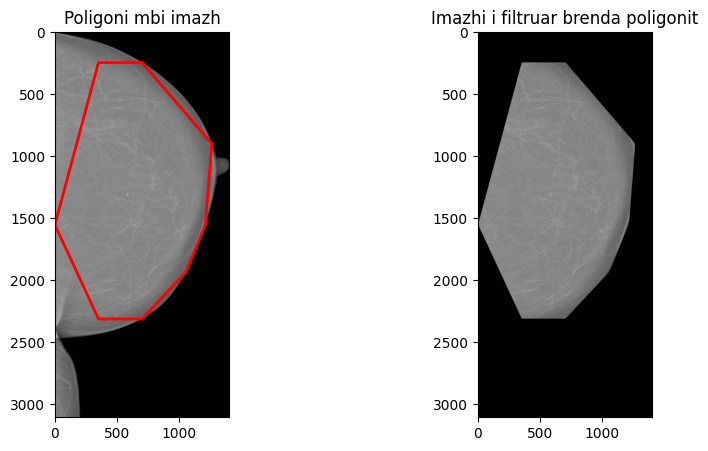

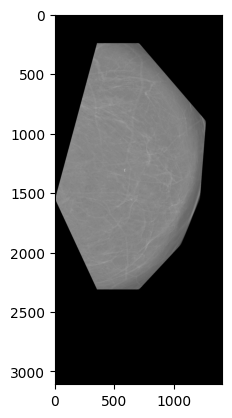

C:\Users\Perdorues\.conda\envs\pytorchenv\lib\site-packages\numba\core\ir_utils.py:2172: NumbaPendingDeprecationWarning: 
Encountered the use of a type that is scheduled for deprecation: type 'reflected list' found for argument 'H' of function 'bruteForceScalarQuantisation1'.

For more information visit https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-reflection-for-list-and-set-types

File "..\..\..\..\Users\Perdorues\AppData\Local\Temp\ipykernel_17184\2572265595.py", line 134:
<source missing, REPL/exec in use?>

  warnings.warn(NumbaPendingDeprecationWarning(msg, loc=loc))
C:\Users\Perdorues\.conda\envs\pytorchenv\lib\site-packages\numba\core\ir_utils.py:2172: NumbaPendingDeprecationWarning: 
Encountered the use of a type that is scheduled for deprecation: type 'reflected list' found for argument 'H' of function 'bruteForceScalarQuantisation2'.

For more information visit https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of

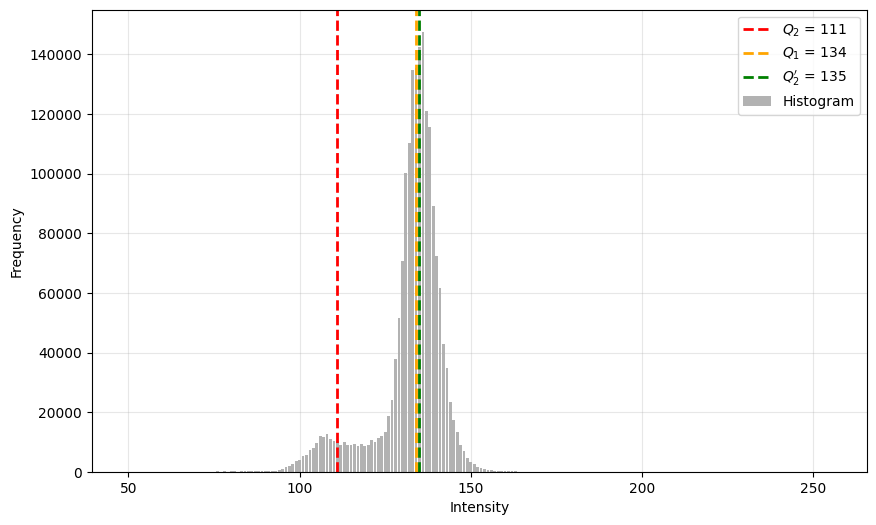

(0.34905989556981154, 0.00046067597741611367, 0.00015821754481888667, 4.321405565245881, 3.4915074193936295, 3.4915074193936295, 3.396341822327423, 4.0830440495065705, 3.7218047617085657, 0.0, 3.396341822327423, 0.9115269677676733, 6, 135)


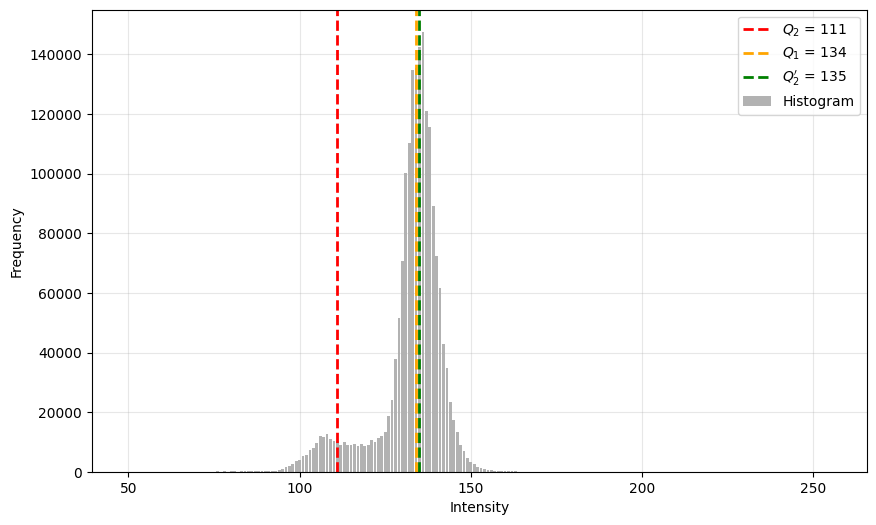

1
16.458214894826607 0
[  0   0   0 ... 148 148 149]
k = 1439, p = 226, q = 2478, l = 1355, s = 1295


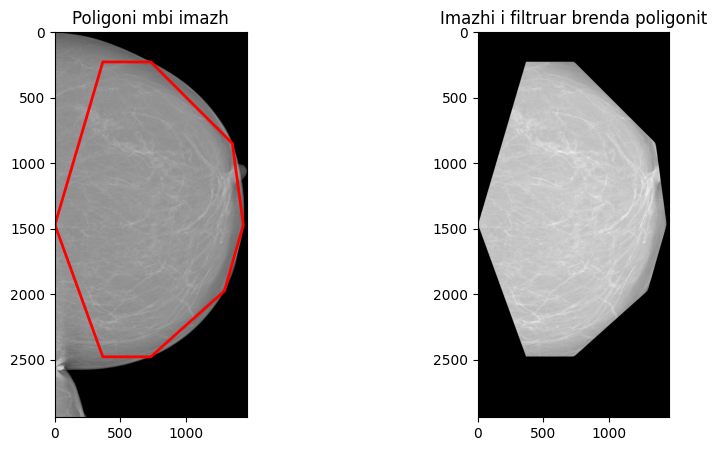

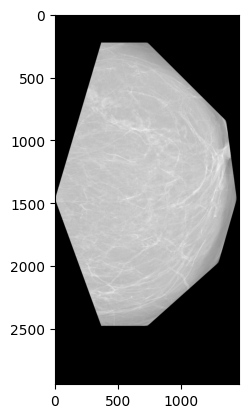

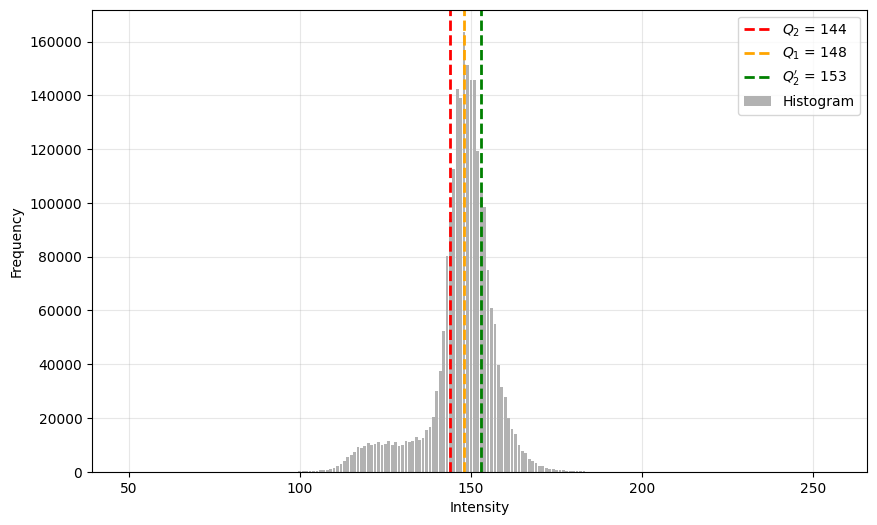

(0.2961388103773339, 6.898026773888322e-05, 6.334064643034243e-05, 4.310457323959625, 3.8213592936278147, 3.8213592936278147, 3.5693862794720483, 4.5527288539434405, 1.9876687949459795, 2.308258333708666, 3.5693862794720483, 0.43658844150675014, 1.5463547677252985, 153)


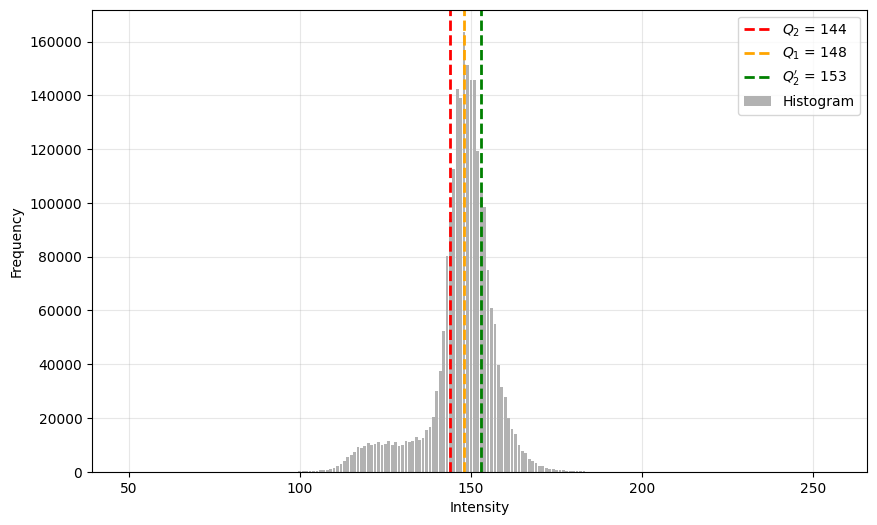

2
100.0 0
[0 0 0 ... 0 0 0]
k = 956, p = 487, q = 2430, l = 794, s = 977


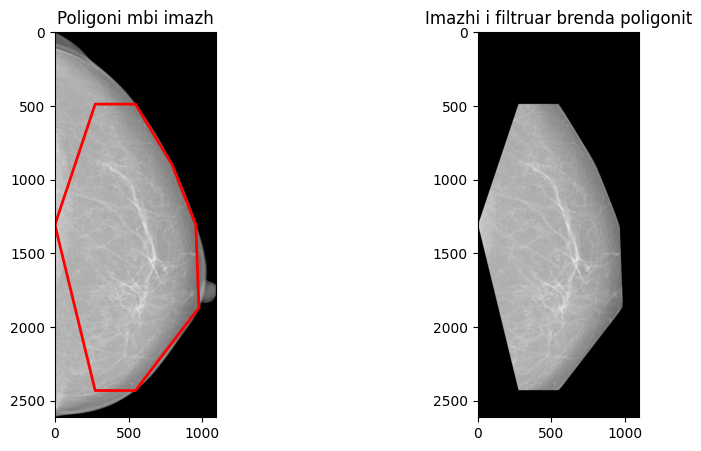

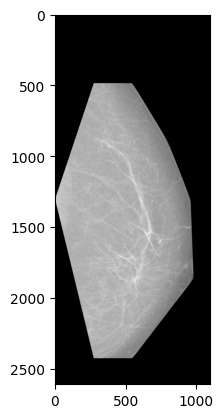

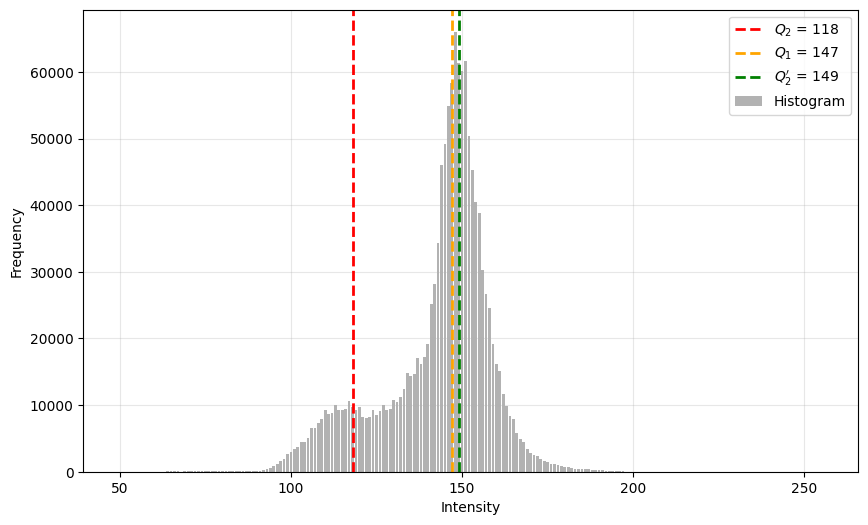

(0.4189352643303155, 0.0005017647762622637, 0.0001458183776022972, 5.259719190957542, 4.2650968586068005, 4.2650968586068005, 4.180058664775526, 4.5221201276956995, 4.512888000071728, 0.9990441214222379, 4.180058664775526, 0.9979584514866313, 4.184058116297006, 149)


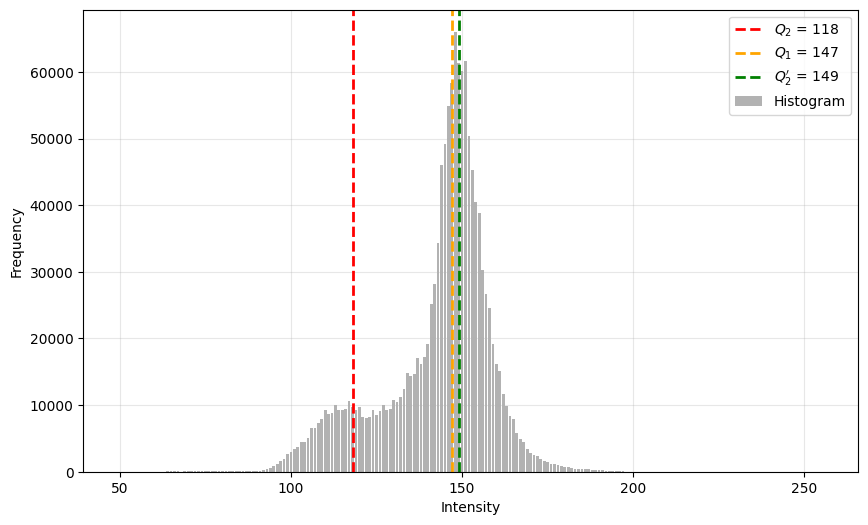

3
9.721432632177374 0
[209 217 214 ...   0   0   0]
k = 955, p = 727, q = 2554, l = 784, s = 1071


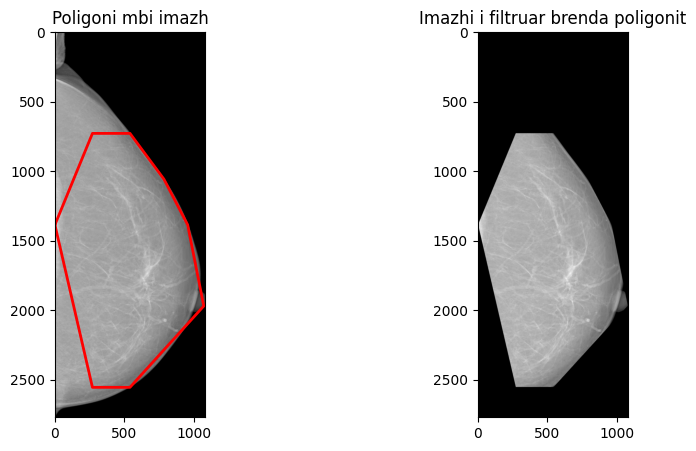

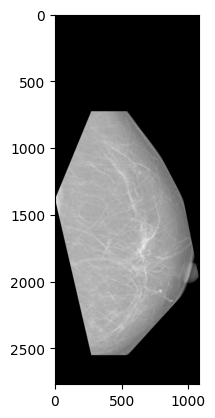

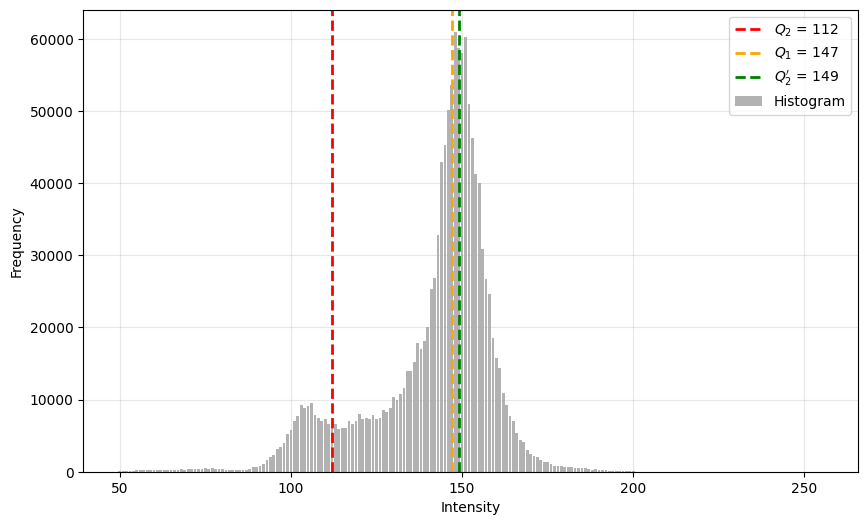

(0.42158390791067474, 0.003996180290297937, 0.0008051948051948052, 5.452897450052907, 4.24616438835953, 4.24616438835953, 4.145789833596087, 4.770755336886989, 4.735406935072275, 0.9997330391613989, 4.145789833596087, 0.9925906068706974, 4.146896892668146, 149)


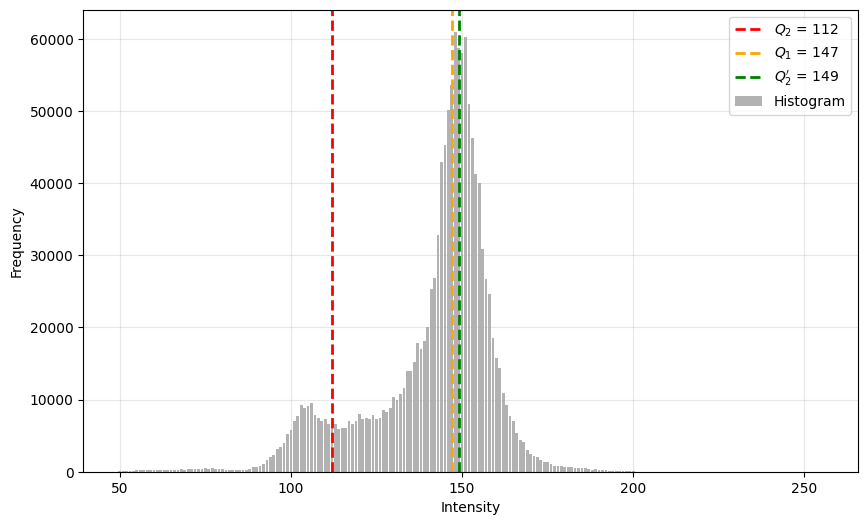

4
100.0 0
[0 0 0 ... 0 0 0]
k = 622, p = 859, q = 2366, l = 523, s = 612


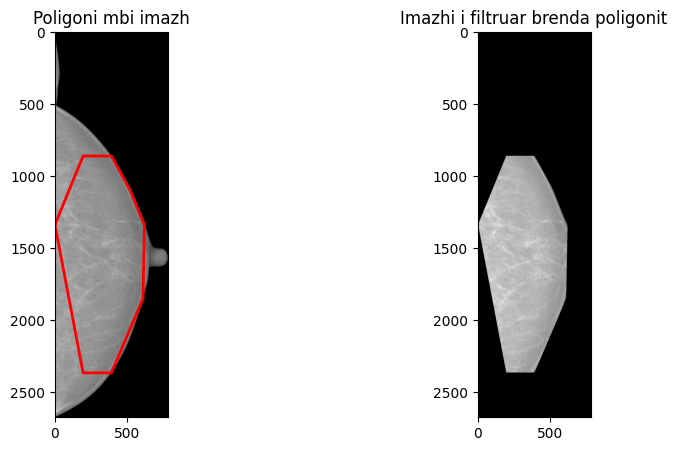

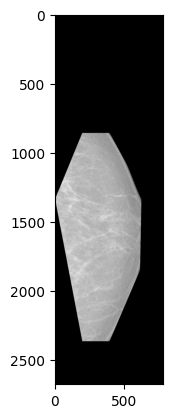

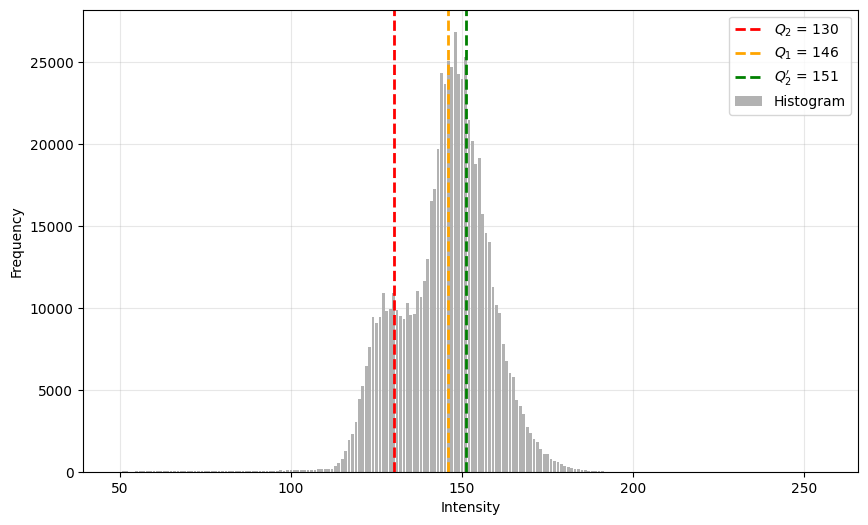

(0.4017879186655153, 0.0007626982569445683, 0.0004564478839105838, 4.847571393811428, 4.49578182695967, 4.49578182695967, 4.270632517423674, 4.054259634576339, 3.8975343633754465, 2.3207437787540925, 4.270632517423674, 0.9613430600585425, 1.8401999206118276, 151)


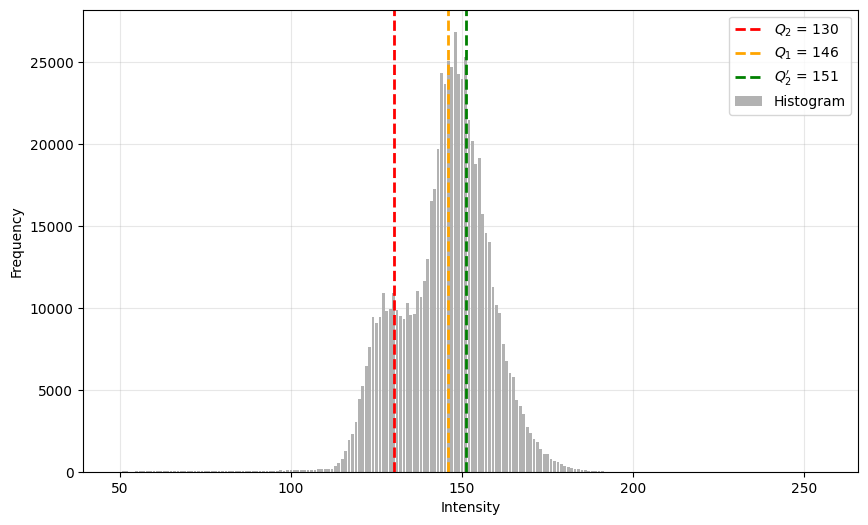

5
25.554292211483798 0
[0 0 0 ... 0 0 0]
k = 748, p = 491, q = 1944, l = 628, s = 677


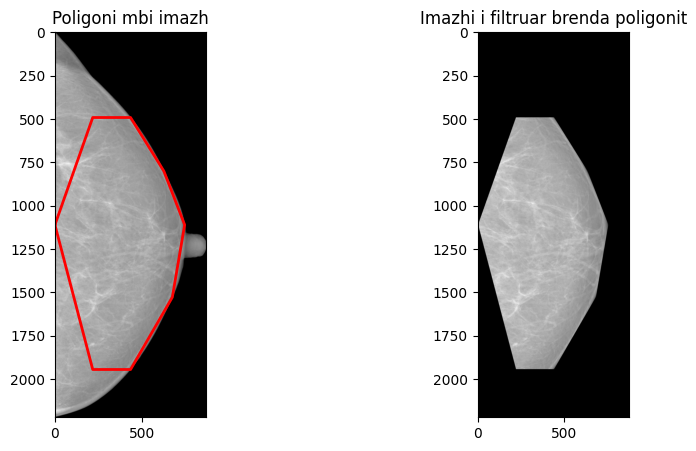

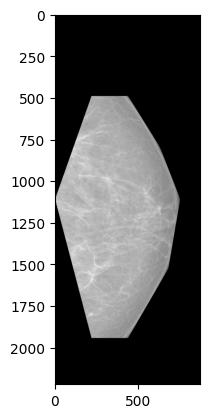

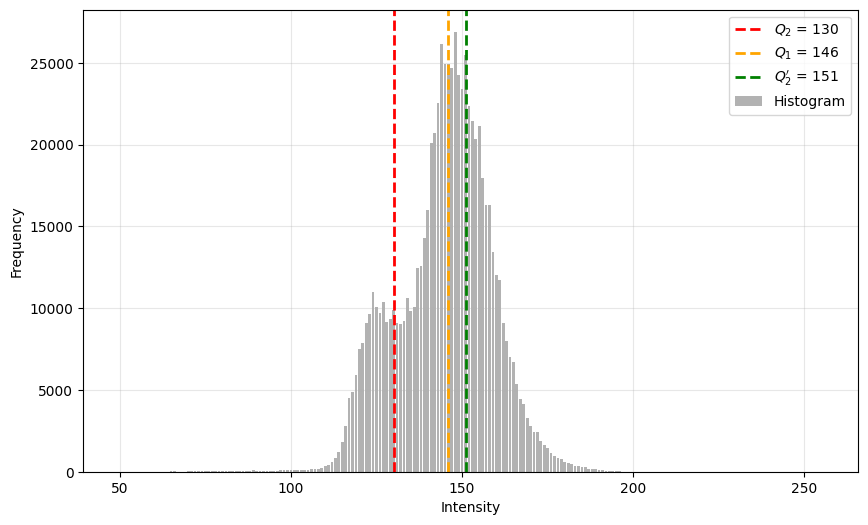

(0.39320612293971086, 0.0003115398089044228, 0.00016981356609825922, 4.919888102820245, 4.602628691438024, 4.602628691438024, 4.378463126273948, 4.199015302635411, 3.8910749014339427, 2.3203228410577355, 4.378463126273948, 0.9266636630239959, 1.8870060014053882, 151)


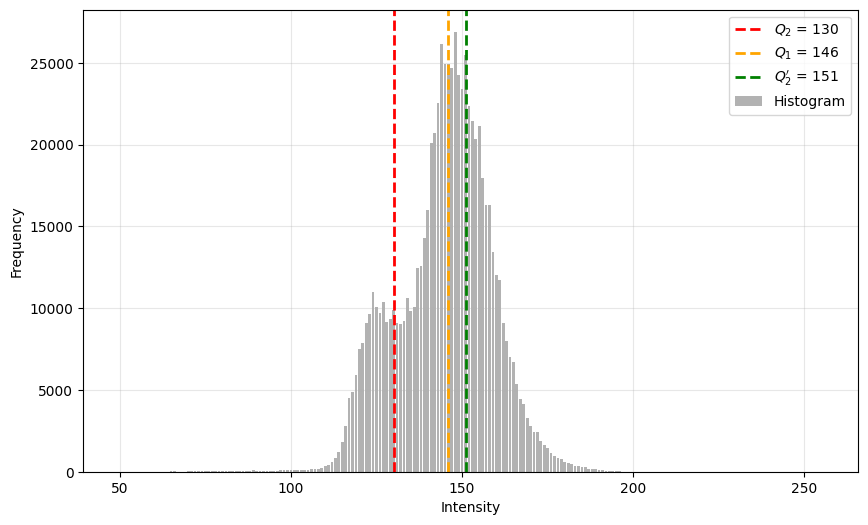

6
100.0 0
[0 0 0 ... 0 0 0]
k = 749, p = 300, q = 1758, l = 607, s = 642


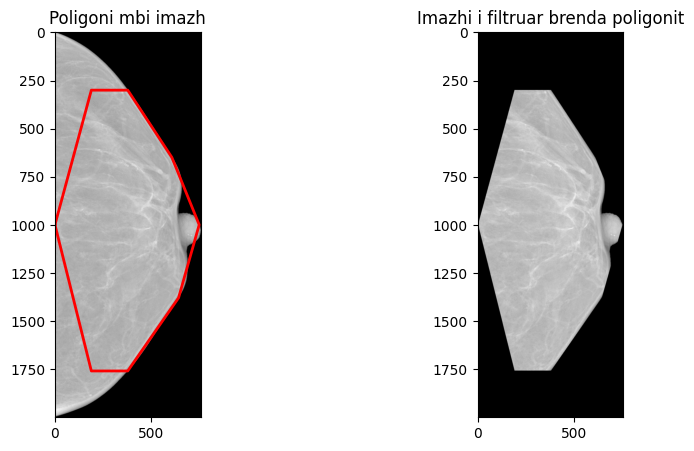

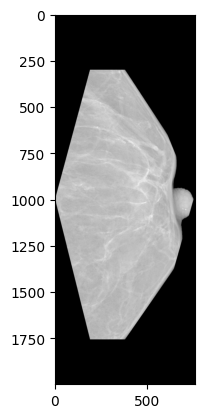

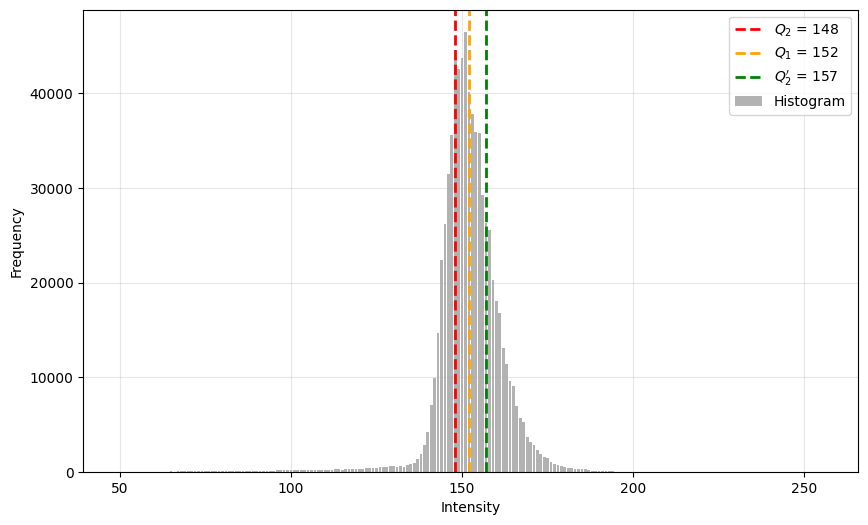

(0.3648404914511941, 0.000784678184555196, 0.000690118641968953, 3.882667708303671, 4.1298156327261, 4.1298156327261, 3.9536817462575495, 3.6054614590679552, 1.9980052988423174, 2.308472778732215, 3.9536817462575495, 0.5541607701331025, 1.7126828536522156, 157)


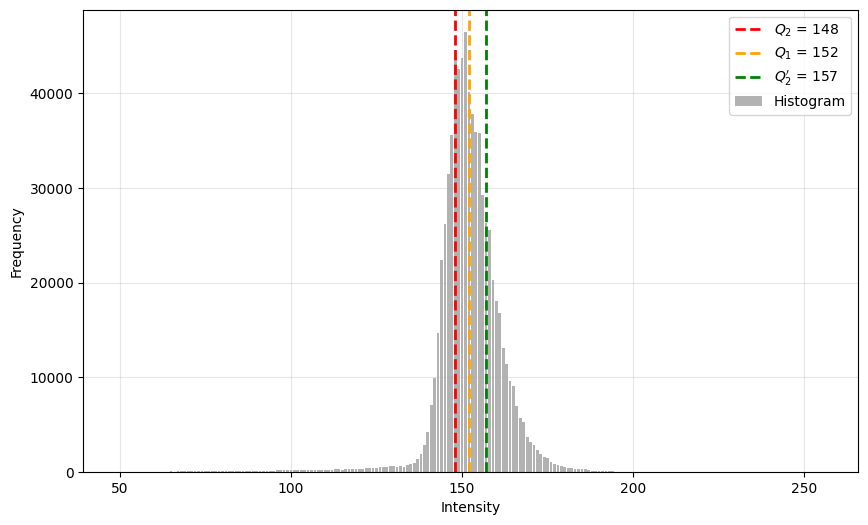

7
12.45025582717453 0
[164 163 167 ...   0   0   0]
k = 601, p = 293, q = 1767, l = 741, s = 515


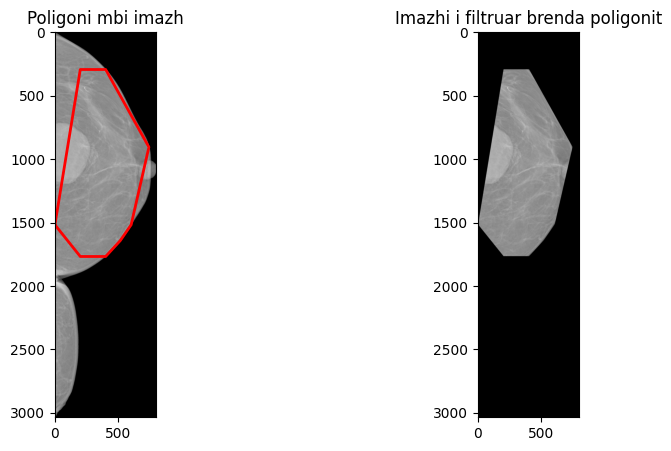

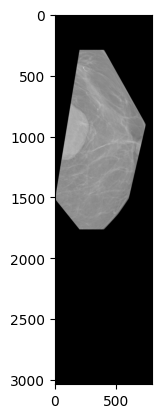

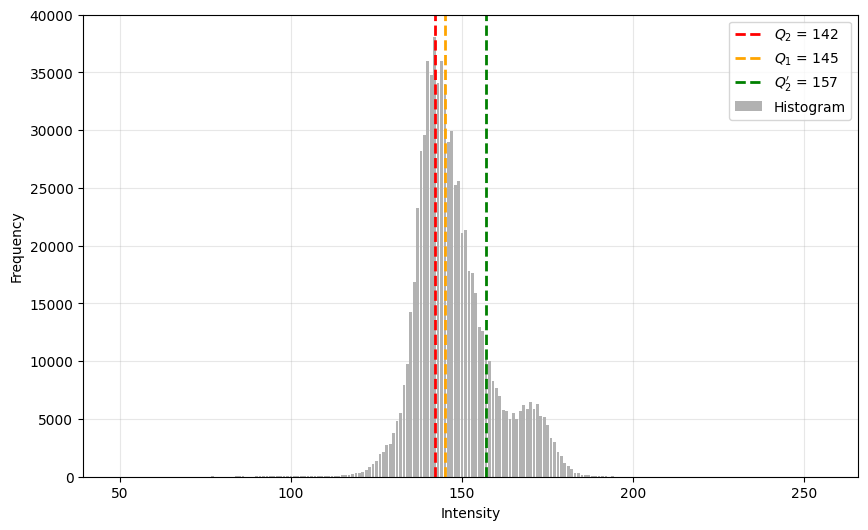

(0.3823997115412996, 0.0001799870625840729, 0.0001800024090547979, 4.010768796415867, 4.799234886276298, 4.799234886276298, 4.551754222994017, 3.764375937503137, 1.5844593770745252, 3.512909236894125, 4.551754222994017, 0.42090891116615653, 1.2957221254649802, 157)


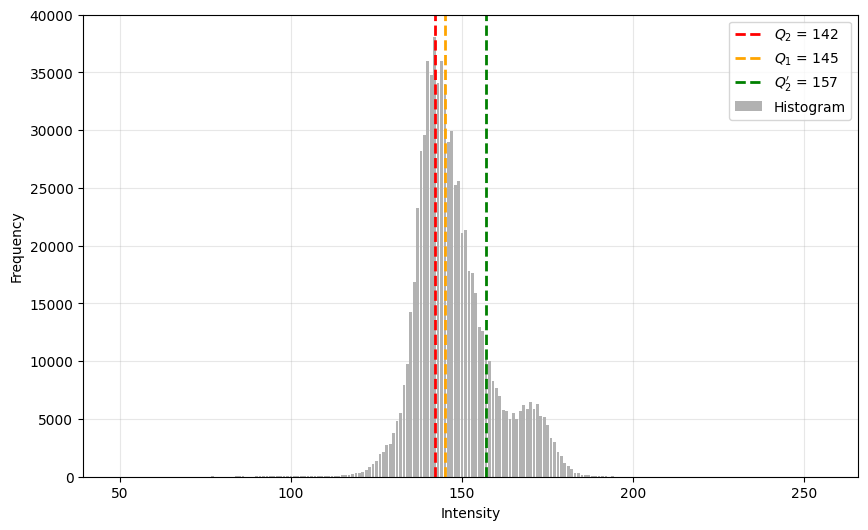

8
100.0 0
[0 0 0 ... 0 0 0]
k = 925, p = 335, q = 2128, l = 936, s = 789


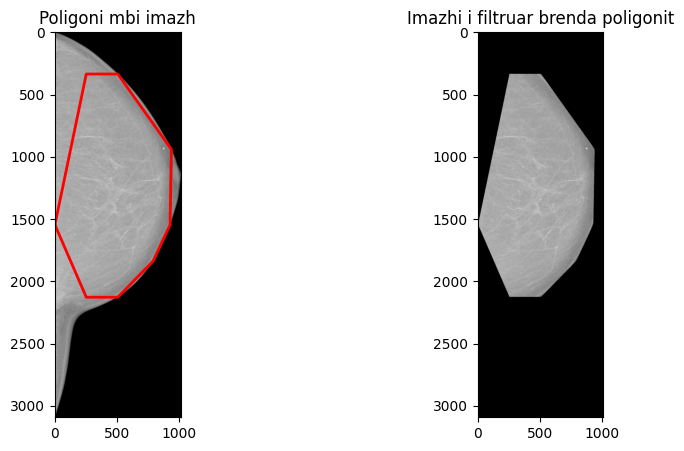

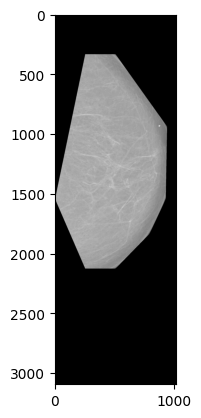

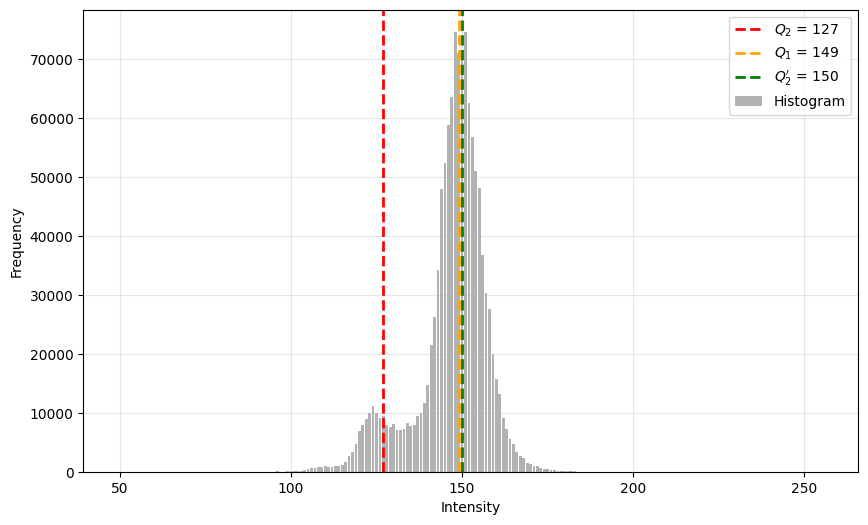

(0.3418981516165821, 0.00013625103220478942, 6.440957886044592e-05, 4.528017060643762, 3.8117256595580318, 3.8117256595580318, 3.7384943679821583, 3.9985287819049367, 3.9177025267312398, 0.0, 3.7384943679821583, 0.9797860014064497, 6, 150)


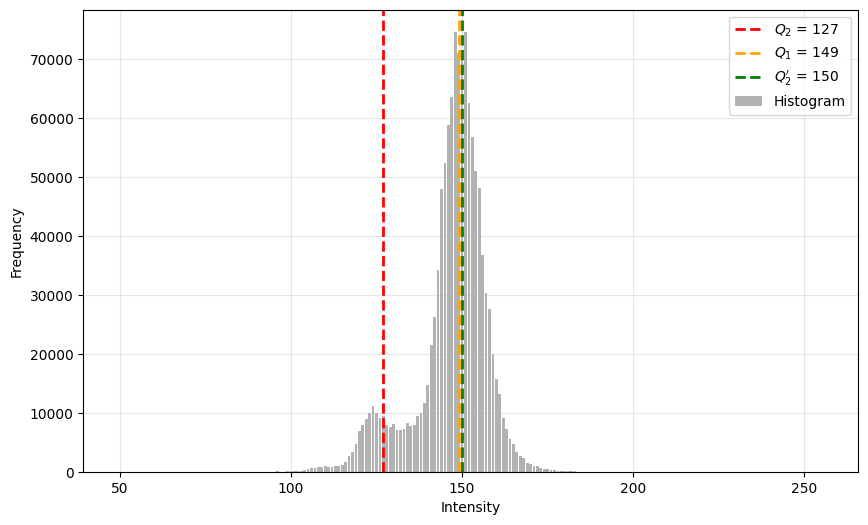

9
5.514496873223423 0
[0 0 0 ... 0 0 0]
k = 957, p = 657, q = 2408, l = 809, s = 802


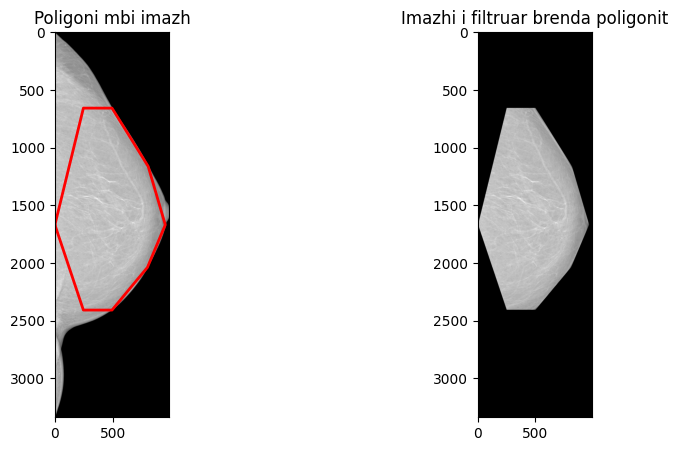

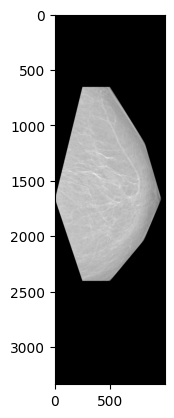

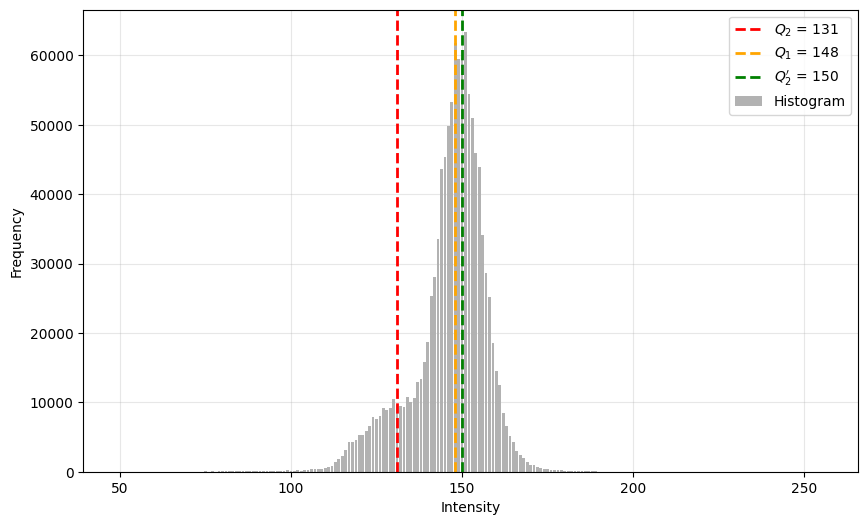

(0.34681782942364114, 0.0002837376520753764, 0.00012630328086113933, 4.677258784414725, 3.9188672168650376, 3.9188672168650376, 3.763104842761752, 4.4370522963289245, 3.7926692264978943, 0.9999980035224816, 3.763104842761752, 0.8547722616737756, 3.7631123557309696, 150)


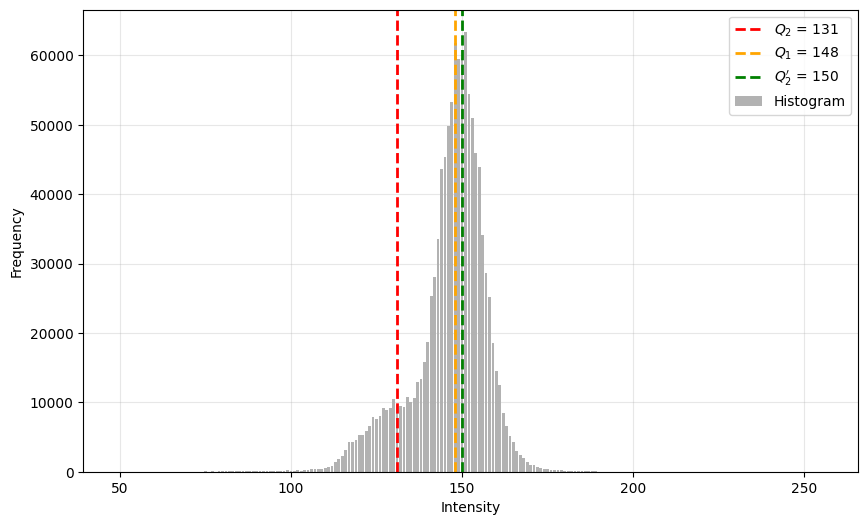

10
100.0 0
[0 0 0 ... 0 0 0]
k = 944, p = 357, q = 2152, l = 1091, s = 794


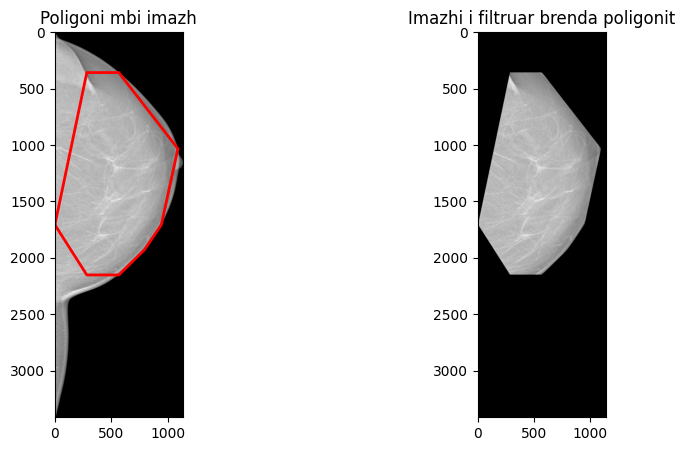

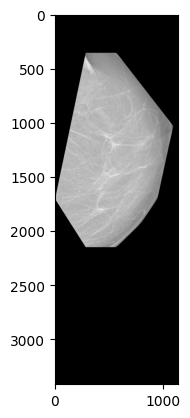

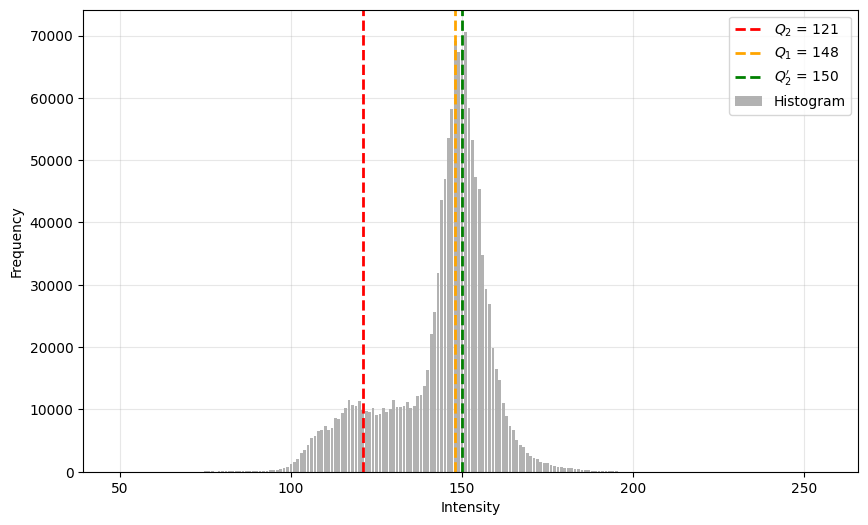

(0.4342356756701801, 0.000347280175017233, 0.00011002195199899409, 5.136459131594312, 4.107650479727016, 4.107650479727016, 4.0057371128144235, 4.47999198329288, 4.350832911111037, 0.9999881203410372, 4.0057371128144235, 0.9711697983693915, 4.00578470017054, 150)


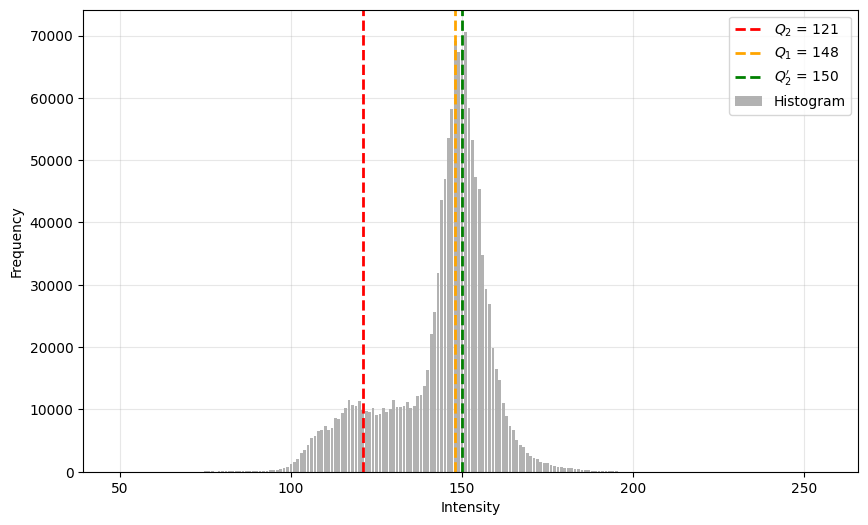

11
6.537805571347357 151
[  0   0   0 ... 120 120 122]
k = 986, p = 320, q = 2190, l = 1080, s = 840


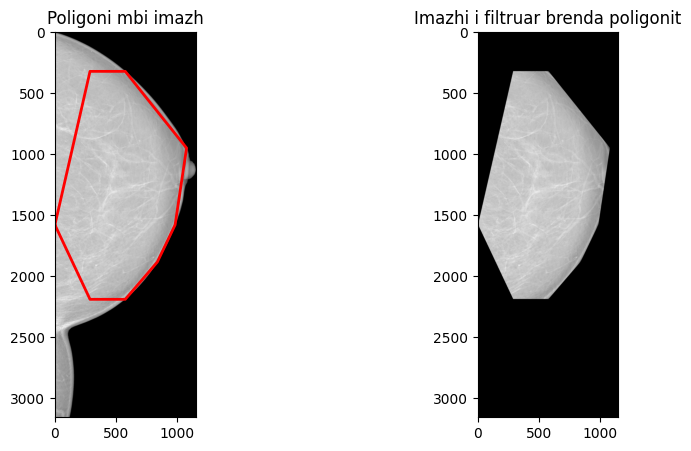

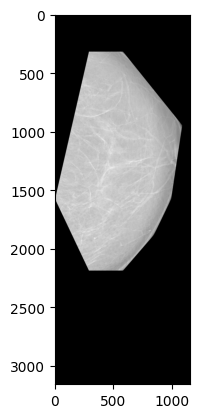

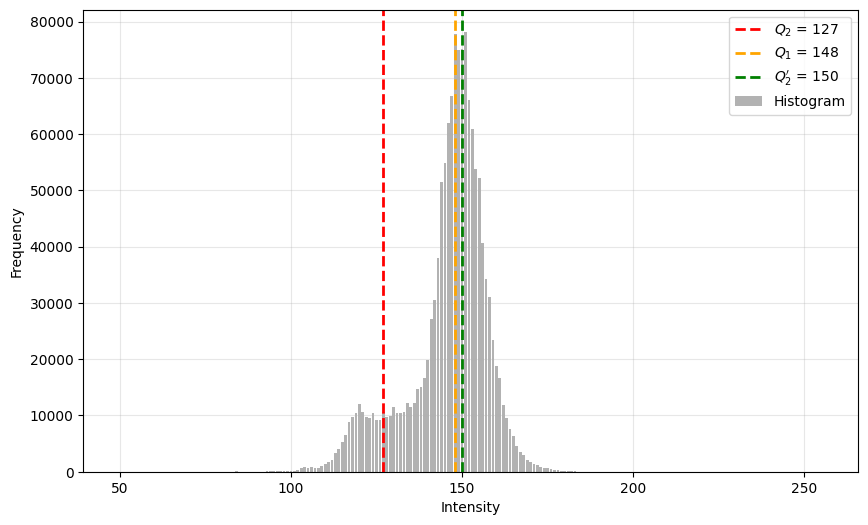

(0.37274323077406857, 0.00020755589337066477, 9.375800700536926e-05, 4.7725692639740265, 3.9508406192406555, 3.9508406192406555, 3.80846827534694, 4.2792396644513255, 4.000083998735162, 0.9999988065806636, 3.80846827534694, 0.9347651247404588, 3.808472820452046, 150)


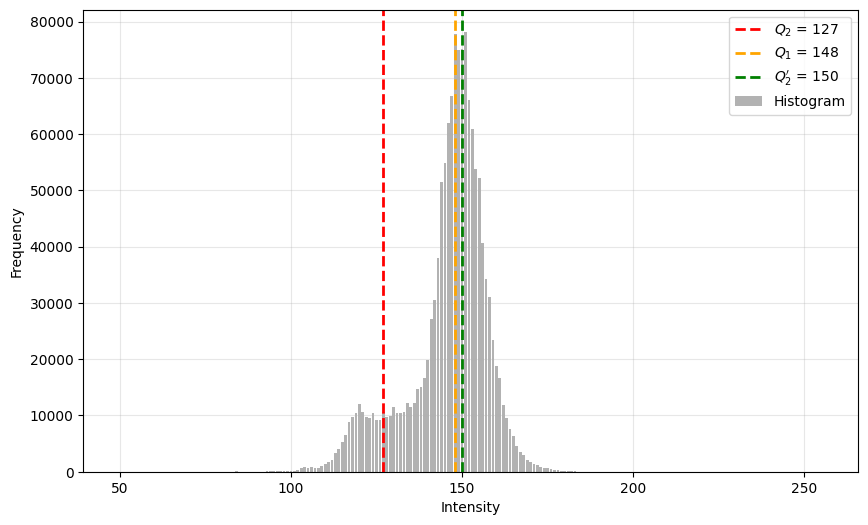

12
100.0 0
[0 0 0 ... 0 0 0]
k = 1157, p = 318, q = 2111, l = 975, s = 912


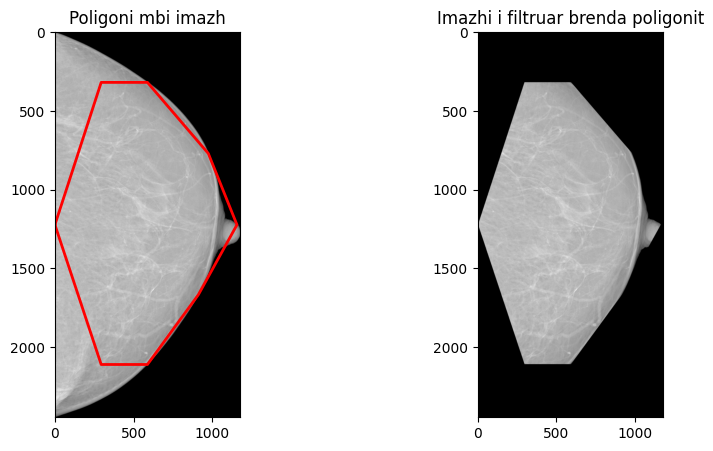

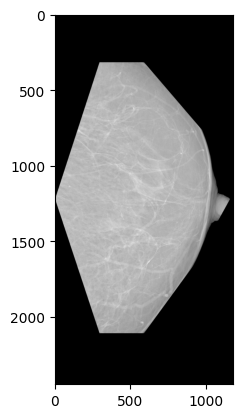

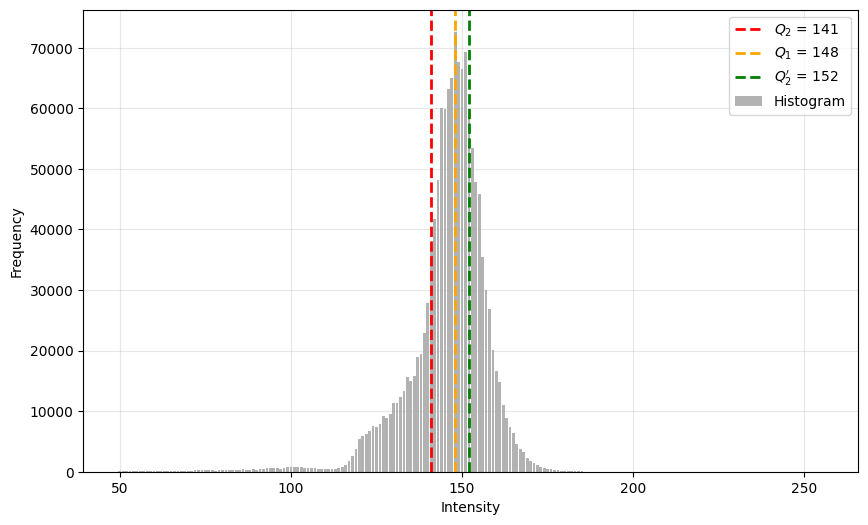

(0.3270042176517496, 0.0026387698940546914, 0.002179152058952503, 4.689708865539576, 3.9823437400701676, 3.9823437400701676, 3.751764087094037, 4.840433080638117, 2.7869258226600735, 1.997106095230765, 3.751764087094037, 0.5757596017199088, 1.878600288714517, 152)


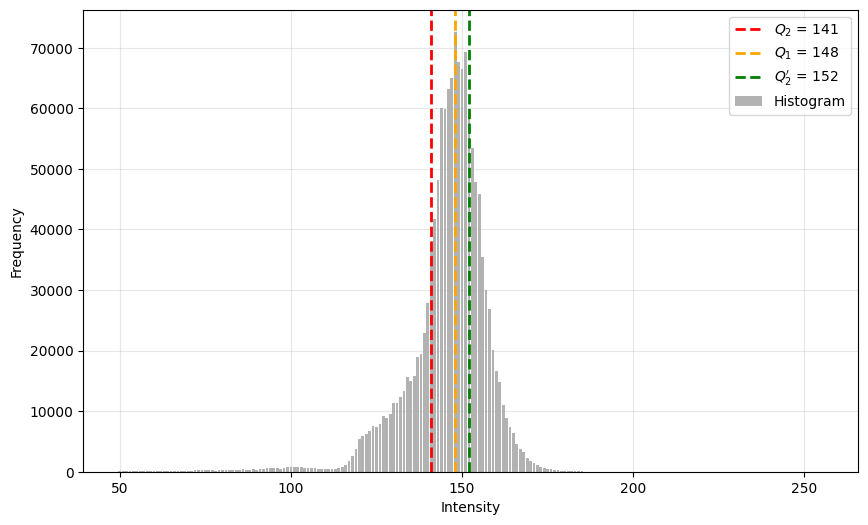

13
20.636725412166005 0
[  0   0   0 ... 131 130 127]
k = 978, p = 243, q = 2039, l = 836, s = 774


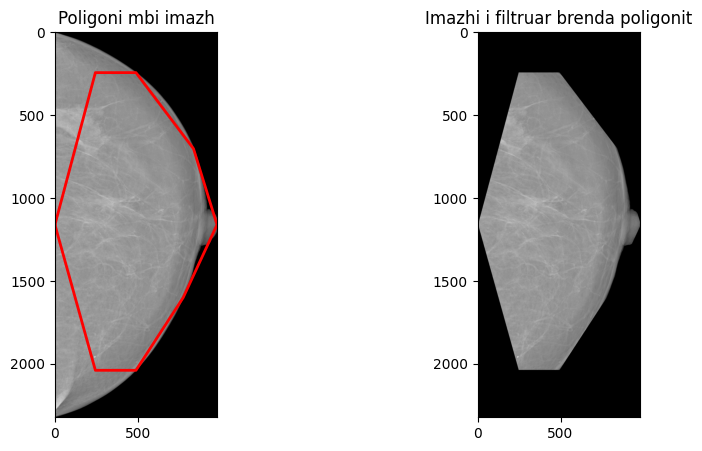

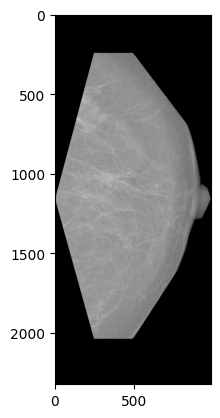

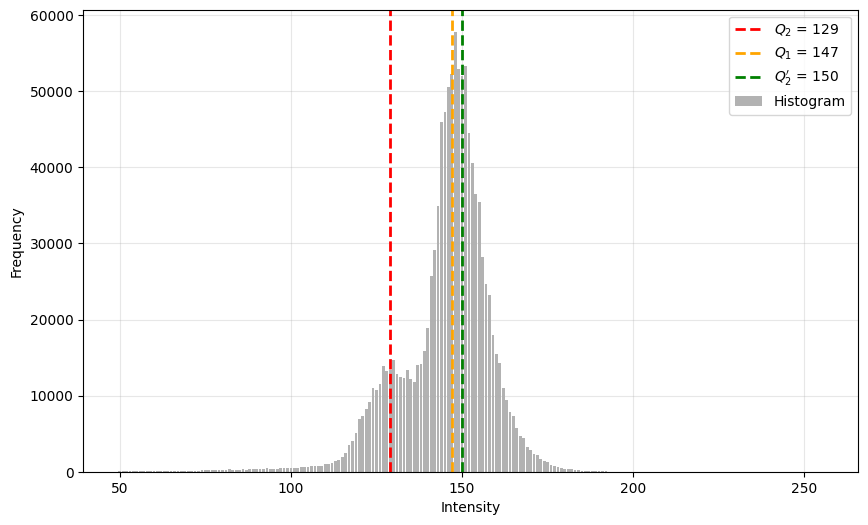

(0.36818852665643376, 0.002136672170084327, 0.0012560922213681917, 4.923883533880799, 4.248621806280549, 4.248621806280549, 4.108215538175616, 4.653893655884754, 3.9326024922463274, 1.5833697890445724, 4.108215538175616, 0.8450133980336297, 2.5946027053191223, 150)


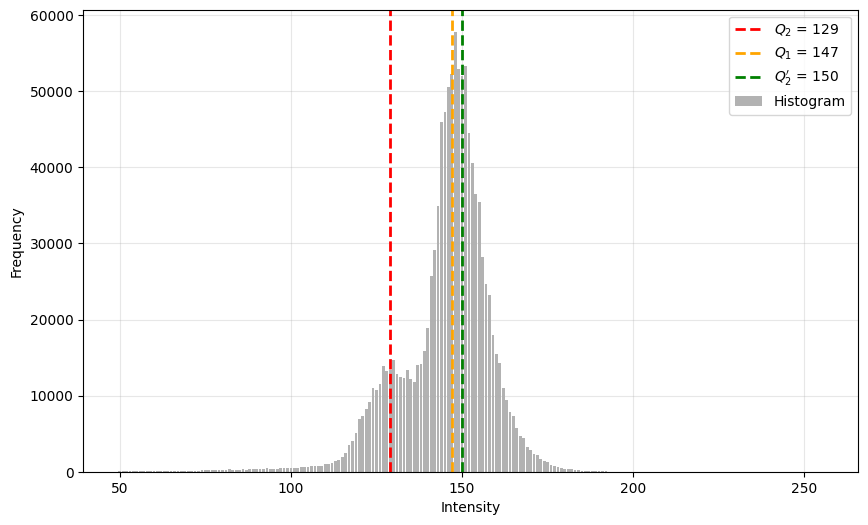

14
100.0 0
[0 0 0 ... 0 0 0]
k = 1195, p = 697, q = 2611, l = 968, s = 1119


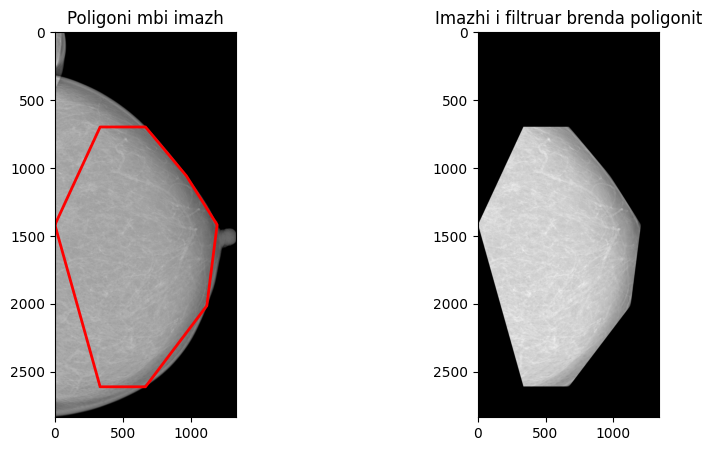

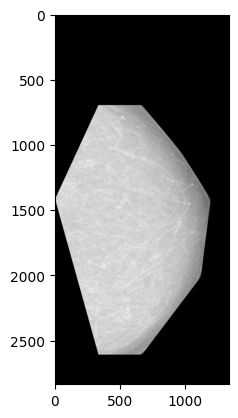

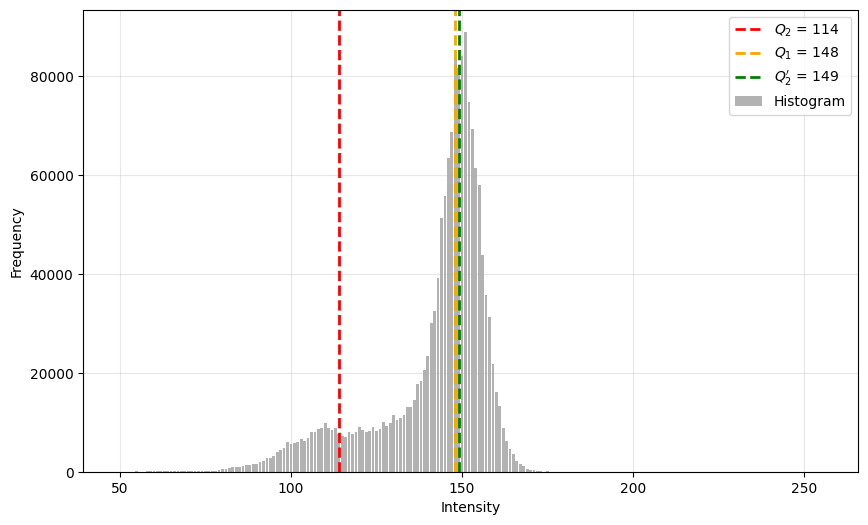

(0.44261145218700526, 0.0009285765167852971, 0.00020423626353538015, 5.322364889459121, 3.7277352700689814, 3.7277352700689814, 3.6305164153773988, 4.874443152038118, 4.583527018472918, 0.0, 3.6305164153773988, 0.9403180784981438, 6, 149)


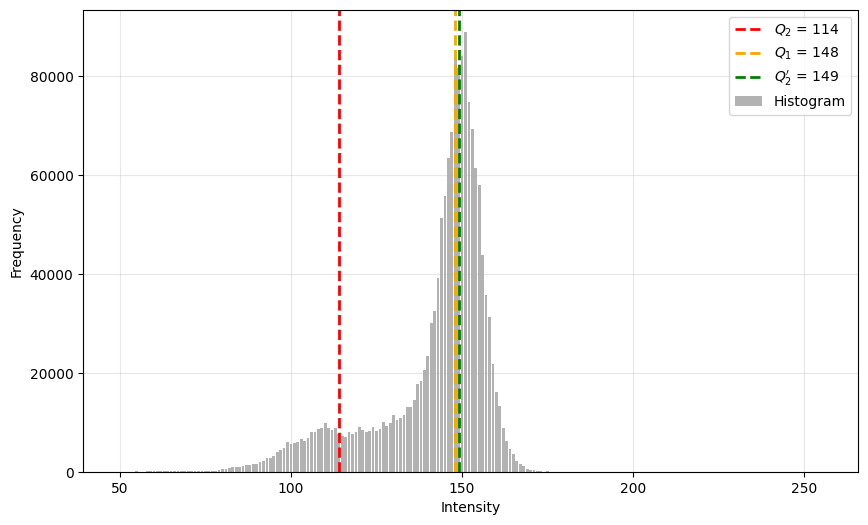

15
6.253553155201819 148
[165 161 162 ... 142 140 139]
k = 1118, p = 298, q = 2038, l = 963, s = 992


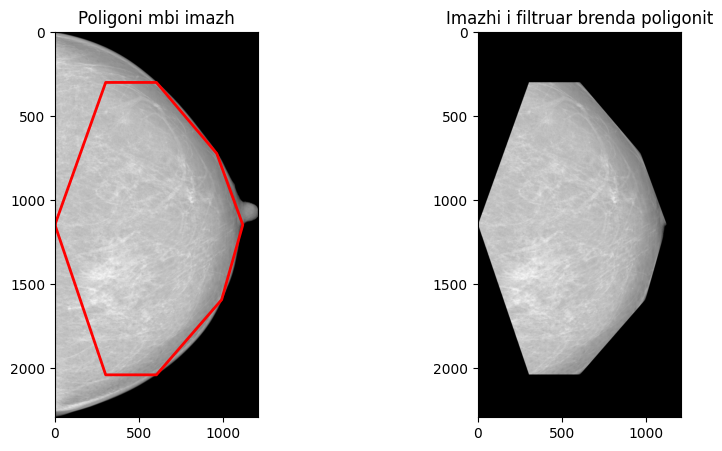

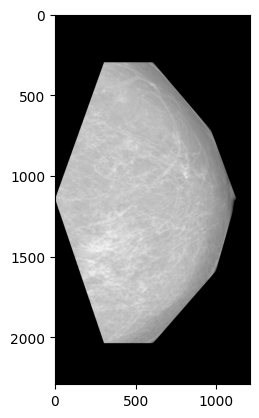

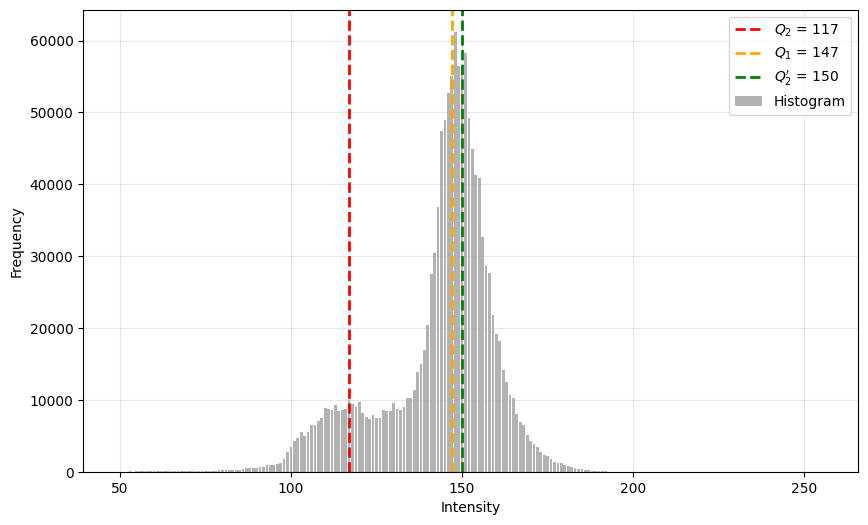

(0.413024361033148, 0.0007446055425919614, 0.00021200725169680715, 5.280532689012629, 4.382544298170682, 4.382544298170682, 4.253992008039041, 4.671791388671442, 4.497630137804838, 1.5837771175011697, 4.253992008039041, 0.9627206704287085, 2.685978955644243, 150)


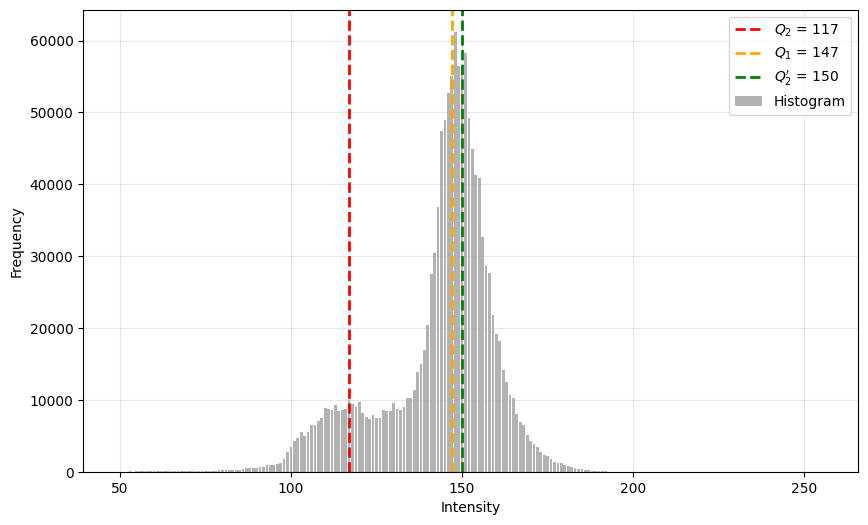

16
100.0 0
[0 0 0 ... 0 0 0]
k = 783, p = 351, q = 2058, l = 653, s = 687


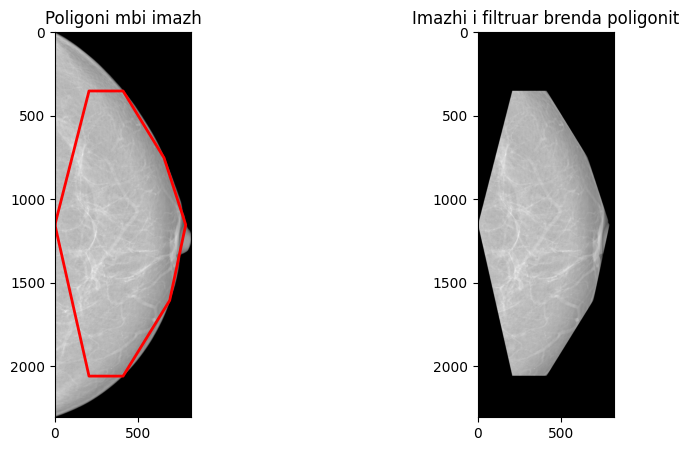

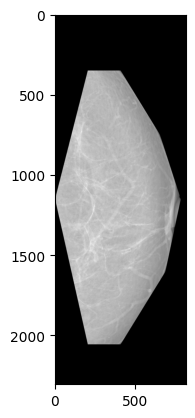

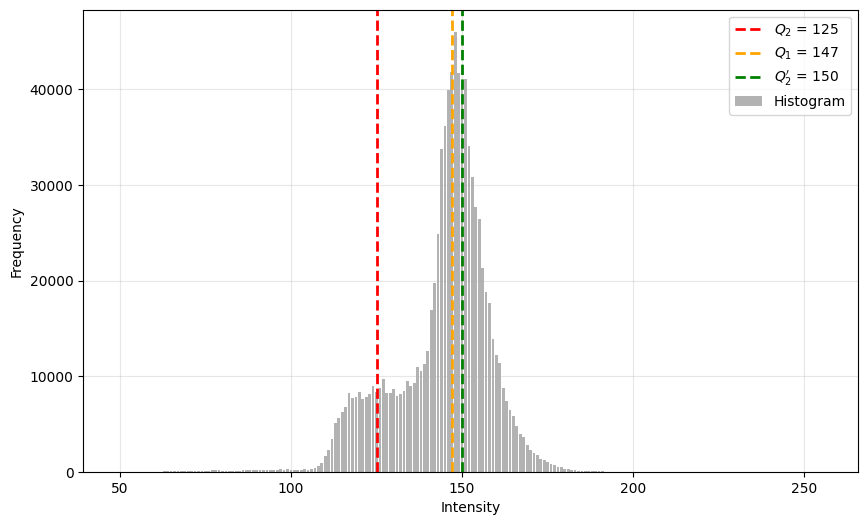

(0.40462956197822797, 0.0007650644840065091, 0.00019322071326046151, 5.016822191726161, 4.258942587958414, 4.258942587958414, 4.130266237267427, 4.388016274095081, 4.168076163115067, 1.582678662241159, 4.130266237267427, 0.9498770977039344, 2.6096682389201766, 150)


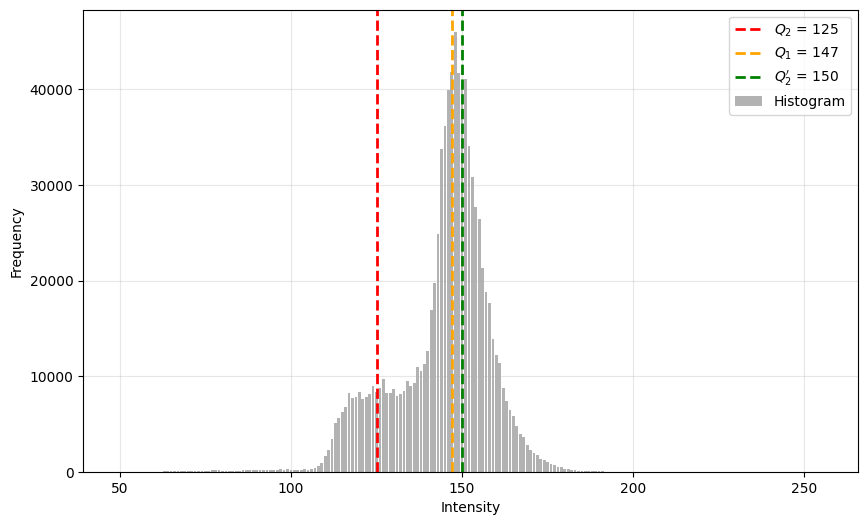

17
33.82603752131893 0
[0 0 0 ... 0 0 0]
k = 752, p = 454, q = 2105, l = 625, s = 690


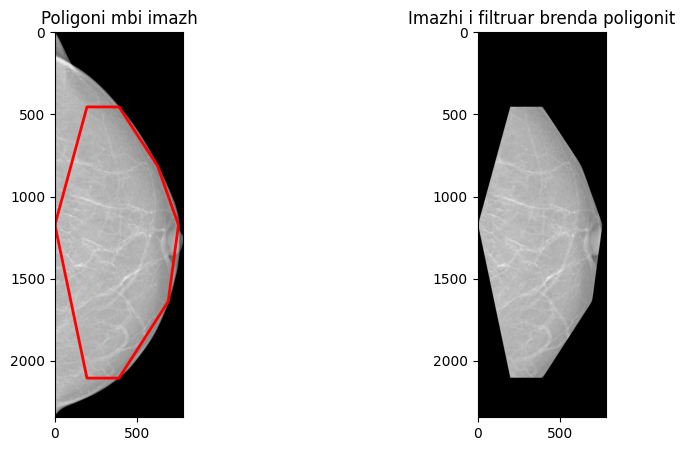

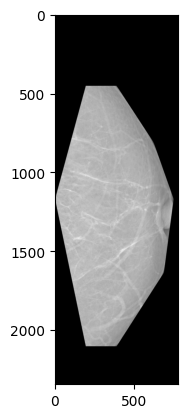

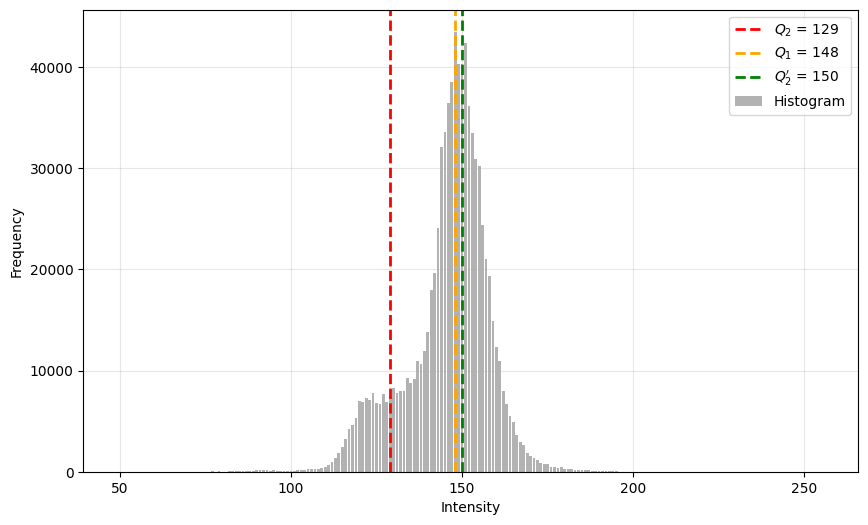

(0.3681229680683988, 0.00017169687908802093, 6.774434685105587e-05, 4.820853188997183, 4.1370397536462455, 4.1370397536462455, 4.018678229458638, 4.343571877314042, 3.973666298206593, 0.999999699602209, 4.018678229458638, 0.9148383888754272, 4.018679436661063, 150)


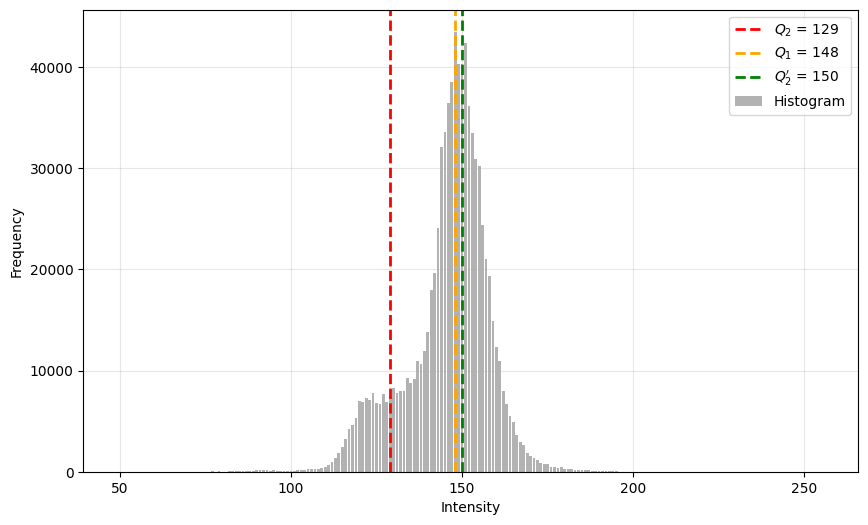

18
100.0 0
[0 0 0 ... 0 0 0]
k = 1152, p = 711, q = 2698, l = 1079, s = 965


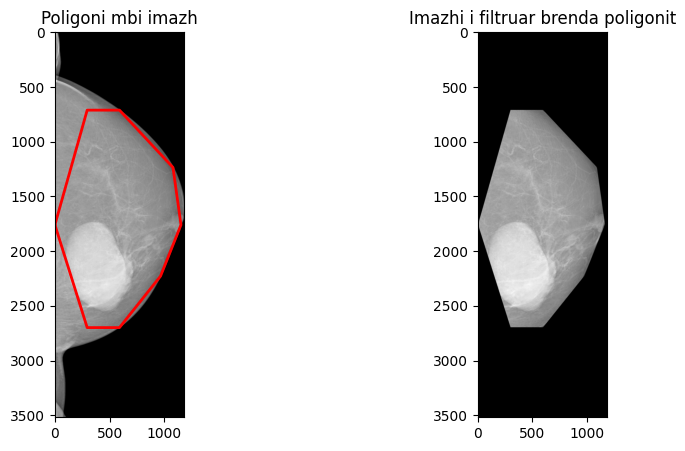

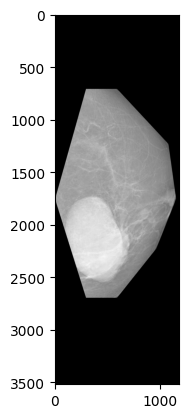

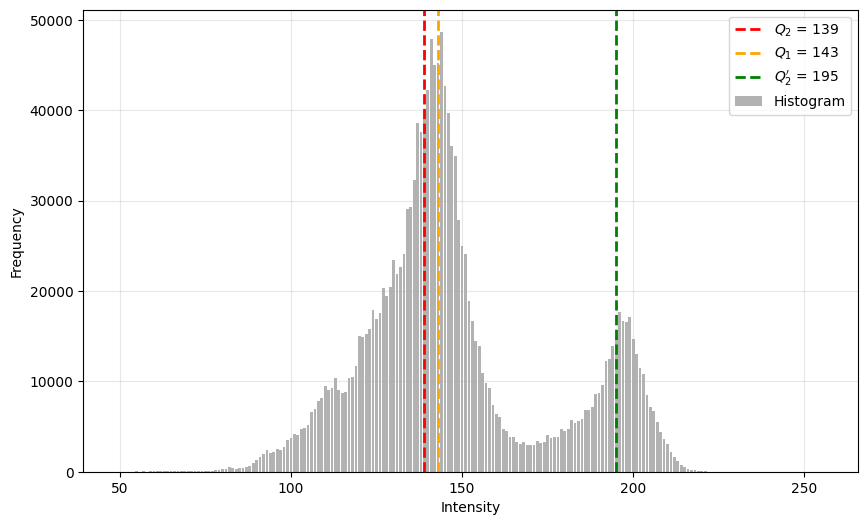

(0.4689303731392318, 0.00044800161079230845, 0.0004128348310275956, 5.32211969898029, 5.646928641326917, 5.646928641326917, 3.937507194808912, 5.277357874539135, 1.9985792131570927, 5.156692840192476, 3.937507194808912, 0.37870829696794556, 0.7635721802390586, 195)


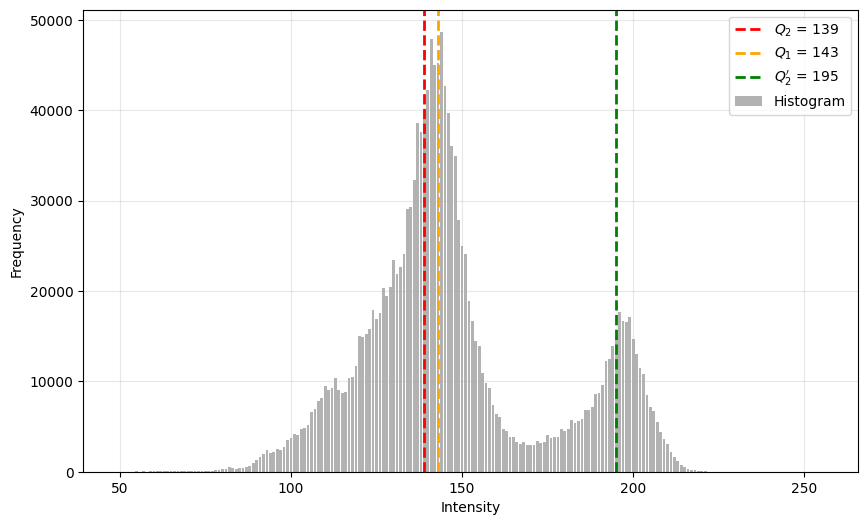

19
14.58214894826606 0
[  0   0   0 ... 175 174 172]
k = 1050, p = 512, q = 2203, l = 869, s = 917


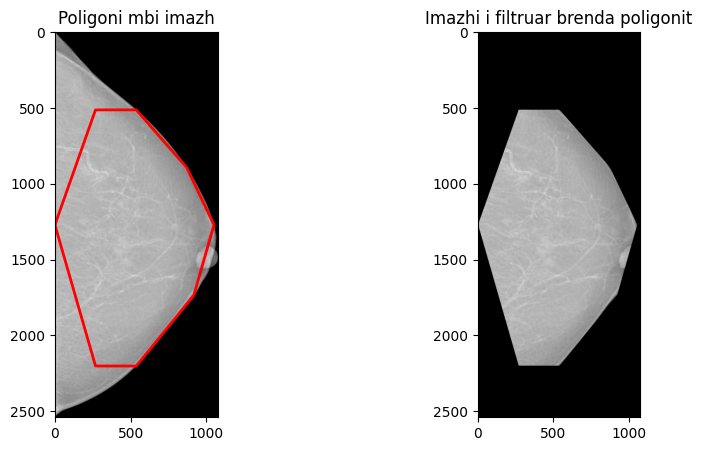

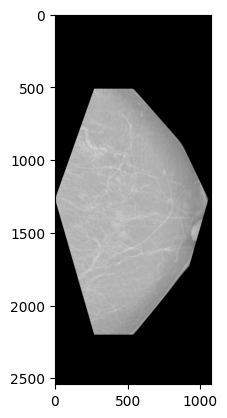

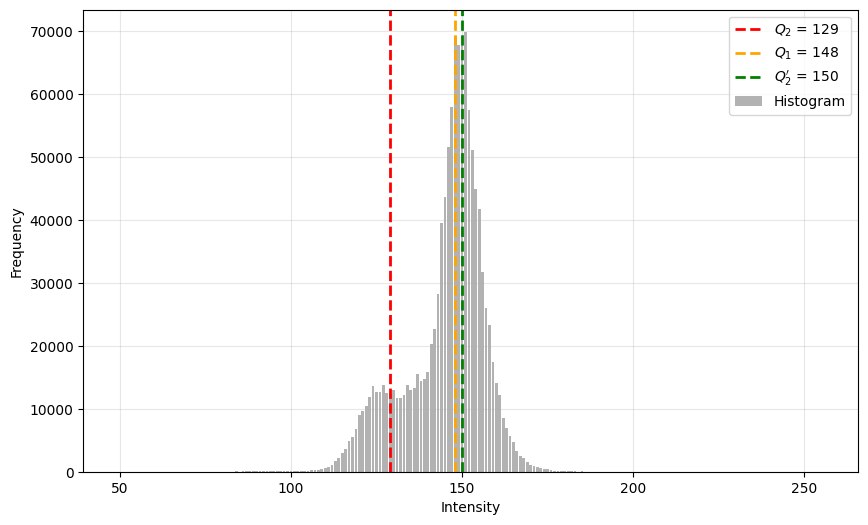

(0.4165888133890908, 0.0003591133981792701, 0.0002191341617660047, 4.800533706472716, 3.8775819035508095, 3.8775819035508095, 3.7391125552283357, 4.167766633688668, 3.9542561069880167, 0.999999998585153, 3.7391125552283357, 0.9487709976430028, 3.739112560518608, 150)


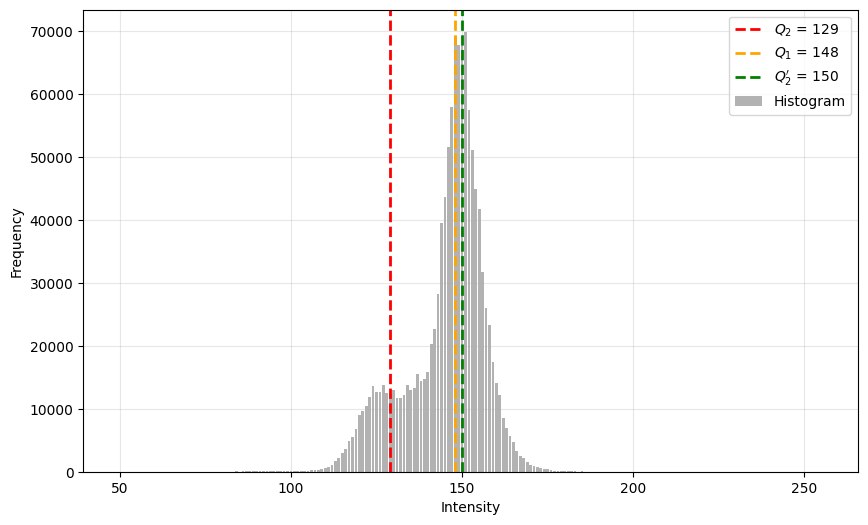

20
100.0 0
[0 0 0 ... 0 0 0]
k = 934, p = 480, q = 2115, l = 766, s = 868


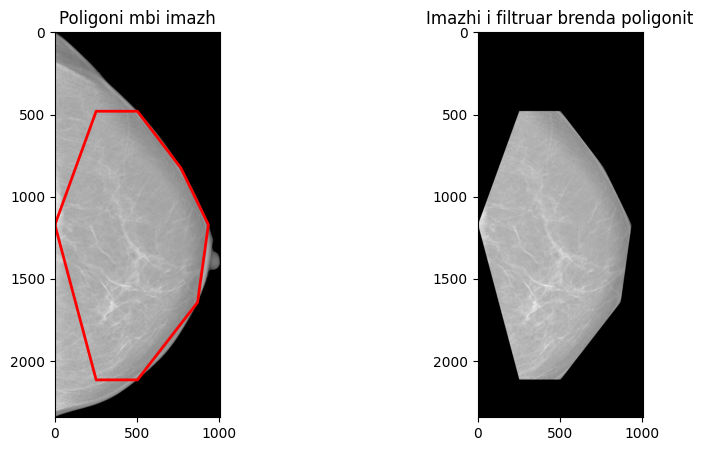

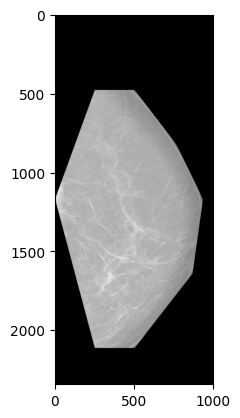

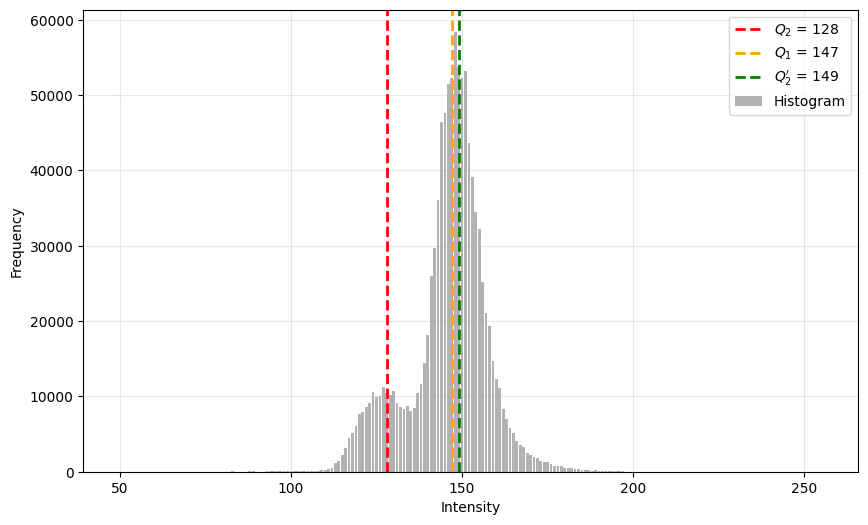

(0.3576446817449024, 0.00020935008639243384, 0.0001146215405135045, 4.656239256719813, 4.181795638978392, 4.181795638978392, 4.093334690804656, 4.002531912136425, 3.886816472900728, 0.9987311537657207, 4.093334690804656, 0.971089439940547, 4.098535101634426, 149)


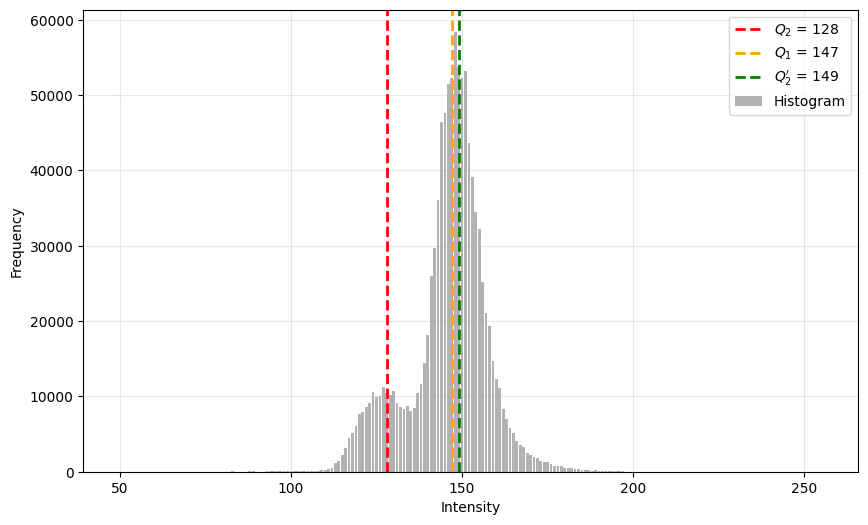

21
15.80443433769187 0
[153 153 147 ...   0   0   0]
k = 814, p = 697, q = 2334, l = 674, s = 852


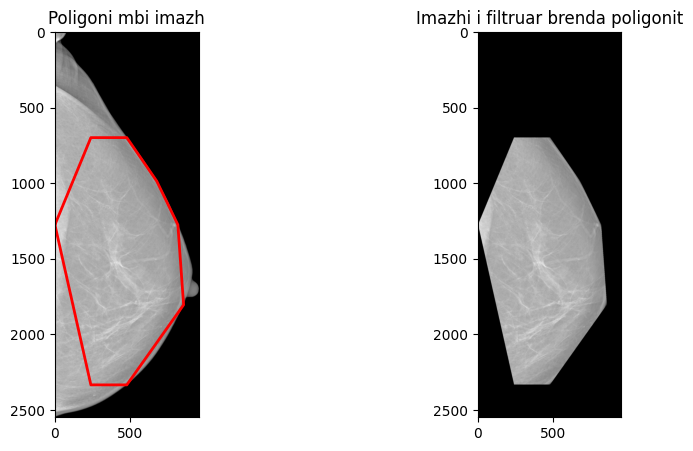

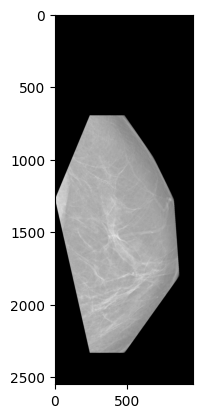

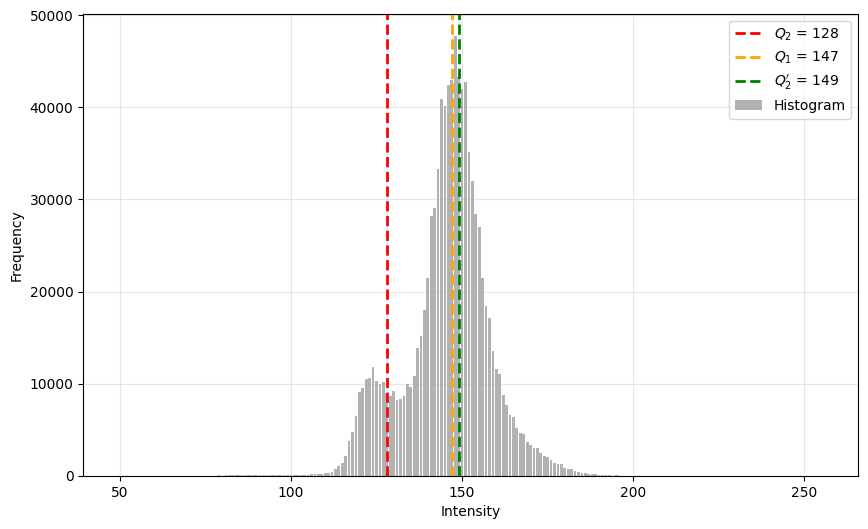

(0.34702009273536044, 0.00025751625571364194, 0.00013795513698945102, 4.743415469056931, 4.386385958030744, 4.386385958030744, 4.324245326934872, 3.9631830984716663, 3.981760691631857, 0.9982935939737955, 4.324245326934872, 1.0046875434968814, 4.331636858172988, 149)


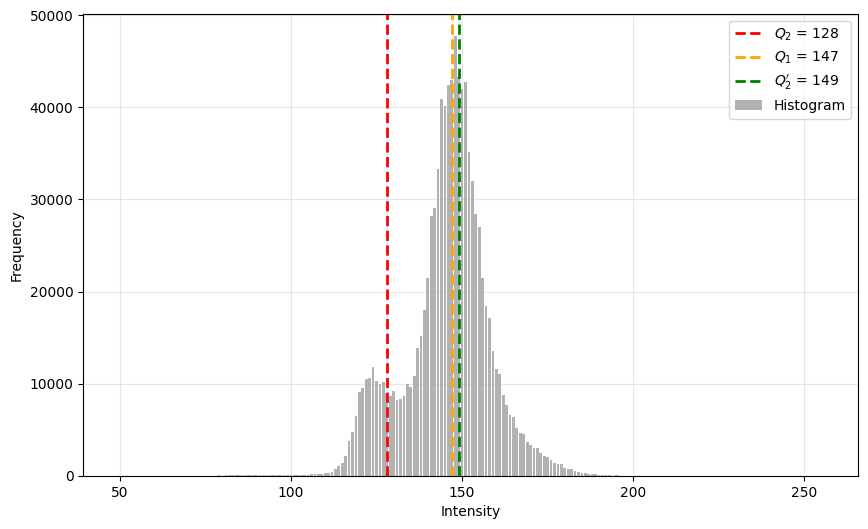

22
100.0 0
[0 0 0 ... 0 0 0]
k = 739, p = 342, q = 1784, l = 944, s = 633


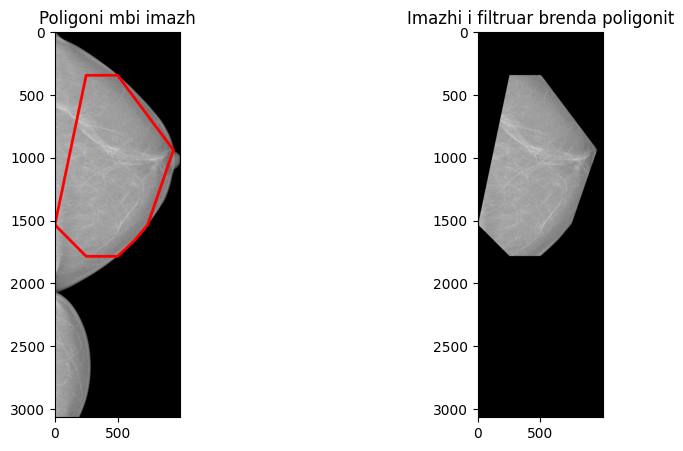

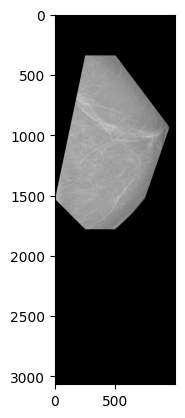

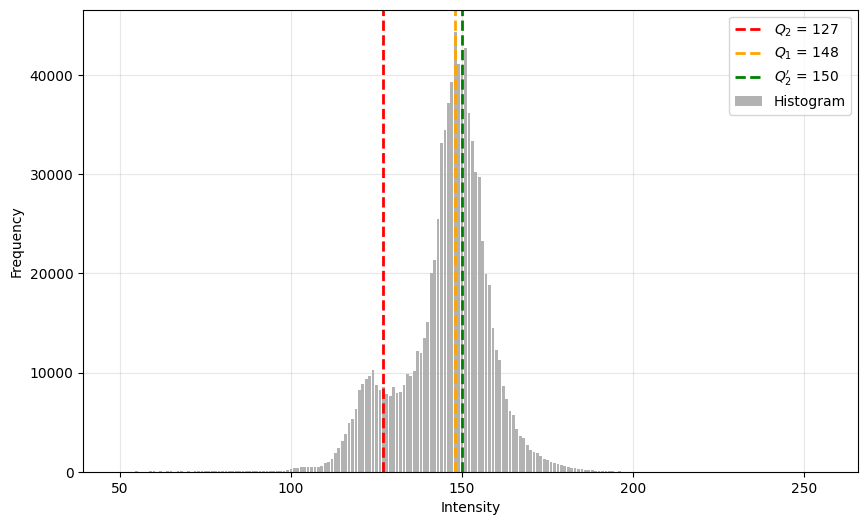

(0.37999789952949925, 0.0005940932362650383, 0.000307517649198415, 4.909472222709557, 4.241687981704302, 4.241687981704302, 4.147911588998392, 4.265613231163597, 4.116824032509066, 0.9999932457208234, 4.147911588998392, 0.9651189194633234, 4.147939605340494, 150)


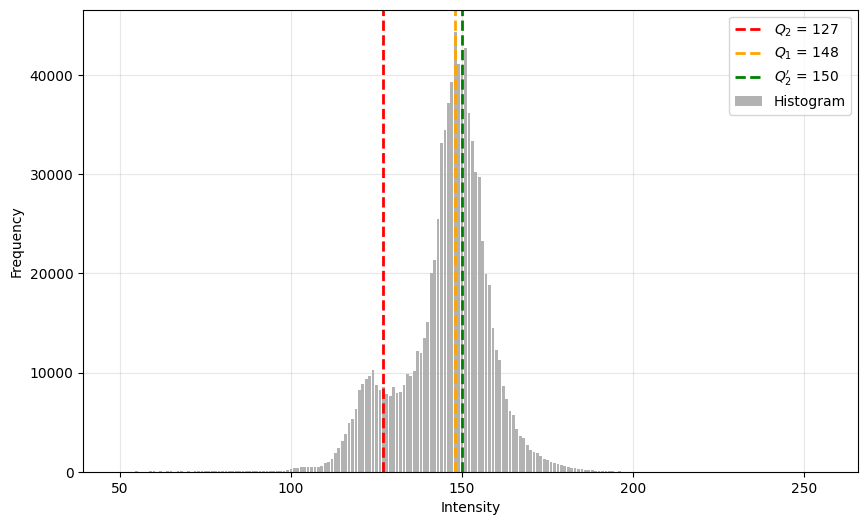

23
6.850483229107447 158
[160 161 166 ...   0   0   0]
k = 888, p = 284, q = 1727, l = 747, s = 755


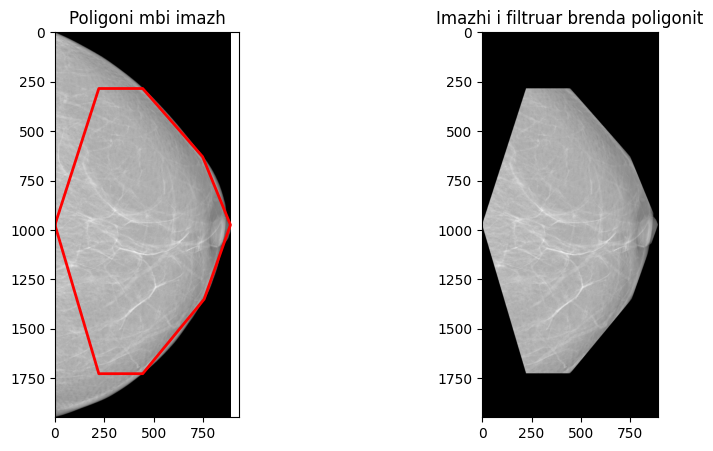

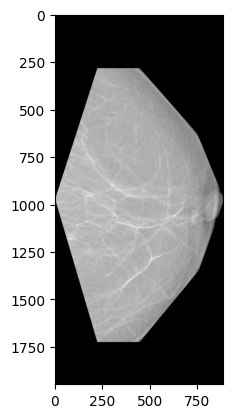

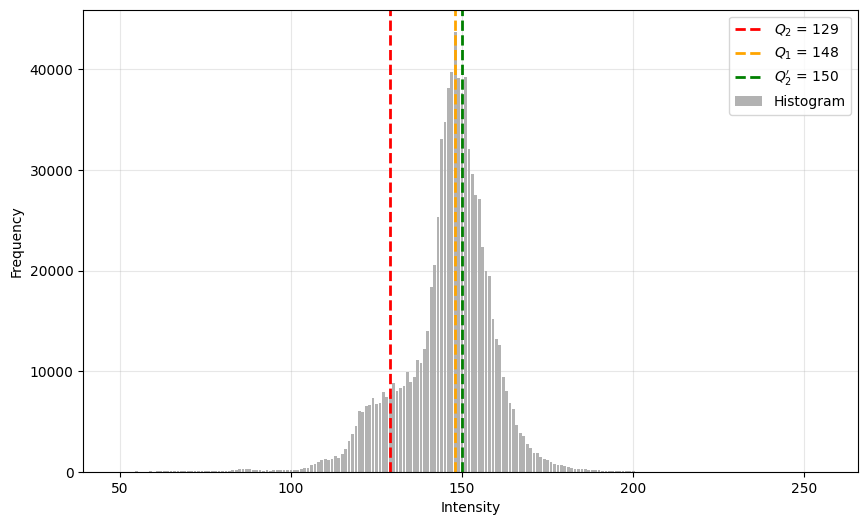

(0.3469454944155661, 0.0008166717200407522, 0.0003729041566615668, 4.869818998551452, 4.308954817648906, 4.308954817648906, 4.2238887869881365, 4.6179863312057705, 3.97750484078081, 0.9997270359507423, 4.2238887869881365, 0.8613071922502359, 4.225042071580279, 150)


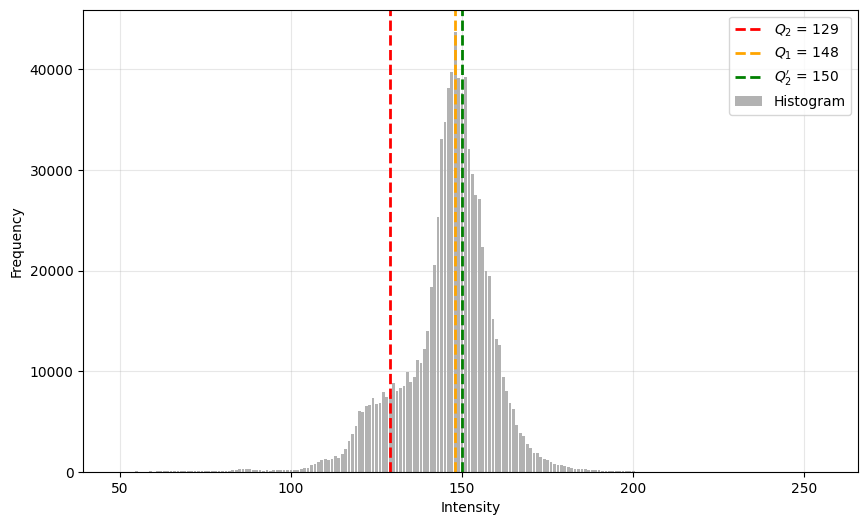

24
100.0 0
[0 0 0 ... 0 0 0]
k = 856, p = 380, q = 1879, l = 707, s = 776


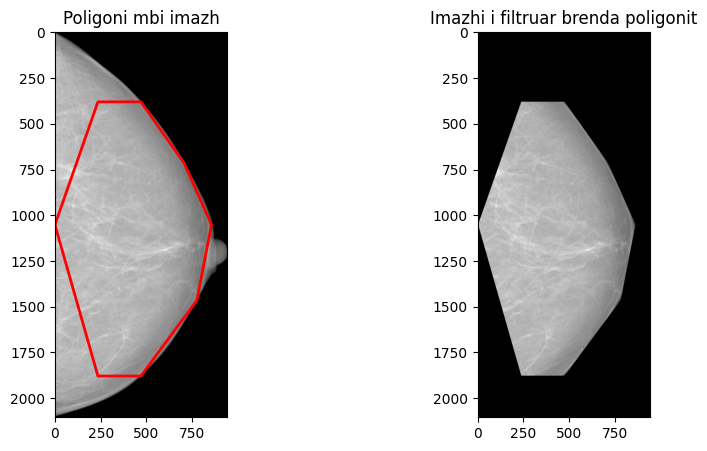

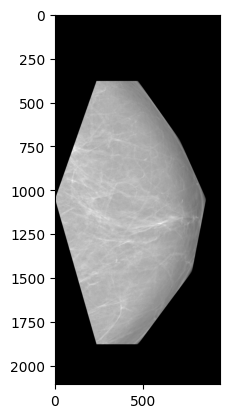

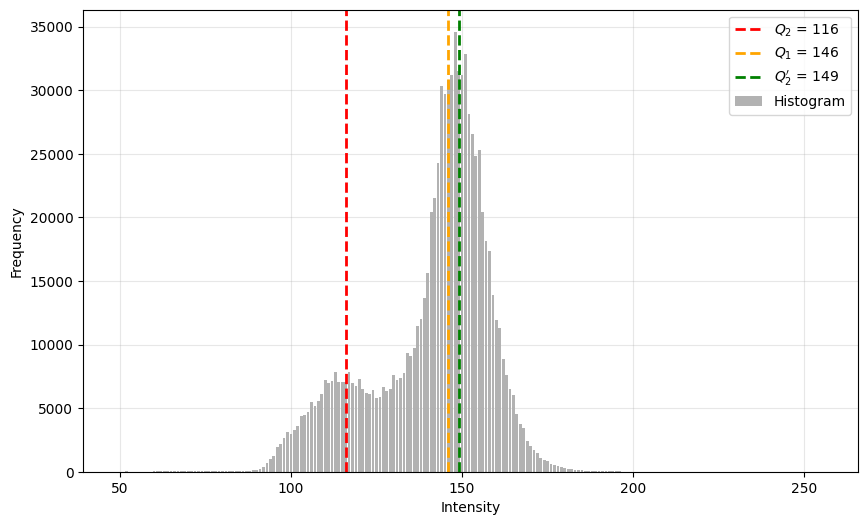

(0.445874880966787, 0.000579632246684196, 0.00014234583661203244, 5.415417241926753, 4.396083598290369, 4.396083598290369, 4.2316150522509846, 4.55213624692981, 4.643434570497399, 1.5833450257585515, 4.2316150522509846, 1.020056149160554, 2.6725792442008625, 149)


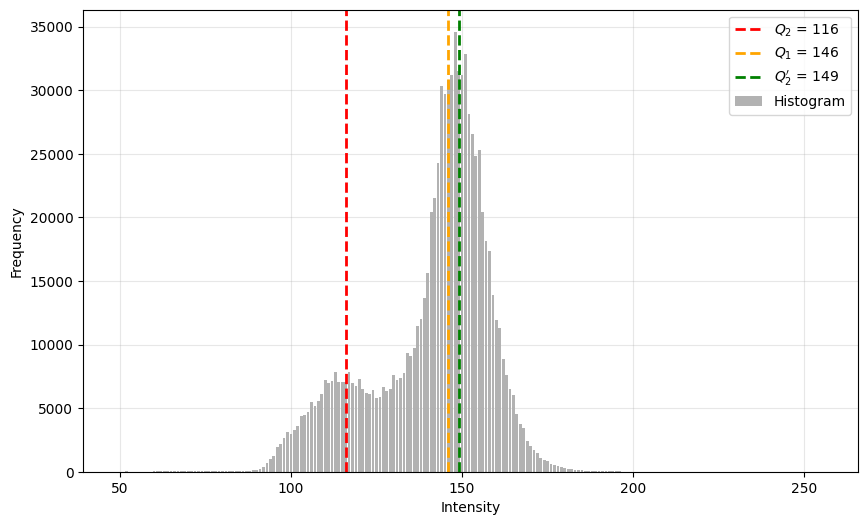

25
17.453098351335985 0
[28 33 39 ...  0  0  0]
k = 776, p = 449, q = 2095, l = 658, s = 825


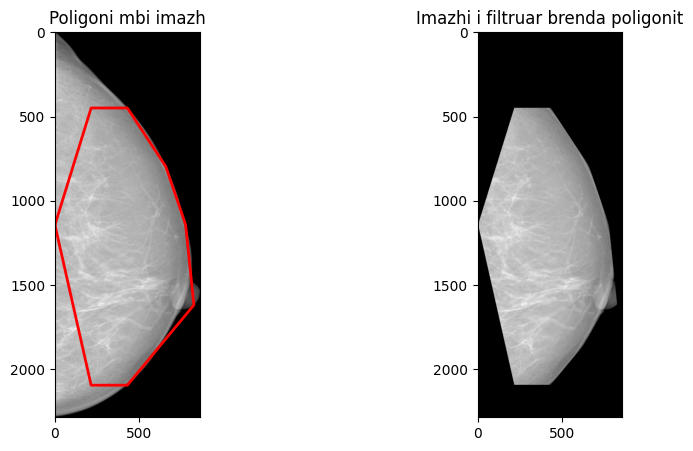

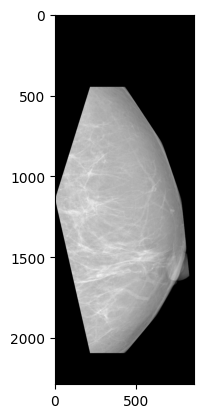

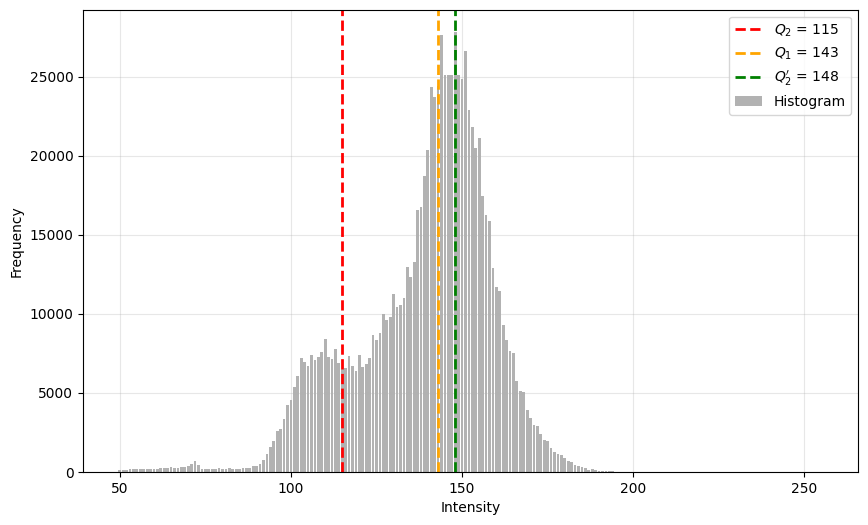

(0.42121522883525586, 0.004755479479388787, 0.0012807346622305301, 5.591145642174324, 4.780488936768597, 4.780488936768597, 4.55714312644061, 4.853216750765283, 4.666220236872799, 2.3201619477208677, 4.55714312644061, 0.9614695729666314, 1.9641487228584043, 148)


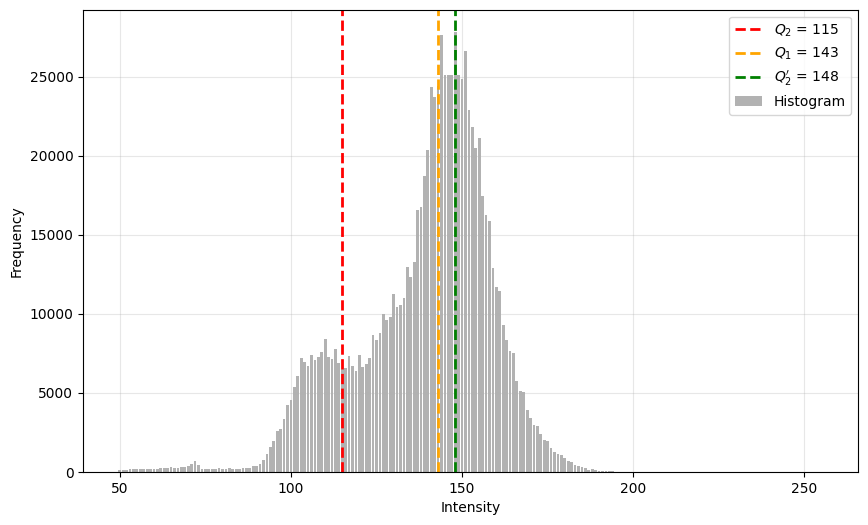

26
100.0 0
[0 0 0 ... 0 0 0]
k = 395, p = 306, q = 1573, l = 357, s = 340


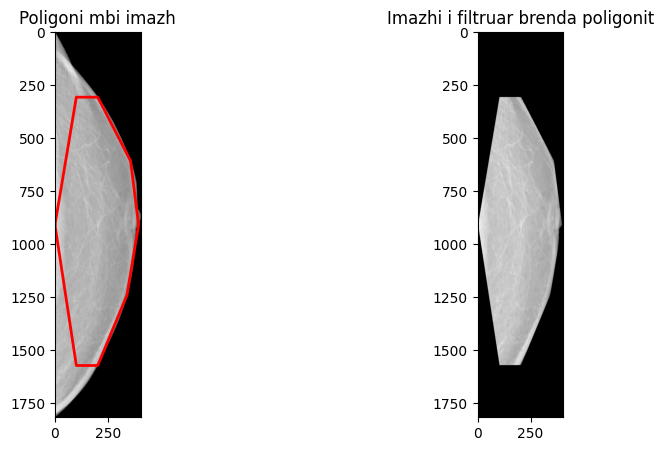

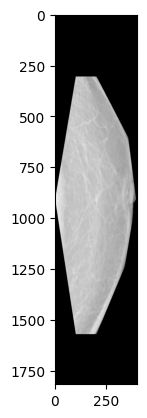

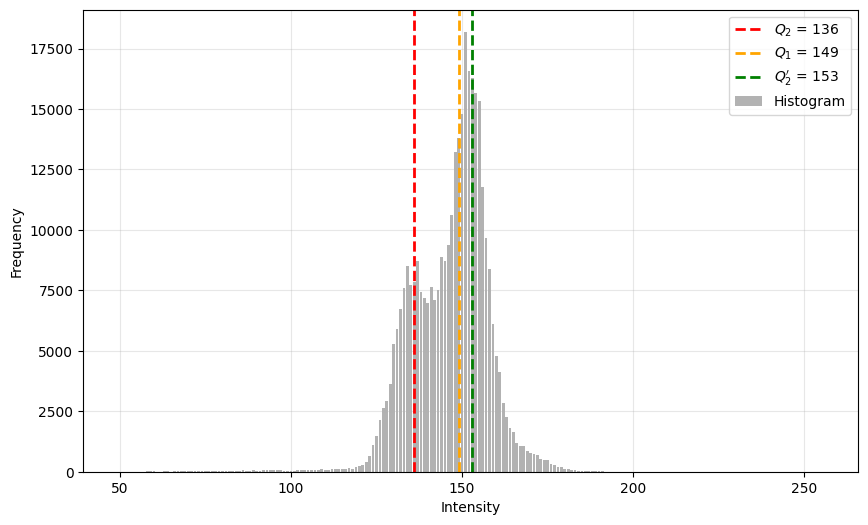

(0.4556968171137664, 0.0006553231961214145, 0.00042047388857151973, 4.7211490872228055, 4.021642450542705, 4.021642450542705, 3.779714082506996, 3.9625074994070912, 3.6616284303238475, 1.9961225899882802, 3.779714082506996, 0.9240685174404681, 1.8935280335308404, 153)


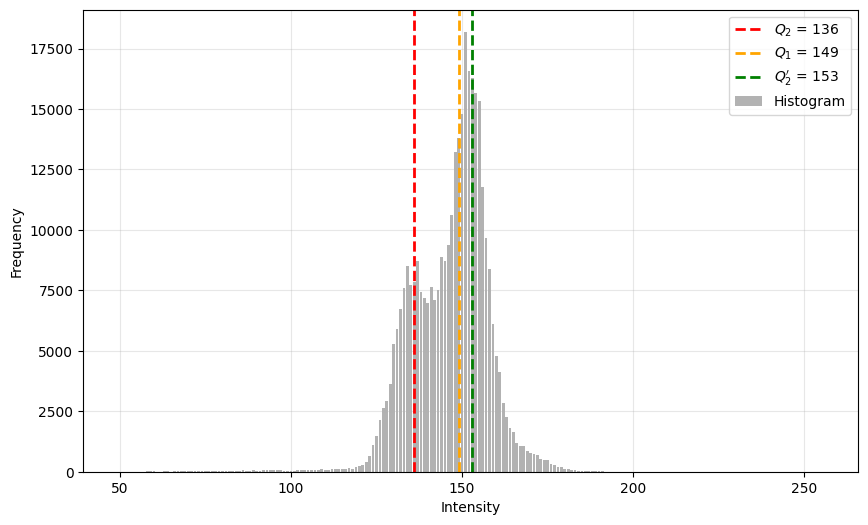

27
48.60716316088687 0
[171 171 170 ...   0   0   0]
k = 426, p = 337, q = 1554, l = 354, s = 345


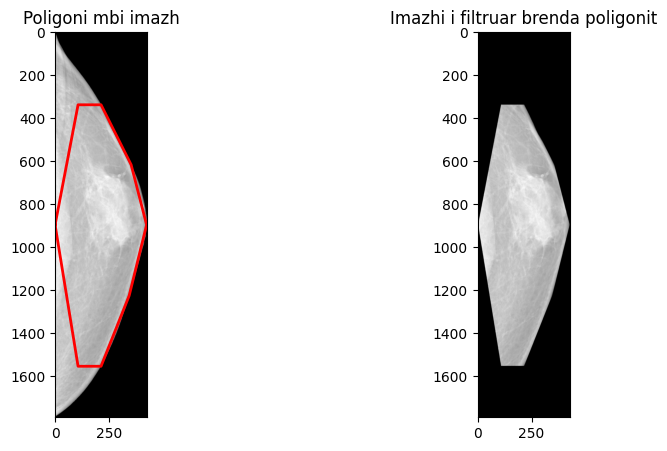

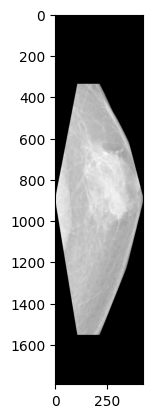

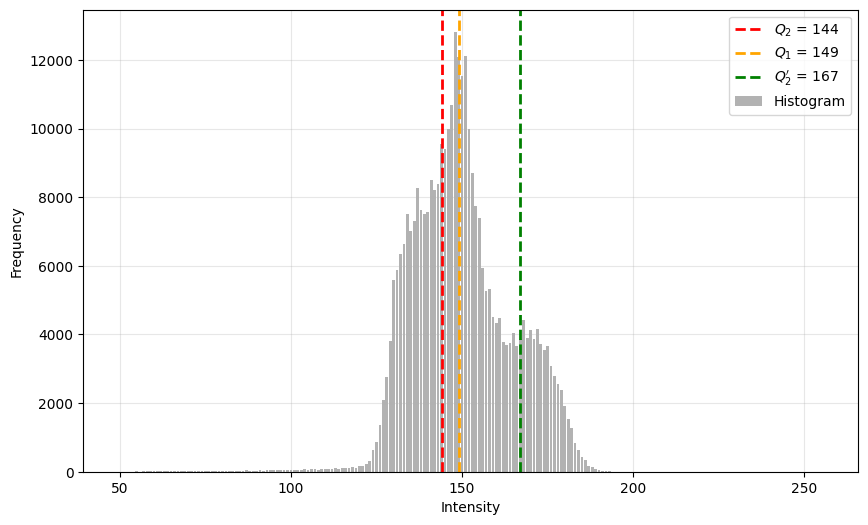

(0.38496559067081676, 0.0007642372122031992, 0.0007323882595232445, 4.66504482595205, 4.943455303863792, 4.943455303863792, 4.071270618921234, 4.417265434483677, 2.3123080694704194, 4.039511037421028, 4.071270618921234, 0.5234704827604953, 1.007862234118435, 167)


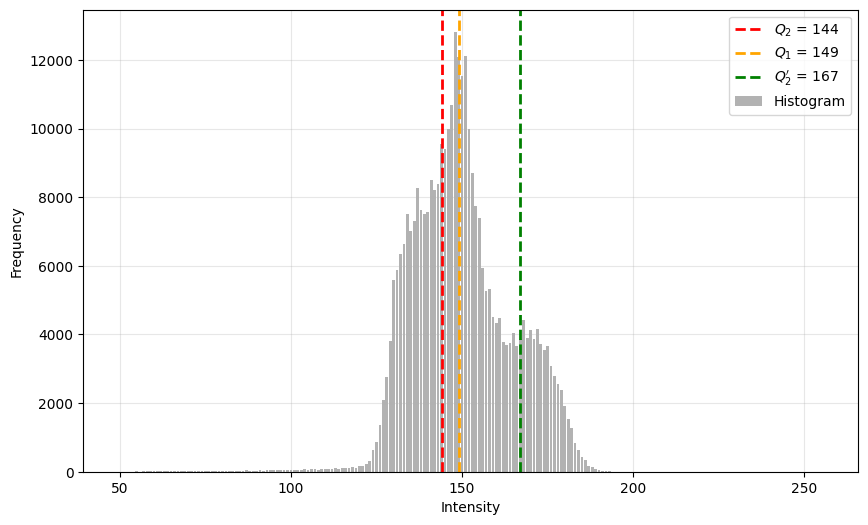

28
100.0 0
[0 0 0 ... 0 0 0]
k = 1444, p = 462, q = 2577, l = 1282, s = 1275


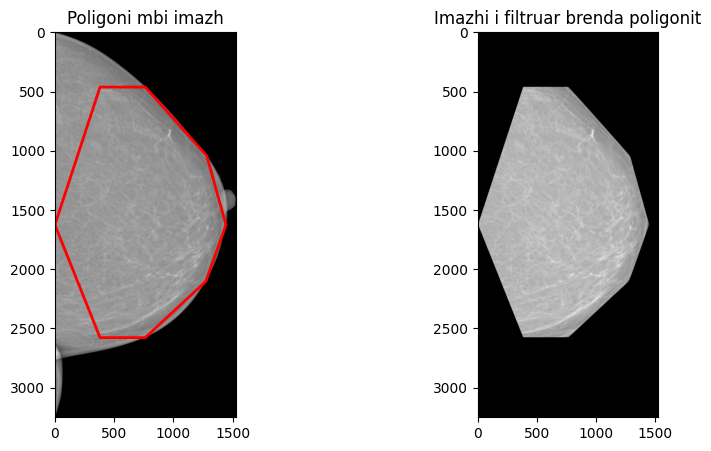

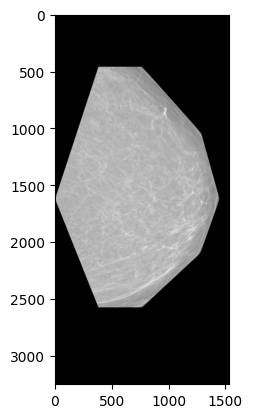

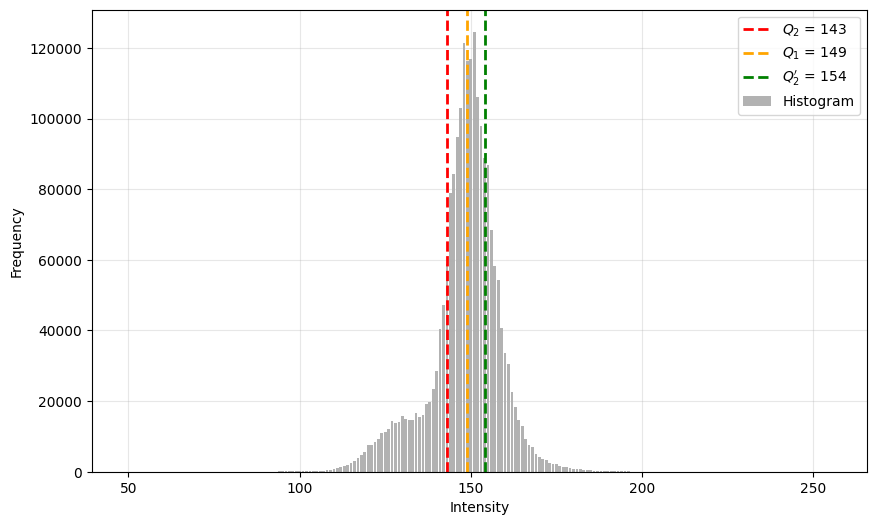

(0.32044348325931254, 0.00010539469604736806, 8.979978429146552e-05, 4.484494301305068, 4.0452804479409075, 4.0452804479409075, 3.832564455139491, 4.633677243147827, 2.567437031505081, 2.3115236414736495, 3.832564455139491, 0.5540819735128826, 1.6580252031063558, 154)


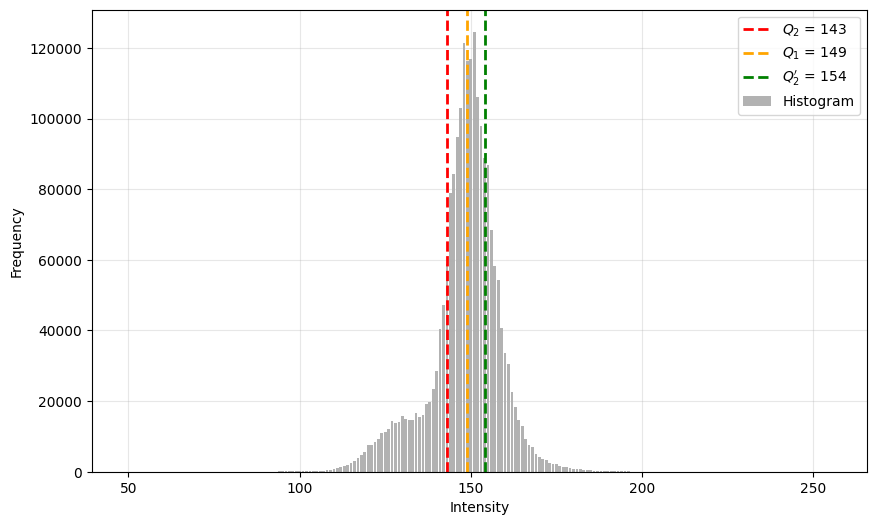

29
18.362706083001708 0
[0 0 0 ... 0 0 0]
k = 1523, p = 462, q = 2459, l = 1276, s = 1404


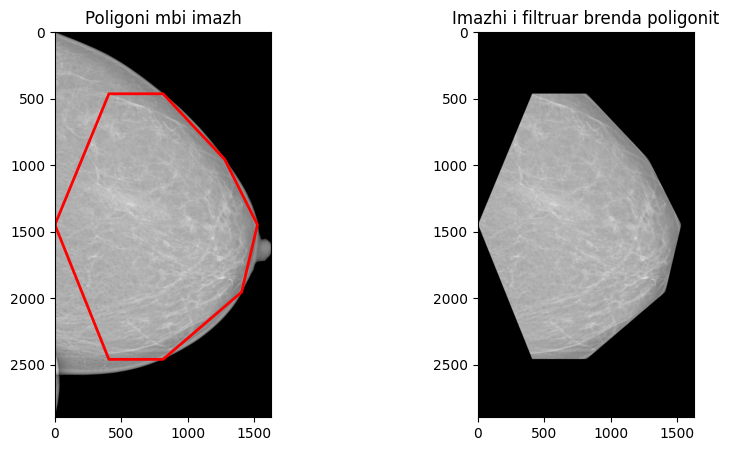

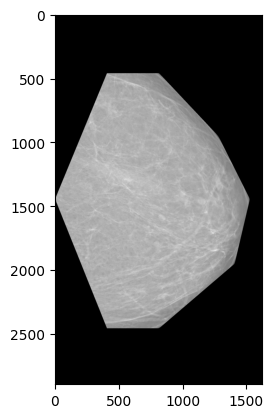

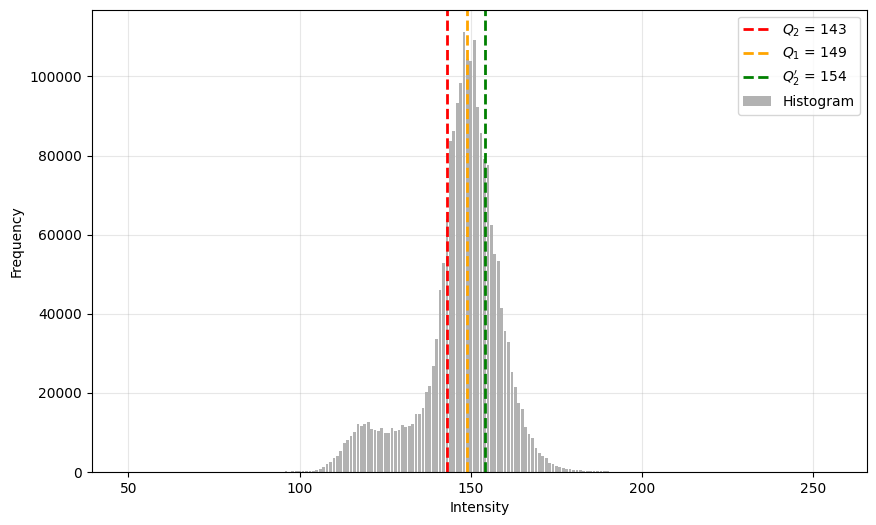

(0.31345436059452403, 9.57535902832496e-05, 8.622722541273543e-05, 4.674212942937426, 4.102971182526275, 4.102971182526275, 3.8525309030336157, 4.815779374842643, 2.5776118787914704, 2.311717070911804, 3.8525309030336157, 0.5352429333155849, 1.6665235341771618, 154)


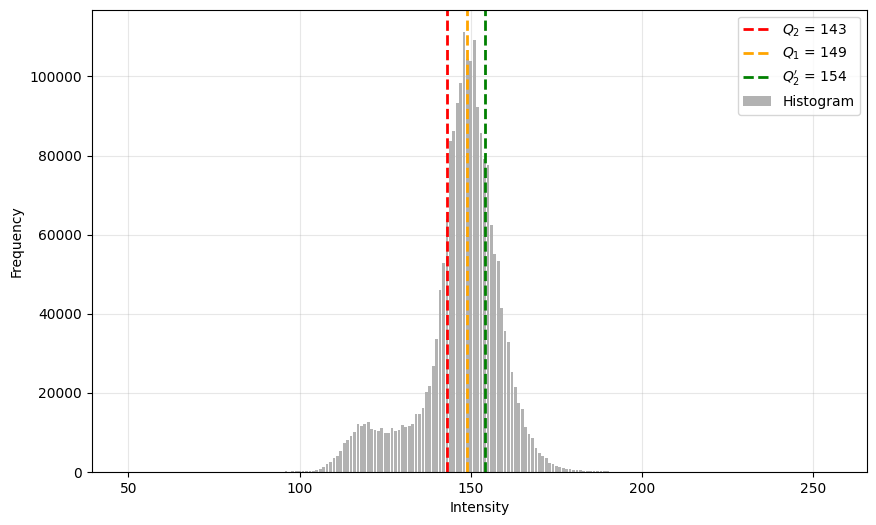

30
100.0 0
[0 0 0 ... 0 0 0]
k = 870, p = 886, q = 2700, l = 716, s = 955


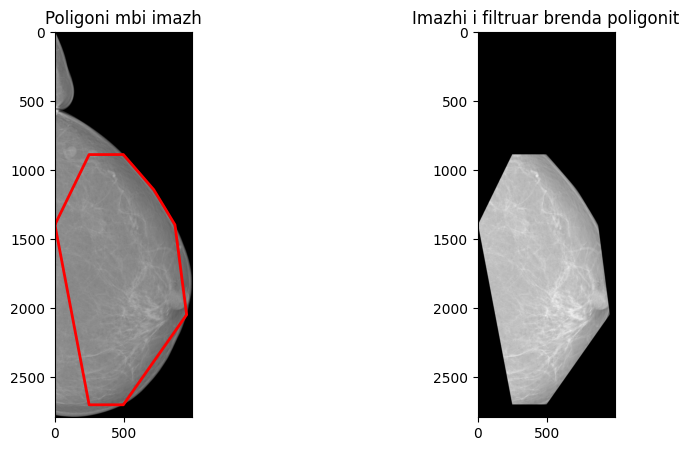

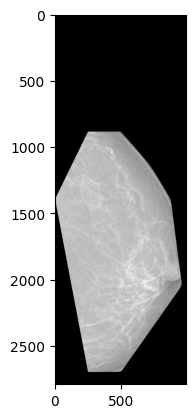

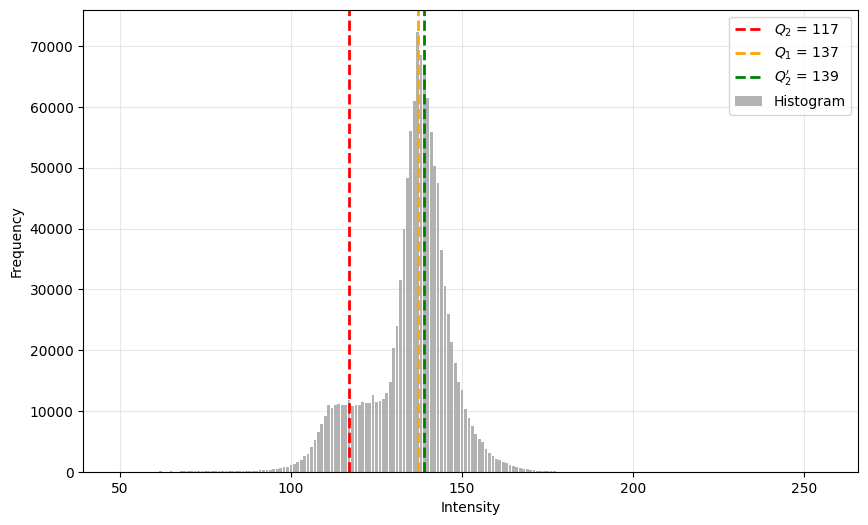

(0.37899392804833804, 0.0003361277251993204, 0.00011093048995411815, 4.739864158236814, 4.064442417212673, 4.064442417212673, 3.977451185141165, 4.225814015006794, 3.9492831705323526, 0.9998378380343864, 3.977451185141165, 0.9345615203384675, 3.9780962810535008, 139)


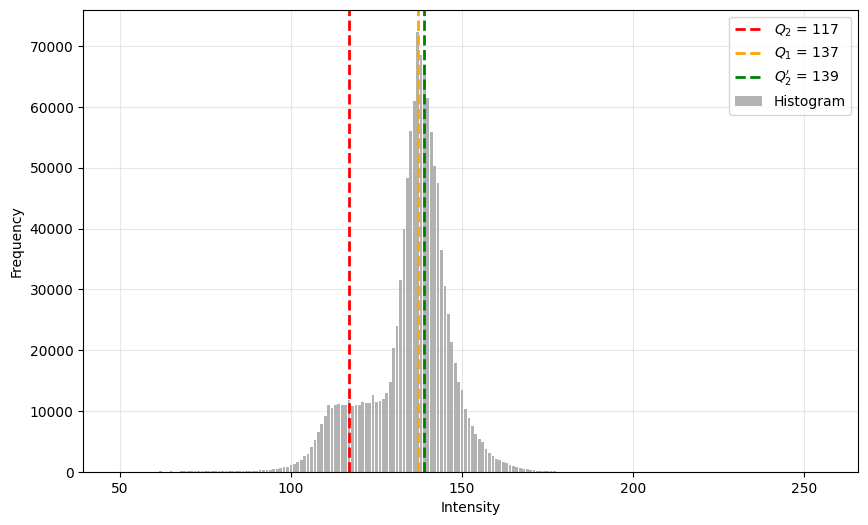

31
18.959636156907333 0
[0 0 0 ... 0 0 0]
k = 824, p = 992, q = 2738, l = 687, s = 925


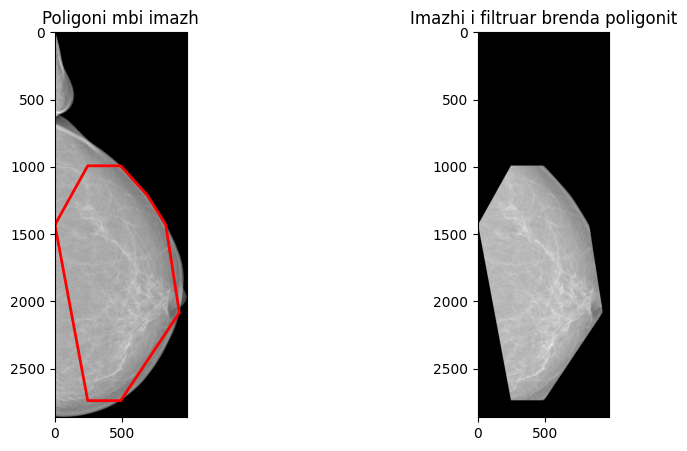

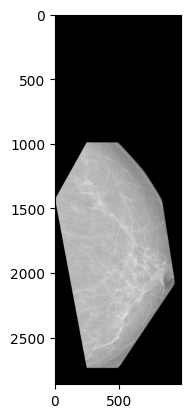

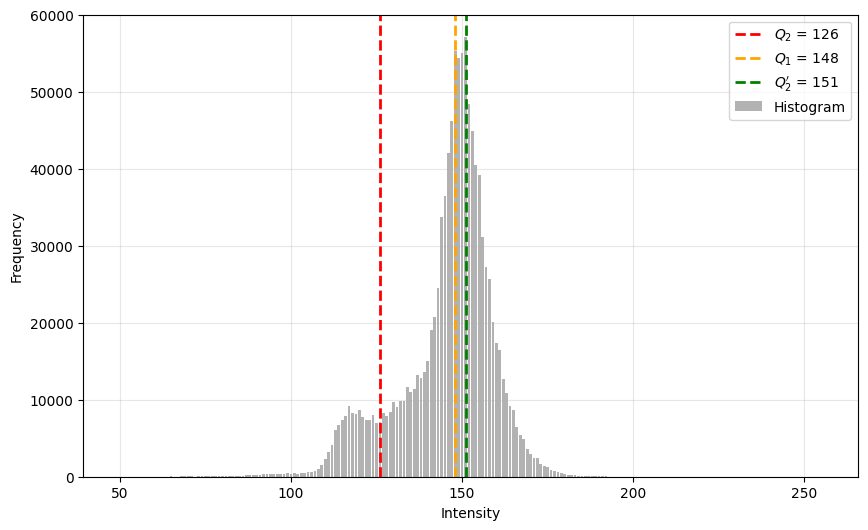

(0.38527935556578646, 0.00046488252293001636, 0.00021449212930554809, 5.026325026573495, 4.208067214971555, 4.208067214971555, 4.072323511631109, 4.554886414096183, 4.155330526100937, 1.5846281822747879, 4.072323511631109, 0.9122797251850837, 2.569892140745061, 151)


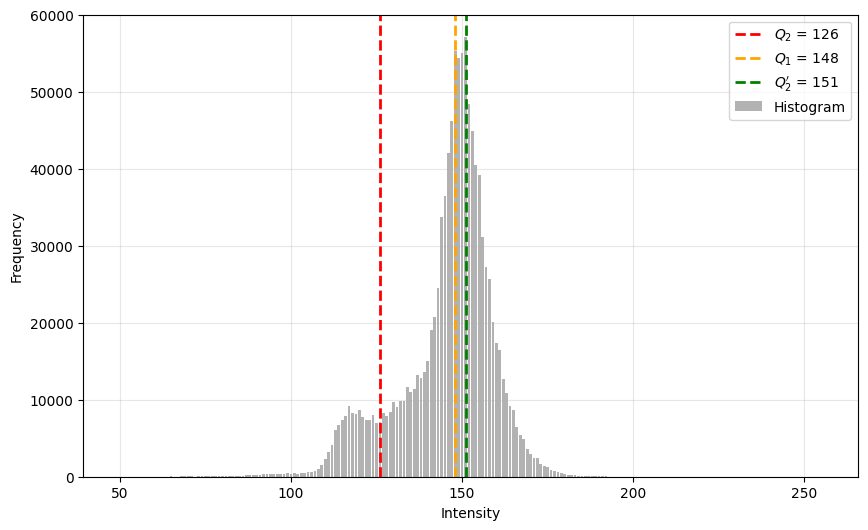

32
100.0 0
[0 0 0 ... 0 0 0]
k = 508, p = 735, q = 2215, l = 423, s = 551


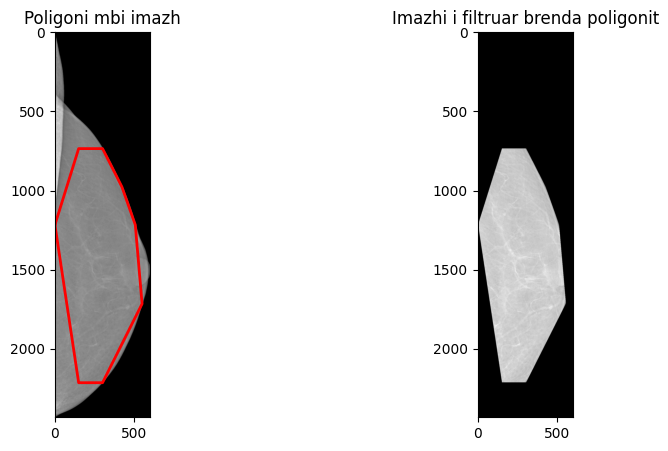

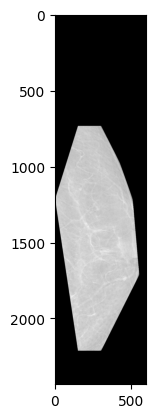

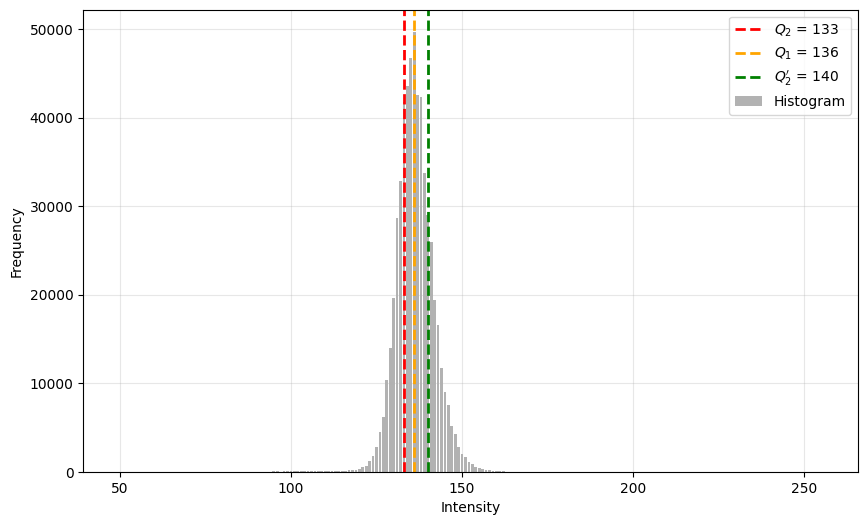

(0.38278959757894004, 9.911364086880186e-05, 8.495530112229492e-05, 3.392253169896596, 3.504461158267596, 3.504461158267596, 3.243588181960193, 3.078947078901183, 1.5828494681582062, 1.9820598956316622, 3.243588181960193, 0.5140879097938555, 1.6364733422581534, 140)


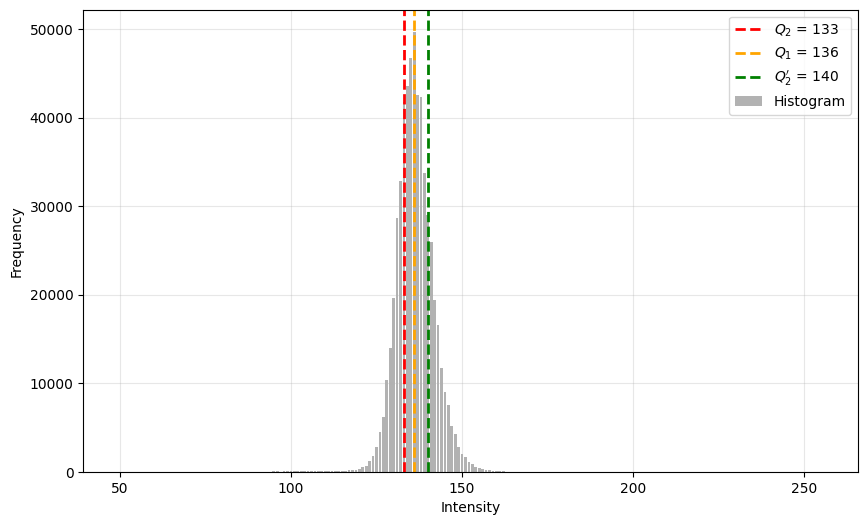

33
42.66628766344514 0
[0 0 0 ... 0 0 0]
k = 655, p = 372, q = 1718, l = 529, s = 589


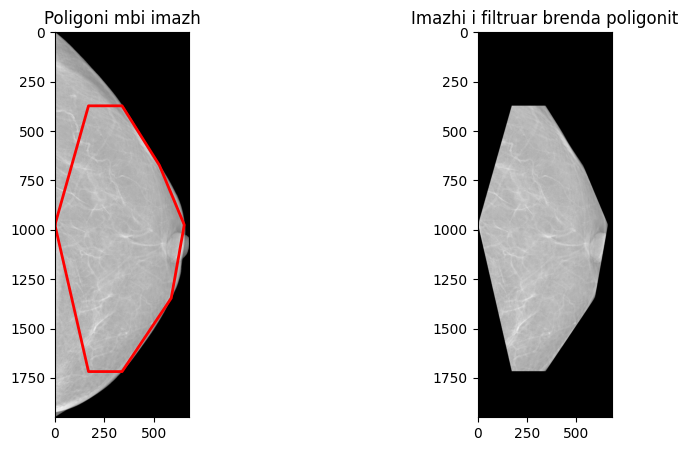

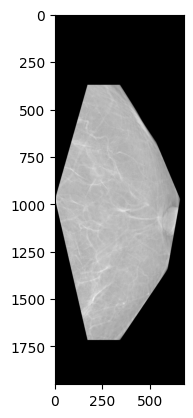

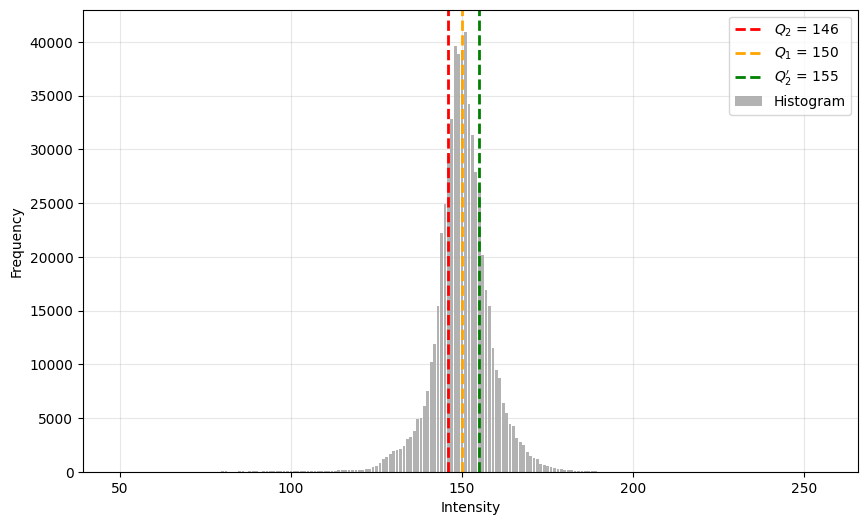

(0.3396752731158837, 0.0005051468103826069, 0.0004850828655350297, 4.0025515059404375, 3.9481869422798916, 3.9481869422798916, 3.8365212771632486, 3.920611124701345, 1.995970138053295, 2.30380438307997, 3.8365212771632486, 0.5090966878806016, 1.6652981934317619, 155)


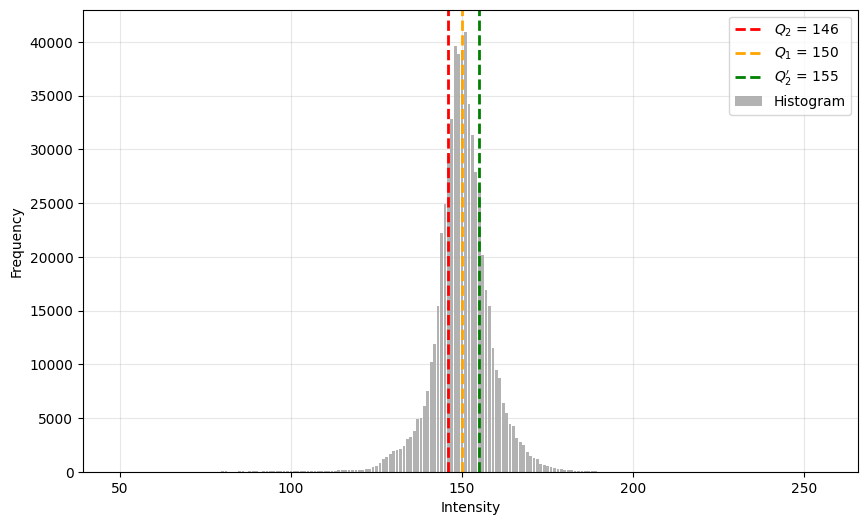

34
33.257532689027855 0
[  0   0   0 ... 244 243 228]
k = 986, p = 239, q = 1771, l = 939, s = 819


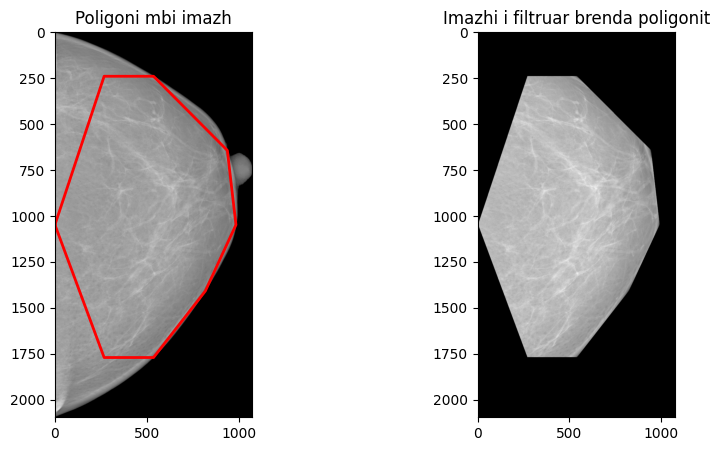

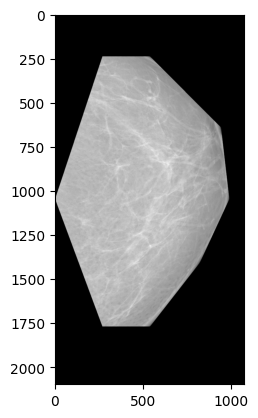

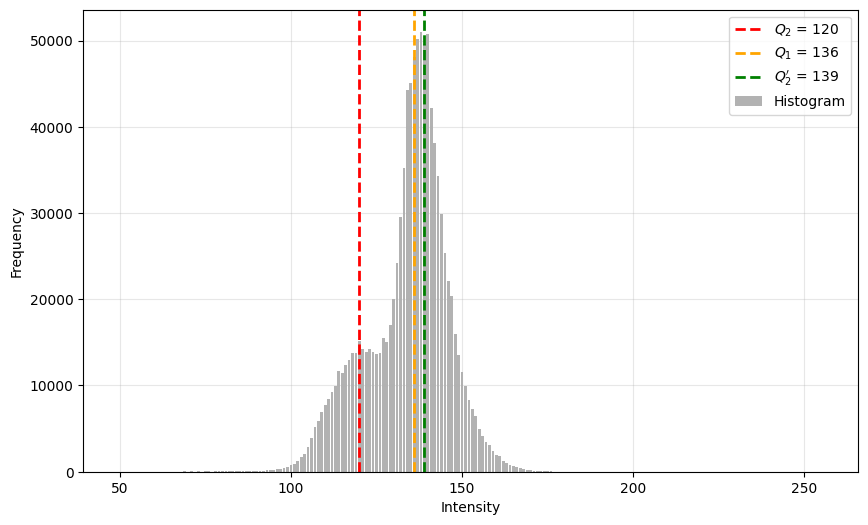

(0.4047353716360935, 0.00020411476376326864, 9.398772843052836e-05, 4.824857422032164, 4.187996036230336, 4.187996036230336, 4.032895406349577, 4.2290285973385116, 3.8226536025918225, 1.5848686501845233, 4.032895406349577, 0.9039081941885103, 2.5446243799951715, 139)


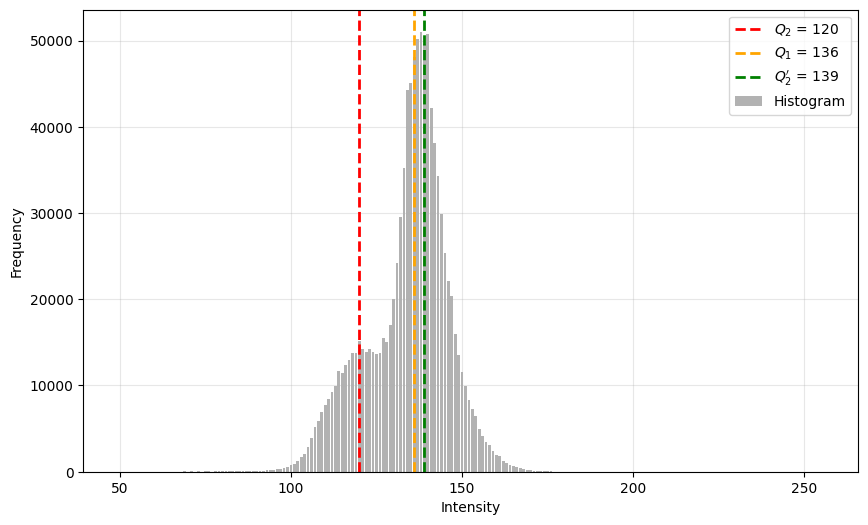

35
100.0 0
[0 0 0 ... 0 0 0]
k = 1257, p = 324, q = 2427, l = 1095, s = 1123


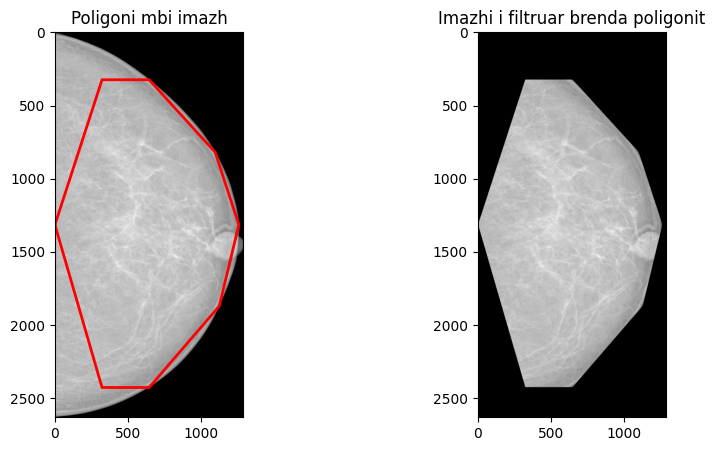

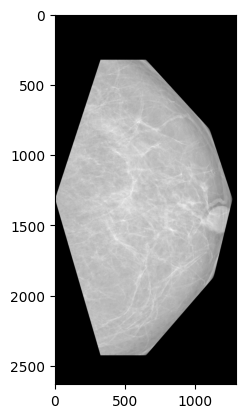

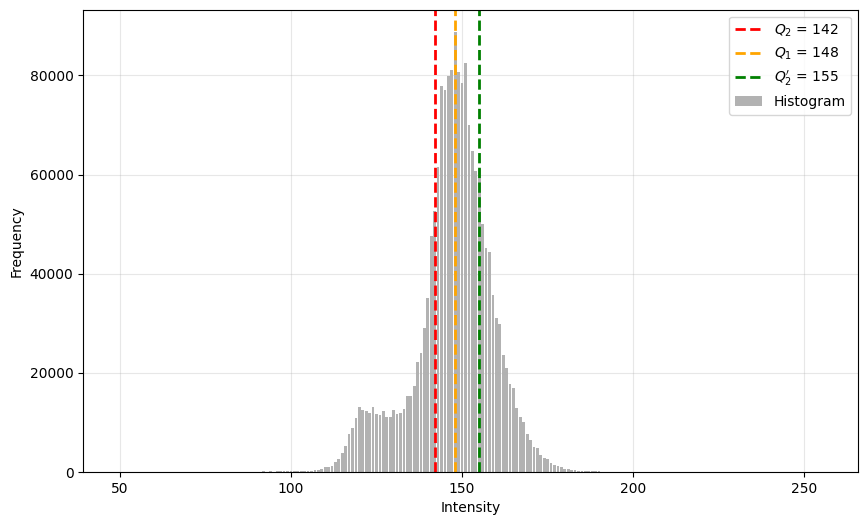

(0.33319978609493406, 0.00012094168148339076, 9.795862971747418e-05, 4.63501992427732, 4.31534889308837, 4.31534889308837, 4.00400286139154, 4.676576688899396, 2.57665667317029, 2.7966811709186734, 4.00400286139154, 0.5509706874445996, 1.4316980079914785, 155)


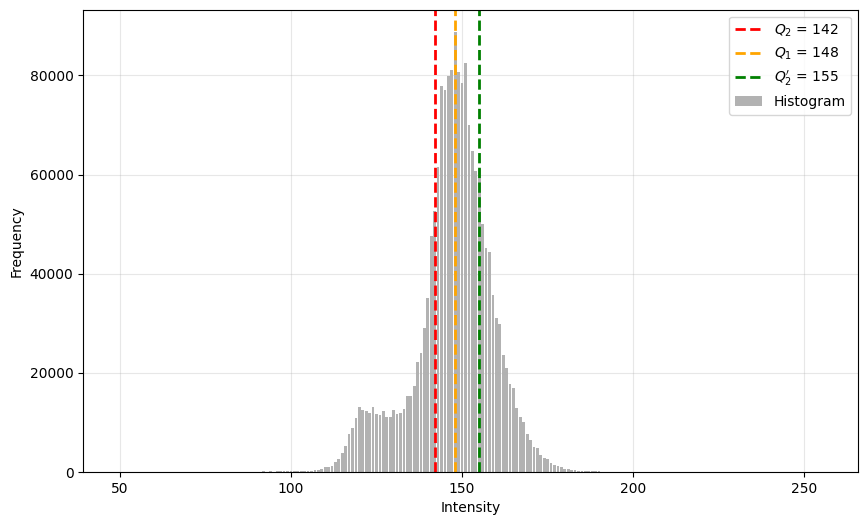

36
14.58214894826606 0
[124 126 123 ...   0   0   0]
k = 1352, p = 469, q = 2636, l = 1150, s = 1297


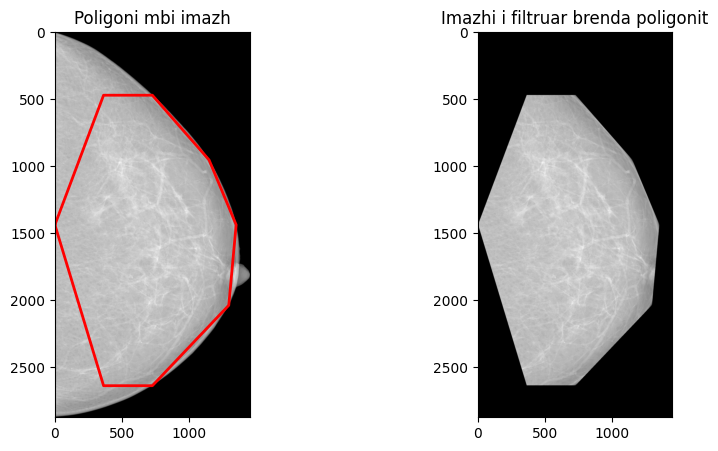

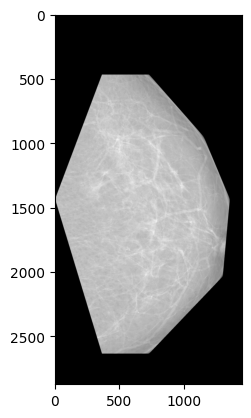

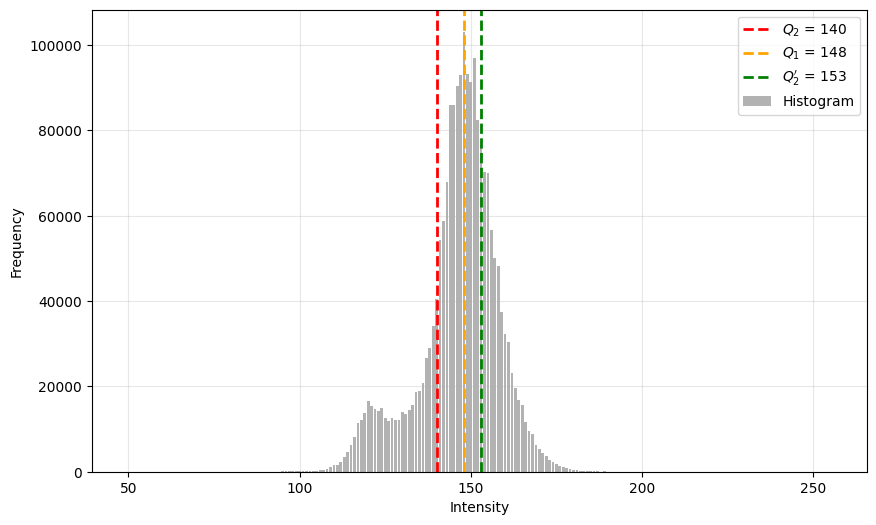

(0.3292921401310621, 0.00010983986122435155, 8.951784719738976e-05, 4.696818218914211, 4.205773879727968, 4.205773879727968, 3.952975322196472, 4.7741593783560266, 2.9687398085229715, 2.3165836305583833, 3.952975322196472, 0.6218350861896135, 1.706381444663691, 153)


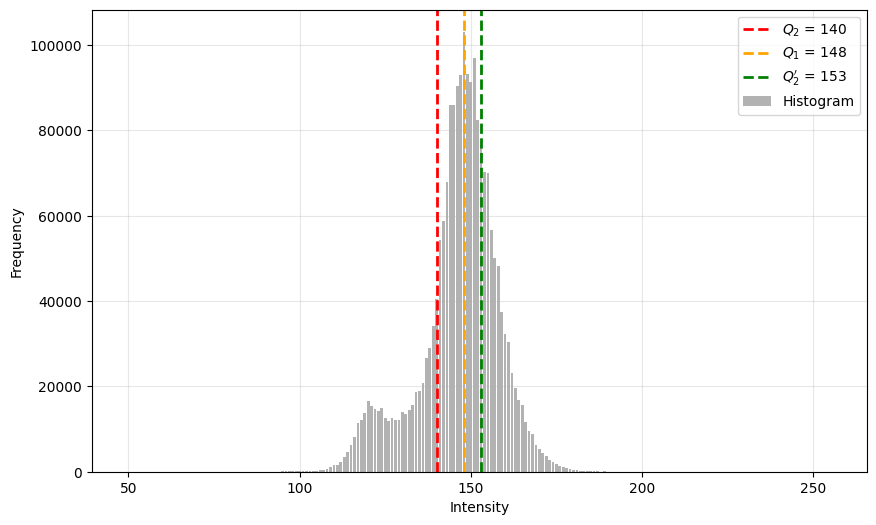

37
100.0 0
[0 0 0 ... 0 0 0]
k = 1019, p = 573, q = 2492, l = 845, s = 1014


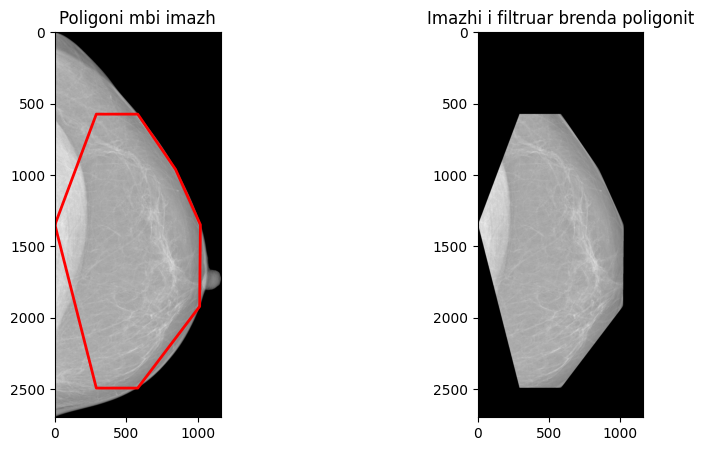

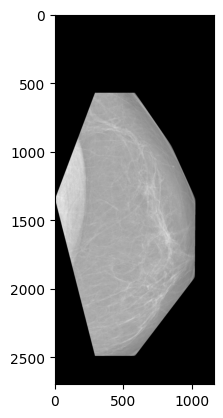

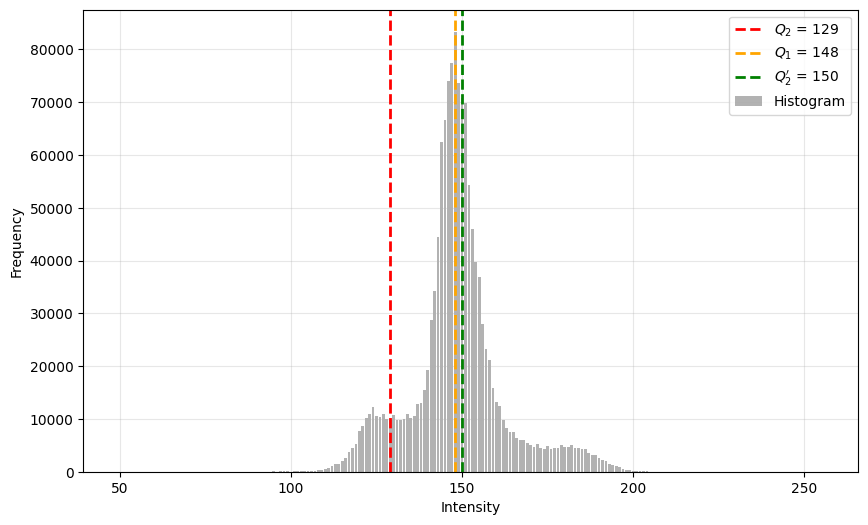

(0.26414404645708656, 0.00014901602853656945, 7.164232141181225e-05, 4.5064866178531275, 4.648606789948109, 4.648606789948109, 4.697135363574085, 4.091639513339602, 3.787196549306636, 0.9997255017594759, 4.697135363574085, 0.9255938938314536, 4.6984250729898545, 150)


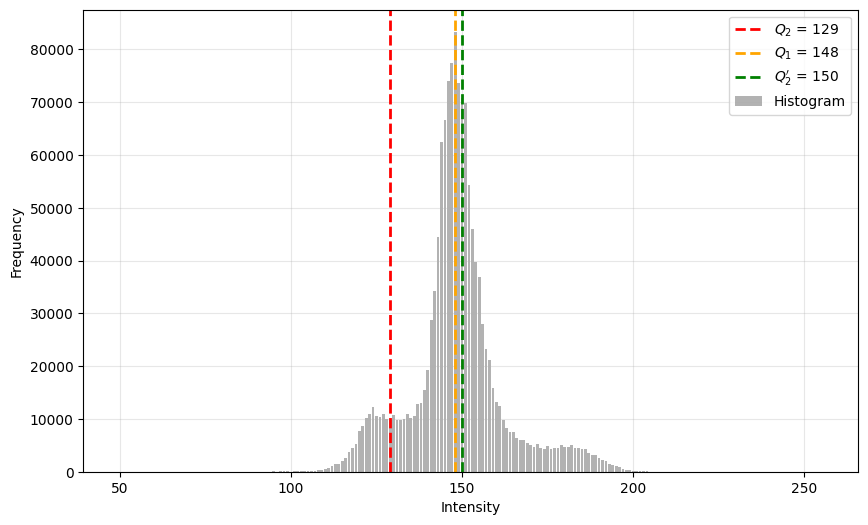

38
11.171119954519613 0
[128 128 132 ...   0   0   0]
k = 1330, p = 633, q = 2542, l = 1061, s = 1146


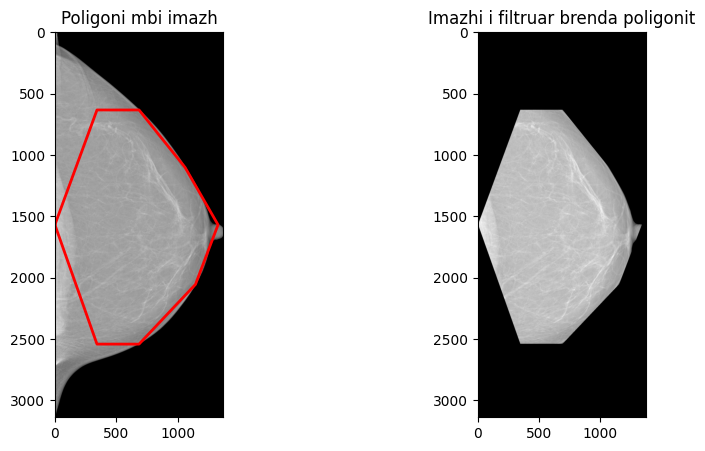

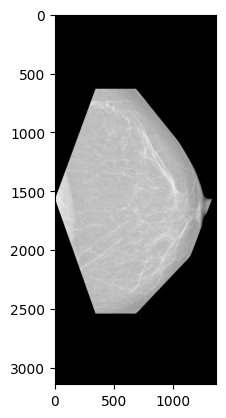

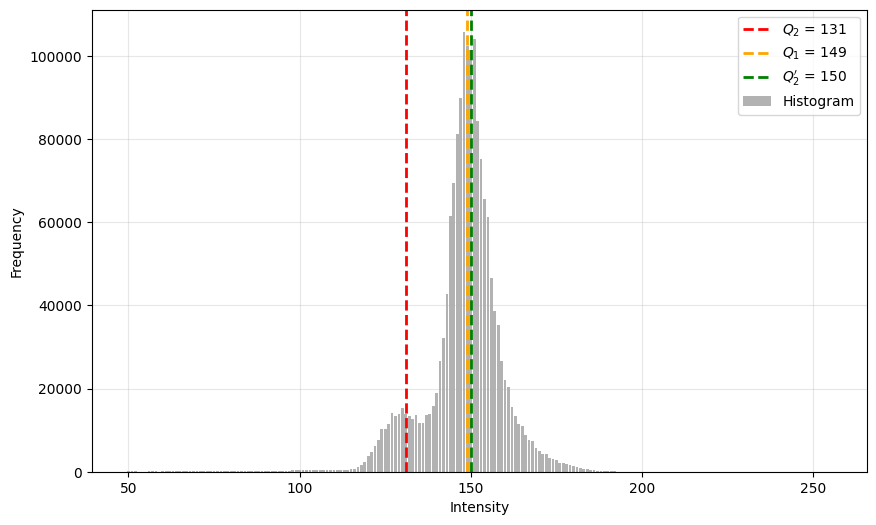

(0.29563154196888036, 0.0011541179428696722, 0.0006357479840175221, 4.459261645928961, 4.107372123449634, 4.107372123449634, 4.07575747821831, 4.313047038672182, 3.7173684907227975, 0.0, 4.07575747821831, 0.861889160352684, 6, 150)


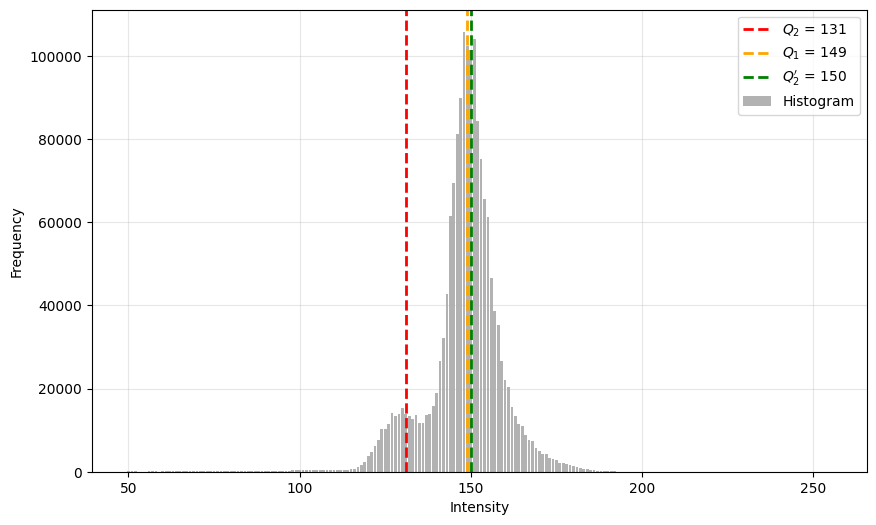

39
100.0 0
[0 0 0 ... 0 0 0]
k = 1254, p = 251, q = 2123, l = 1046, s = 1093


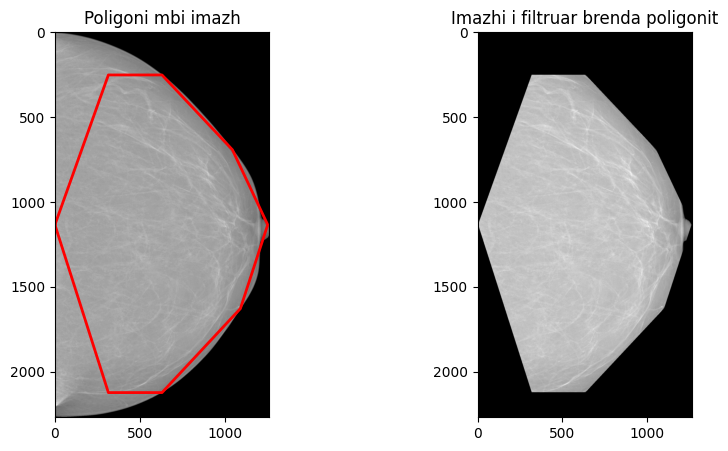

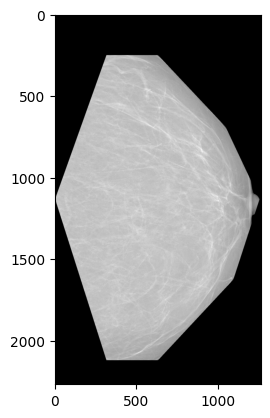

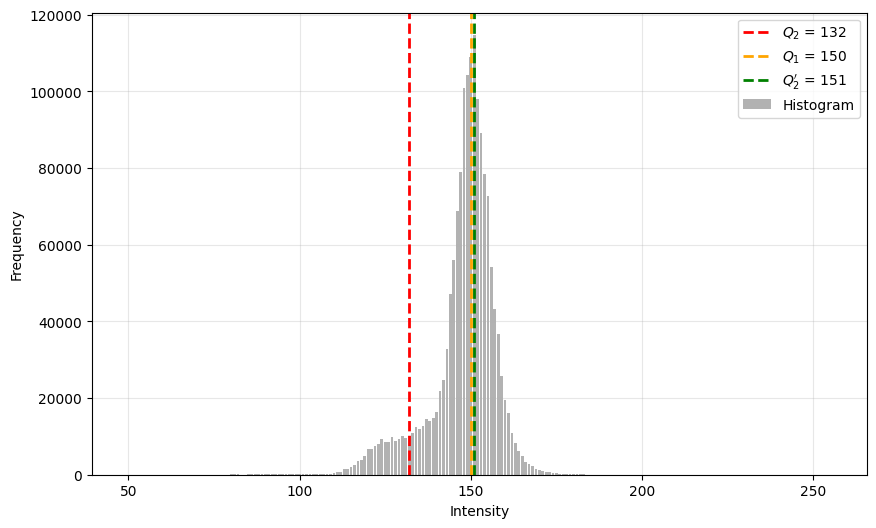

(0.32991199555983763, 0.0004739073662346043, 0.0002722348782032498, 4.459536627689053, 3.5969596054629434, 3.5969596054629434, 3.534166107012227, 4.4892091087765005, 3.711133734036172, 0.0, 3.534166107012227, 0.826678740979302, 6, 151)


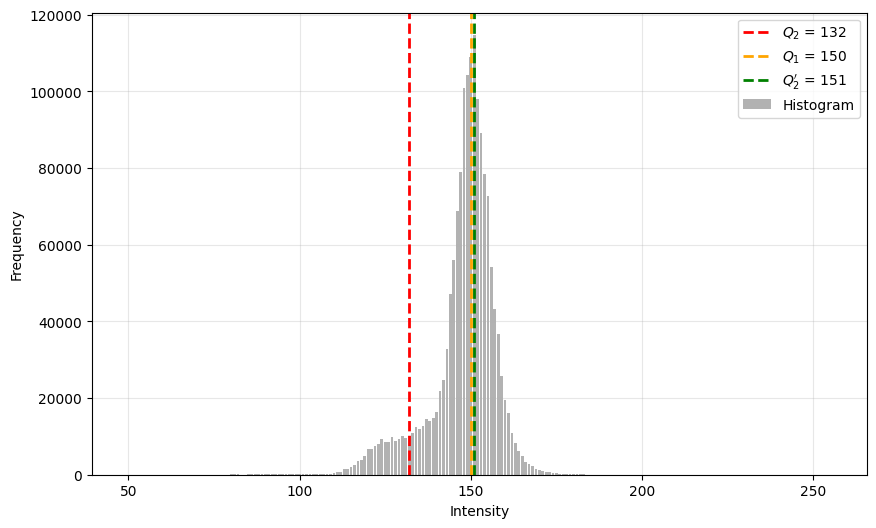

40
24.189880613985217 0
[  0   0   0 ... 124 123 124]
k = 1218, p = 282, q = 2048, l = 1023, s = 1101


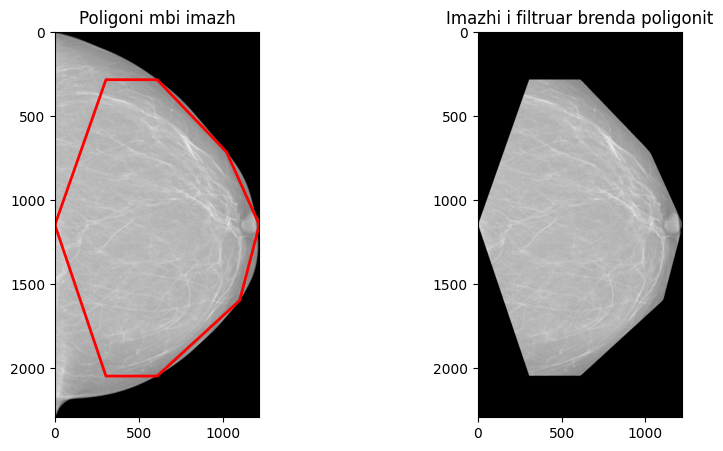

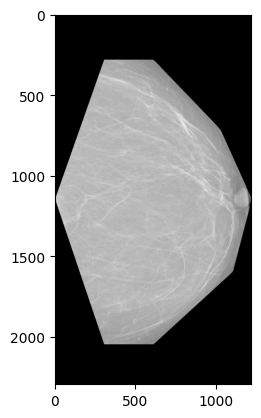

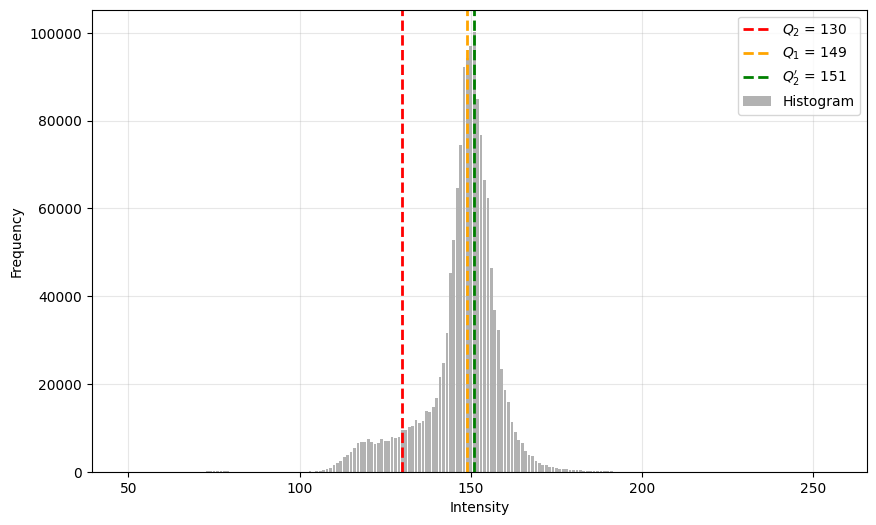

(0.3294223801605988, 0.00037343197540093106, 0.00014842396118476208, 4.560322259858723, 3.834115891967929, 3.834115891967929, 3.7349216379843058, 4.484234868743037, 3.7828667628631734, 0.9998009029087276, 3.7349216379843058, 0.843592468635243, 3.735665398099034, 151)


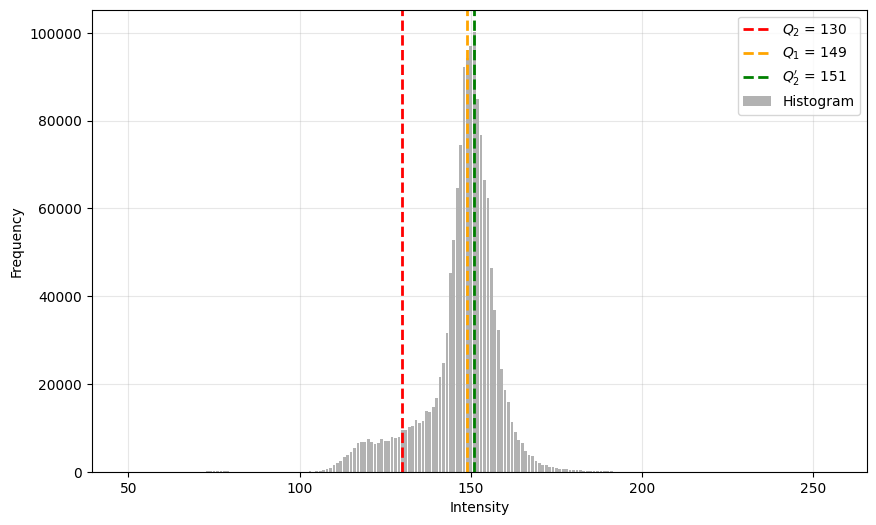

41


In [17]:
# Directory containing DICOM images
dicom_directory = 'E:/PhD/V_M_Dataset/images/'
k=0
A = []

# Iterate through each image in the dataframe
for i, row in Dens_A.iloc[:].iterrows():
    
    k+=1
    # Construct the path to the DICOM image
    dicom_image_path = os.path.join(dicom_directory, row[0], row[2] + '.dicom')
        
    # Read the DICOM file
    dicom_data = pydicom.dcmread(dicom_image_path)
    dicom_pixels = dicom_data.pixel_array

    # Normalize the pixel values between 0 and 255
    normalized_pixels = ((dicom_pixels - np.min(dicom_pixels)) / 
                            (np.max(dicom_pixels) - np.min(dicom_pixels)) * 255).astype(np.uint8)
    #converti if image is negativ to positive
    image_positive = Check_for_negativ_image(normalized_pixels)
    # Apply custom preprocessing to clean the image
    clean_image_from_text = delete_text_writen_in_image(image_positive, window_size=(700, 700))
    
    if Dens_A['laterality'][i].upper() == "R":
        clean_image_from_text = cv2.flip(clean_image_from_text, 1) 
        

    image = crop_to_roi(clean_image_from_text, return_mask=False)
    image = vizato_poligon_dhe_mask(image)
    E = shannon_entropy(clean_image_from_text, bins=256)
    H = histogram(image)
    #H = threshold(H)
    plt.imshow(image, 'gray')
    plt.show()
    bm = bimodality(H)
    print(bm)
    bm, DOL1, DOL2, e1, e2, e3, e4, e__1, e__2, e__3, e__4, r_21, r__43, q2  = bimodality(H)
    bm2 , DOL1, DOL2, e11, e22 = bimodality2(H[:q2])

    A.append((bm, DOL1, DOL2, e1, e2, e3, e4, e__1, e__2, e__3, e__4, r_21, r__43, bm2 , DOL1, DOL2, e11, e22, E, e2/e1, e4/e3, e22/e11))
    print(k)
    

In [26]:
k=0
B = []

# Iterate through each image in the dataframe
for i, row in Dens_B.iloc[:].iterrows():
    
    k+=1
    # Construct the path to the DICOM image
    dicom_image_path = os.path.join(dicom_directory, row[0], row[2] + '.dicom')
        
    # Read the DICOM file
    dicom_data = pydicom.dcmread(dicom_image_path)
    dicom_pixels = dicom_data.pixel_array

    # Normalize the pixel values between 0 and 255
    normalized_pixels = ((dicom_pixels - np.min(dicom_pixels)) / 
                            (np.max(dicom_pixels) - np.min(dicom_pixels)) * 255).astype(np.uint8)
    #converti if image is negativ to positive
    image_positive = Check_for_negativ_image(normalized_pixels)
    # Apply custom preprocessing to clean the image
    clean_image_from_text = delete_text_writen_in_image(image_positive, window_size=(700, 700))
    
    if Dens_B['laterality'][i].upper() == "R":
        clean_image_from_text = cv2.flip(clean_image_from_text, 1) 
        

    image = crop_to_roi(clean_image_from_text, return_mask=False)
    image = vizato_poligon_dhe_mask(image)
    
    E = shannon_entropy(clean_image_from_text, bins=256)
    H = histogram(image)
    #H = threshold(H, 50)
    bm, DOL1, DOL2, e1, e2, e3, e4, e__1, e__2, e__3, e__4, r_21, r__43, q2  = bimodality(H)
    bm2 , DOL1, DOL2, e11, e22 = bimodality2(H[:q2])

    B.append((bm, DOL1, DOL2, e1, e2, e3, e4, e__1, e__2, e__3, e__4, r_21, r__43, bm2 , DOL1, DOL2, e11, e22, E, e2/e1, e4/e3, e22/e11))
    print(k)
    
    
 

1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144
145
146
147
148
149
150
151
152
153
154
155
156
157
158
159
160
161
162
163
164
165
166
167
168
169
170
171
172
173
174
175
176
177
178
179
180
181
182
183
184
185
186
187
188
189
190
191
192
193
194
195
196
197
198
199
200
201
202
203
204
205
206
207
208
209
210
211
212
213
214
215
216
217
218
219
220
221
222
223
224
225
226
227
228
229
230
231
232
233
234
235
236
237
238
239
240
241
242
243
244
245
246
247
248
249
250
251
252
253
254
255
256
257
258
259
260
261
262
263
264
265
266
267
268
269
270
271
272
273
274
275
276
277


In [27]:
k=0
C = []

for i, row in Dens_C.iloc[:].iterrows():
    
    k+=1
    dicom_image_path = os.path.join(dicom_directory, row[0], row[2] + '.dicom')
        
    dicom_data = pydicom.dcmread(dicom_image_path)
    dicom_pixels = dicom_data.pixel_array

    normalized_pixels = ((dicom_pixels - np.min(dicom_pixels)) / 
                            (np.max(dicom_pixels) - np.min(dicom_pixels)) * 255).astype(np.uint8)
    image_positive = Check_for_negativ_image(normalized_pixels)
    clean_image_from_text = delete_text_writen_in_image(image_positive, window_size=(700, 700))
    
    if Dens_C['laterality'][i].upper() == "R":
        clean_image_from_text = cv2.flip(clean_image_from_text, 1) 
        

    image = crop_to_roi(clean_image_from_text, return_mask=False)
    image = vizato_poligon_dhe_mask(image)
    
    E = shannon_entropy(clean_image_from_text, bins=256)
    H = histogram(image)
    #H = threshold(H, 50)
    bm, DOL1, DOL2, e1, e2, e3, e4, e__1, e__2, e__3, e__4, r_21, r__43, q2  = bimodality(H)
    bm2 , DOL1, DOL2, e11, e22 = bimodality2(H[:q2])

    C.append((bm, DOL1, DOL2, e1, e2, e3, e4, e__1, e__2, e__3, e__4, r_21, r__43, bm2 , DOL1, DOL2, e11, e22, E, e2/e1, e4/e3, e22/e11))
    print(k)
    
    
 

1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144
145
146
147
148
149
150
151
152
153
154
155
156
157
158
159
160
161
162
163
164
165
166
167
168
169
170
171
172
173
174
175
176
177
178
179
180
181
182
183
184
185
186
187
188
189
190
191
192
193
194
195
196
197
198
199
200
201
202
203
204
205
206
207
208
209
210
211
212
213
214
215
216
217
218
219
220
221
222
223
224
225
226
227
228
229
230
231
232
233
234
235
236
237
238
239
240
241
242
243
244
245
246
247
248
249
250
251
252
253
254
255
256
257
258
259
260
261
262
263
264
265
266
267
268
269
270
271
272
273
274
275
276
277


2919
2920
2921
2922
2923
2924
2925
2926
2927
2928
2929
2930
2931
2932
2933
2934
2935
2936
2937
2938
2939
2940
2941
2942
2943
2944
2945
2946
2947
2948
2949
2950
2951
2952
2953
2954
2955
2956
2957
2958
2959
2960
2961
2962
2963
2964
2965
2966
2967
2968
2969
2970
2971
2972
2973
2974
2975
2976
2977
2978
2979
2980
2981
2982
2983
2984
2985
2986
2987
2988
2989
2990
2991
2992
2993
2994
2995
2996
2997
2998
2999
3000
3001
3002
3003
3004
3005
3006
3007
3008
3009
3010
3011
3012
3013
3014
3015
3016
3017
3018
3019
3020
3021
3022
3023
3024
3025
3026
3027
3028
3029
3030
3031
3032
3033
3034
3035
3036
3037
3038
3039
3040
3041
3042
3043
3044
3045
3046
3047
3048
3049
3050
3051
3052
3053
3054
3055
3056
3057
3058
3059
3060
3061
3062
3063
3064
3065
3066
3067
3068
3069
3070
3071
3072
3073
3074
3075
3076
3077
3078
3079
3080
3081
3082
3083
3084
3085
3086
3087
3088
3089
3090
3091
3092
3093
3094
3095
3096
3097
3098
3099
3100
3101
3102
3103
3104
3105
3106
3107
3108
3109
3110
3111
3112
3113
3114
3115
3116
3117
3118


5776
5777
5778
5779
5780
5781
5782
5783
5784
5785
5786
5787
5788
5789
5790
5791
5792
5793
5794
5795
5796
5797
5798
5799
5800
5801
5802
5803
5804
5805
5806
5807
5808
5809
5810
5811
5812
5813
5814
5815
5816
5817
5818
5819
5820
5821
5822
5823
5824
5825
5826
5827
5828
5829
5830
5831
5832
5833
5834
5835
5836
5837
5838
5839
5840
5841
5842
5843
5844
5845
5846
5847
5848
5849
5850
5851
5852
5853
5854
5855
5856
5857
5858
5859
5860
5861
5862
5863
5864
5865
5866
5867
5868
5869
5870
5871
5872
5873
5874
5875
5876
5877
5878
5879
5880
5881
5882
5883
5884
5885
5886
5887
5888
5889
5890
5891
5892
5893
5894
5895
5896
5897
5898
5899
5900
5901
5902
5903
5904
5905
5906
5907
5908
5909
5910
5911
5912
5913
5914
5915
5916
5917
5918
5919
5920
5921
5922
5923
5924
5925
5926
5927
5928
5929
5930
5931
5932
5933
5934
5935
5936
5937
5938
5939
5940
5941
5942
5943
5944
5945
5946
5947
5948
5949
5950
5951
5952
5953
5954


In [28]:
k=0
D = []

for i, row in Dens_D.iloc[:].iterrows():
    
    k+=1
    dicom_image_path = os.path.join(dicom_directory, row[0], row[2] + '.dicom')
        
    dicom_data = pydicom.dcmread(dicom_image_path)
    dicom_pixels = dicom_data.pixel_array

    normalized_pixels = ((dicom_pixels - np.min(dicom_pixels)) / 
                            (np.max(dicom_pixels) - np.min(dicom_pixels)) * 255).astype(np.uint8)
    image_positive = Check_for_negativ_image(normalized_pixels)
    clean_image_from_text = delete_text_writen_in_image(image_positive, window_size=(700, 700))
    
    if Dens_D['laterality'][i].upper() == "R":
        clean_image_from_text = cv2.flip(clean_image_from_text, 1) 
        

    image = crop_to_roi(clean_image_from_text, return_mask=False)
    image = vizato_poligon_dhe_mask(image)
    
    E = shannon_entropy(clean_image_from_text, bins=256)
    H = histogram(image)
    #H = threshold(H, 50)
    bm, DOL1, DOL2, e1, e2, e3, e4, e__1, e__2, e__3, e__4, r_21, r__43, q2  = bimodality(H)
    bm2 , DOL1, DOL2, e11, e22 = bimodality2(H[:q2])

    D.append((bm, DOL1, DOL2, e1, e2, e3, e4, e__1, e__2, e__3, e__4, r_21, r__43, bm2 , DOL1, DOL2, e11, e22, E, e2/e1, e4/e3, e22/e11))
    print(k)
    
    
 

1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144
145
146
147
148
149
150
151
152
153
154
155
156
157
158
159
160
161
162
163
164
165
166
167
168
169
170
171
172
173
174
175
176
177
178
179
180
181
182
183
184
185
186
187
188
189
190
191
192
193
194
195
196
197
198
199
200
201
202
203
204
205
206
207
208
209
210
211
212
213
214
215
216
217
218
219
220
221
222
223
224
225
226
227
228
229
230
231
232
233
234
235
236
237
238
239
240
241
242
243
244
245
246
247
248
249
250
251
252
253
254
255
256
257
258
259
260
261
262
263
264
265
266
267
268
269
270
271
272
273
274
275
276
277


In [29]:
A = np.array(A)
B = np.array(B)
C = np.array(C)
D = np.array(D)

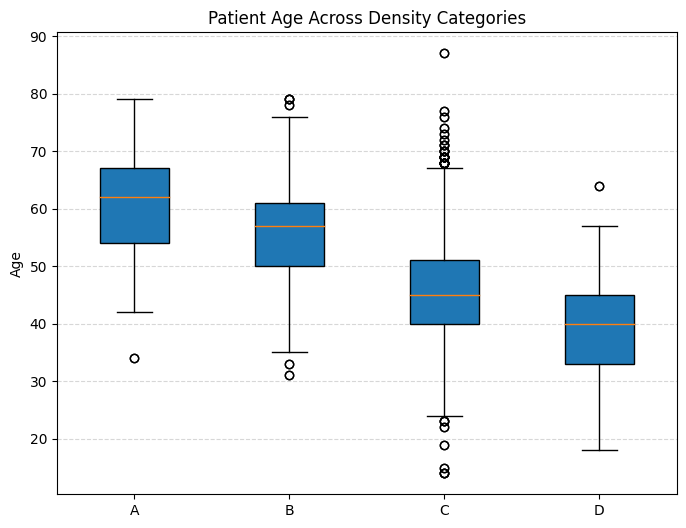

In [30]:
A4 = []
# Iterate through each image in the dataframe
for i, row in Dens_A.iloc[:].iterrows():
    age_str = metadata["Patient's Age"][i]  # e.g. '053Y'
    # Keep only digits
    age_clean = ''.join(filter(str.isdigit, age_str))
    # Convert to integer
    age_int = int(age_clean)
    A4.append(age_int)
    
B4 = []
# Iterate through each image in the dataframe
for i, row in Dens_B.iloc[:].iterrows():
    age_str = metadata["Patient's Age"][i]  # e.g. '053Y'
    # Keep only digits
    age_clean = ''.join(filter(str.isdigit, age_str))
    # Convert to integer
    age_int = int(age_clean)
    B4.append(age_int)
    
C4 = []
# Iterate through each image in the dataframe
for i, row in Dens_C.iloc[:].iterrows():
    age_str = metadata["Patient's Age"][i]  # e.g. '053Y'
    # Keep only digits
    age_clean = ''.join(filter(str.isdigit, age_str))
    # Convert to integer
    age_int = int(age_clean)
    C4.append(age_int)
    
D4 = []
# Iterate through each image in the dataframe
for i, row in Dens_D.iloc[:].iterrows():
    age_str = metadata["Patient's Age"][i]  # e.g. '053Y'
    # Keep only digits
    age_clean = ''.join(filter(str.isdigit, age_str))
    # Convert to integer
    age_int = int(age_clean)
    D4.append(age_int)
    
A4 = np.array(A4)
B4 = np.array(B4)
C4 = np.array(C4)
D4 = np.array(D4)
# Plotting the boxplot

plt.figure(figsize=(8, 6))
plt.boxplot([A4, B4, C4, D4], labels=['A', 'B', 'C', 'D'], patch_artist=True)

plt.title("Patient Age Across Density Categories")
plt.ylabel("Age")
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()


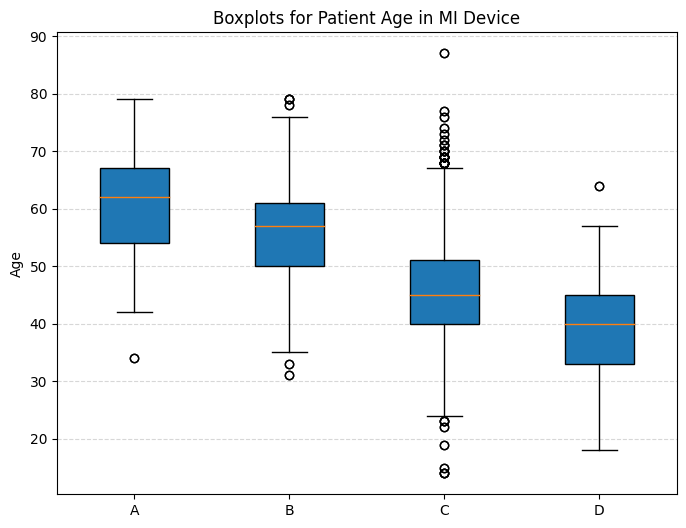

In [22]:
A4 = []
# Iterate through each image in the dataframe
for i, row in Dens_A.iloc[:].iterrows():
    age_str = metadata["Patient's Age"][i]  # e.g. '053Y'
    # Keep only digits
    age_clean = ''.join(filter(str.isdigit, age_str))
    # Convert to integer
    age_int = int(age_clean)
    A4.append(age_int)
    
B4, C4, D4 = [], [], []
for i, row in Dens_B.iloc[:].iterrows():
    age_str = metadata["Patient's Age"][i]  # e.g. '053Y'
    age_clean = ''.join(filter(str.isdigit, age_str))
    age_int = int(age_clean)
    B4.append(age_int)
    
for i, row in Dens_C.iloc[:].iterrows():
    age_str = metadata["Patient's Age"][i]  # e.g. '053Y'
    age_clean = ''.join(filter(str.isdigit, age_str))
    age_int = int(age_clean)
    C4.append(age_int)
    
for i, row in Dens_D.iloc[:].iterrows():
    age_str = metadata["Patient's Age"][i]  # e.g. '053Y'
    age_clean = ''.join(filter(str.isdigit, age_str))
    age_int = int(age_clean)
    D4.append(age_int)
    
A4 = np.array(A4)
B4 = np.array(B4)
C4 = np.array(C4)
D4 = np.array(D4)

plt.figure(figsize=(8, 6))
plt.boxplot([A4, B4, C4, D4], labels=['A', 'B', 'C', 'D'], patch_artist=True)

plt.title("Boxplots for Patient Age in MI Device")
plt.ylabel("Age")
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()


In [37]:
A_ = np.column_stack((A, A4))
B_ = np.column_stack((B, B4))
C_ = np.column_stack((C, C4))
D_ = np.column_stack((D, D4))


In [38]:
# Save each array
pd.DataFrame(A_).to_csv('A_2.csv', index=False)
pd.DataFrame(B_).to_csv('B_2.csv', index=False)
pd.DataFrame(C_).to_csv('C_2.csv', index=False)
pd.DataFrame(D_).to_csv('D_2.csv', index=False)

# Check shapes
print("A_array:", A_.shape)
print("B_array:", B_.shape)
print("C_array:", C_.shape)
print("D_array:", D_.shape)


A_array: (41, 23)
B_array: (635, 23)
C_array: (5954, 23)
D_array: (993, 23)
